In [ ]:
# =============================================================================
# Download CAMELS-GB v2 (UKCEH / EIDC) in Google Colab and save to Google Drive
# DOI: 10.5285/9a46d428-958f-4ac1-86eb-94eee70c0955
# =============================================================================
# Attribution (must be used in all outputs):
# "Contains data supplied by UK Centre for Ecology & Hydrology, British
#  Geological Survey, Environment Agency, Natural Resources Wales and
#  Scottish Environmental Protection Agency."
# =============================================================================

import re
import zipfile
import getpass
from pathlib import Path

import requests
from google.colab import drive

# --- Step 1: connect Google Drive so the files are kept after Colab closes ---
drive.mount("/content/drive")      # a pop-up will ask you to allow access

OUT_DIR = Path("/content/drive/MyDrive/rainfall_runoff_benchmark/data/camels_gb_v2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Step 2: paste your EIDC token (hidden as you type, not saved anywhere) ---
token = getpass.getpass("Paste your EIDC Personal Access Token: ")
HEADERS = {"Authorization": f"Bearer {token}"}

DATASET_ID = "9a46d428-958f-4ac1-86eb-94eee70c0955"   # CAMELS-GB v2
BASE_URL = f"https://catalogue.ceh.ac.uk/datastore/eidchub/{DATASET_ID}/"

# --- Step 3: list the files in the dataset folder ----------------------------
resp = requests.get(BASE_URL, headers=HEADERS, timeout=60)
resp.raise_for_status()

links = re.findall(r'href="([^"?#]+)"', resp.text)
files = sorted({
    l.split("/")[-1] for l in links
    if not l.endswith("/") and "." in l.split("/")[-1]   # keep files, skip folders
})

# If 0 files are found, type the names from the download page by hand, e.g.:
# files = ["file_name_1.zip", "file_name_2.zip"]
print(f"{len(files)} files found:")
for f in files:
    print("  ", f)

# --- Step 4: download each file (skips any already in your Drive) ------------
def download(fname):
    """Download one file in 1 MB chunks and show progress."""
    dest = OUT_DIR / fname
    if dest.exists() and dest.stat().st_size > 0:
        print(f"Already have {fname}, skipping")
        return
    with requests.get(BASE_URL + fname, headers=HEADERS, stream=True, timeout=600) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        done = 0
        with open(dest, "wb") as fh:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                fh.write(chunk)
                done += len(chunk)
                if total:
                    print(f"\r{fname}: {done/1e6:,.0f} / {total/1e6:,.0f} MB", end="")
    print(f"\nSaved {dest}")

for f in files:
    download(f)

# --- Step 5: unzip any zip files into their own folders ----------------------
for z in OUT_DIR.glob("*.zip"):
    target = OUT_DIR / z.stem
    if not target.exists():
        with zipfile.ZipFile(z) as zf:
            zf.extractall(target)
        print(f"Extracted {z.name}")

print("Done. Files are in:", OUT_DIR)

ValueError: mount failed

In [ ]:
# =============================================================================
# Download CAMELS-GB v2 (UKCEH / EIDC) in Google Colab -> Google Drive
# Walks through the dataset's folders and downloads every file inside them.
# DOI: 10.5285/9a46d428-958f-4ac1-86eb-94eee70c0955
# =============================================================================
# Attribution (must be used in all outputs):
# "Contains data supplied by UK Centre for Ecology & Hydrology, British
#  Geological Survey, Environment Agency, Natural Resources Wales and
#  Scottish Environmental Protection Agency."
# =============================================================================

import re
import getpass
from pathlib import Path
from urllib.parse import urljoin, urlparse, unquote

import requests
from google.colab import drive

# --- Settings ----------------------------------------------------------------
DRY_RUN = True            # True = only list folders/files; False = download
SKIP_FOLDERS = []         # e.g. ["hourly"] to leave out a big folder for now
DATASET_ID = "9a46d428-958f-4ac1-86eb-94eee70c0955"
BASE_URL = f"https://catalogue.ceh.ac.uk/datastore/eidchub/{DATASET_ID}/"

# --- Connect Google Drive so files survive after Colab closes ----------------
drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/rainfall_runoff_benchmark/data/camels_gb_v2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Token (asked once per session; reuse it if the cell is run again) -------
try:
    token
except NameError:
    token = getpass.getpass("Paste your EIDC Personal Access Token: ")

session = requests.Session()
session.headers.update({"Authorization": f"Bearer {token}"})

# --- Walk the folder tree and collect file URLs ------------------------------
def list_page(url):
    """Return (subfolder_urls, file_urls) found on one datastore page."""
    r = session.get(url, timeout=60)
    r.raise_for_status()
    folders, files = set(), set()
    for href in re.findall(r'href="([^"#]+)"', r.text):
        if "?" in href:                       # skip sort/order links
            continue
        full = urljoin(url, href)
        # keep only links that stay inside this dataset and go deeper
        if not full.startswith(BASE_URL) or len(full) <= len(url):
            continue
        if not full.startswith(url):          # ignore links to parent folders
            continue
        if full.endswith("/"):
            folders.add(full)
        elif not full.endswith((".css", ".js", ".ico", ".png", ".svg")):
            files.add(full)
    return folders, files

all_files, to_visit, seen = [], [BASE_URL], set()
while to_visit:
    url = to_visit.pop()
    if url in seen:
        continue
    seen.add(url)
    rel = url[len(BASE_URL):]
    if any(rel.startswith(s.strip("/") + "/") for s in SKIP_FOLDERS):
        print(f"Skipping folder: {rel}")
        continue
    folders, files = list_page(url)
    all_files.extend(sorted(files))
    to_visit.extend(sorted(folders))

# --- Show a summary per folder ----------------------------------------------
from collections import Counter
rel_paths = [unquote(urlparse(f).path).split(DATASET_ID + "/", 1)[1] for f in all_files]
counts = Counter(p.rsplit("/", 1)[0] if "/" in p else "(top level)" for p in rel_paths)
print(f"\n{len(rel_paths)} files found in {len(counts)} folders:")
for folder, n in sorted(counts.items()):
    print(f"  {folder:<50} {n:>6} files")

# --- Download (only when DRY_RUN = False) ------------------------------------
if not DRY_RUN:
    for i, (url, rel) in enumerate(zip(all_files, rel_paths), 1):
        dest = OUT_DIR / rel
        if dest.exists() and dest.stat().st_size > 0:
            continue                                  # already downloaded
        dest.parent.mkdir(parents=True, exist_ok=True)
        with session.get(url, stream=True, timeout=600) as r:
            r.raise_for_status()
            with open(dest, "wb") as fh:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    fh.write(chunk)
        print(f"\r[{i}/{len(all_files)}] {rel[:70]:<70}", end="")
    print("\nDone. Files are in:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

1436 files found in 6 folders:
  Catchment_Attributes                                    9 files
  Catchment_Boundaries                                    7 files
  Catchment_Timeseries/groundwater/daily                 23 files
  Catchment_Timeseries/groundwater/monthly               55 files
  Catchment_Timeseries/hydro-meteorological/daily       671 files
  Catchment_Timeseries/hydro-meteorological/hourly      671 files


In [ ]:
# =============================================================================
# Download ALL of CAMELS-GB v2 (UKCEH / EIDC) in Google Colab -> Google Drive
# Walks through the dataset's folders and downloads every file inside them.
# DOI: 10.5285/9a46d428-958f-4ac1-86eb-94eee70c0955
# =============================================================================
# Attribution (must be used in all outputs):
# "Contains data supplied by UK Centre for Ecology & Hydrology, British
#  Geological Survey, Environment Agency, Natural Resources Wales and
#  Scottish Environmental Protection Agency."
# =============================================================================

import re
import shutil
import getpass
from pathlib import Path
from collections import Counter
from urllib.parse import urljoin, urlparse, unquote

import requests
from google.colab import drive

# --- Settings ----------------------------------------------------------------
DRY_RUN = False           # True = only list folders/files; False = download
SKIP_FOLDERS = []         # empty = download every folder
DATASET_ID = "9a46d428-958f-4ac1-86eb-94eee70c0955"
BASE_URL = f"https://catalogue.ceh.ac.uk/datastore/eidchub/{DATASET_ID}/"

# --- Connect Google Drive so files survive after Colab closes ----------------
drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/rainfall_runoff_benchmark/data/camels_gb_v2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Token (asked once per session; reused if the cell is run again) ---------
try:
    token
except NameError:
    token = getpass.getpass("Paste your EIDC Personal Access Token: ")

session = requests.Session()
session.headers.update({"Authorization": f"Bearer {token}"})

# --- Walk the folder tree and collect file URLs ------------------------------
def list_page(url):
    """Return (subfolder_urls, file_urls) found on one datastore page."""
    r = session.get(url, timeout=60)
    r.raise_for_status()
    folders, files = set(), set()
    for href in re.findall(r'href="([^"#]+)"', r.text):
        if "?" in href:                       # skip sort/order links
            continue
        full = urljoin(url, href)
        # keep only links that stay inside this folder and go deeper
        if not full.startswith(url) or len(full) <= len(url):
            continue
        if full.endswith("/"):
            folders.add(full)
        elif not full.endswith((".css", ".js", ".ico", ".png", ".svg")):
            files.add(full)
    return folders, files

all_files, to_visit, seen = [], [BASE_URL], set()
while to_visit:
    url = to_visit.pop()
    if url in seen:
        continue
    seen.add(url)
    rel = unquote(url[len(BASE_URL):])
    if any(rel.startswith(s.strip("/") + "/") for s in SKIP_FOLDERS):
        print(f"Skipping folder: {rel}")
        continue
    folders, files = list_page(url)
    all_files.extend(sorted(files))
    to_visit.extend(sorted(folders))

# --- Summary per folder ------------------------------------------------------
rel_paths = [unquote(urlparse(f).path).split(DATASET_ID + "/", 1)[1] for f in all_files]
counts = Counter(p.rsplit("/", 1)[0] if "/" in p else "(top level)" for p in rel_paths)
print(f"\n{len(rel_paths)} files to get from {len(counts)} folders:")
for folder, n in sorted(counts.items()):
    print(f"  {folder:<50} {n:>6} files")

# --- Check free space on Google Drive before starting ------------------------
free_gb = shutil.disk_usage("/content/drive/MyDrive").free / 1e9
print(f"\nFree space reported for Google Drive: {free_gb:,.1f} GB")

# --- Download (only when DRY_RUN = False) ------------------------------------
if not DRY_RUN:
    failed = []
    for i, (url, rel) in enumerate(zip(all_files, rel_paths), 1):
        dest = OUT_DIR / rel
        if dest.exists() and dest.stat().st_size > 0:
            continue                                  # already downloaded
        dest.parent.mkdir(parents=True, exist_ok=True)
        try:
            with session.get(url, stream=True, timeout=600) as r:
                r.raise_for_status()
                with open(dest, "wb") as fh:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        fh.write(chunk)
        except Exception as e:                        # keep going if one file fails
            failed.append((rel, str(e)))
            if dest.exists():
                dest.unlink()                         # remove partial file
        print(f"\r[{i}/{len(all_files)}] {rel[:70]:<70}", end="")

    # --- Report total size downloaded ----------------------------------------
    total_gb = sum(p.stat().st_size for p in OUT_DIR.rglob("*") if p.is_file()) / 1e9
    print(f"\nDone. {total_gb:,.2f} GB in: {OUT_DIR}")
    if failed:
        print(f"{len(failed)} files failed - run the cell again to retry them:")
        for rel, err in failed[:10]:
            print("  ", rel, "->", err)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

1436 files to get from 6 folders:
  Catchment_Attributes                                    9 files
  Catchment_Boundaries                                    7 files
  Catchment_Timeseries/groundwater/daily                 23 files
  Catchment_Timeseries/groundwater/monthly               55 files
  Catchment_Timeseries/hydro-meteorological/daily       671 files
  Catchment_Timeseries/hydro-meteorological/hourly      671 files

Free space reported for Google Drive: 230.3 GB
[1436/1436] Catchment_Attributes/camels_gb_v2_topographic_attributes.csv          
Done. 11.40 GB in: /content/drive/MyDrive/rainfall_runoff_benchmark/data/camels_gb_v2


In [ ]:
# =============================================================================
# Check progress of the CAMELS-GB v2 download in Google Drive
# Run this in a SEPARATE Colab notebook while the download is still running.
# =============================================================================

from pathlib import Path
from google.colab import drive

# --- Connect to the same Google Drive ----------------------------------------
drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/rainfall_runoff_benchmark/data/camels_gb_v2")

# --- Number of files expected in each folder (from the listing) -------------
EXPECTED = {
    "Catchment_Attributes": 9,
    "Catchment_Boundaries": 7,
    "Catchment_Timeseries/groundwater/daily": 23,
    "Catchment_Timeseries/groundwater/monthly": 55,
    "Catchment_Timeseries/hydro-meteorological/daily": 671,
    "Catchment_Timeseries/hydro-meteorological/hourly": 671,
}

# --- Count files and size in each folder -------------------------------------
print(f"{'Folder':<50} {'Done':>6} / {'Total':<6} {'Size (GB)':>10}  Status")
print("-" * 90)
total_done, total_expected, total_bytes = 0, 0, 0
for folder, expected in EXPECTED.items():
    path = OUT_DIR / folder
    files = [f for f in path.glob("*") if f.is_file()] if path.exists() else []
    n = len(files)
    size = sum(f.stat().st_size for f in files)
    status = "complete" if n >= expected else ("in progress" if n > 0 else "not started")
    print(f"{folder:<50} {n:>6} / {expected:<6} {size/1e9:>10.2f}  {status}")
    total_done += n
    total_expected += expected
    total_bytes += size

# --- Overall summary ---------------------------------------------------------
print("-" * 90)
pct = 100 * total_done / total_expected
print(f"{'TOTAL':<50} {total_done:>6} / {total_expected:<6} {total_bytes/1e9:>10.2f}  ({pct:.1f}% of files)")

# --- Flag any empty files (would point to a failed download) -----------------
empty = [f for f in OUT_DIR.rglob("*") if f.is_file() and f.stat().st_size == 0]
if empty:
    print(f"\nWarning: {len(empty)} empty files found, e.g. {empty[0].name}")
else:
    print("\nNo empty files found.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder                                               Done / Total   Size (GB)  Status
------------------------------------------------------------------------------------------
Catchment_Attributes                                    9 / 9            0.00  complete
Catchment_Boundaries                                    7 / 7            0.02  complete
Catchment_Timeseries/groundwater/daily                 23 / 23           0.00  complete
Catchment_Timeseries/groundwater/monthly               55 / 55           0.00  complete
Catchment_Timeseries/hydro-meteorological/daily       671 / 671          0.79  complete
Catchment_Timeseries/hydro-meteorological/hourly      671 / 671         10.59  complete
------------------------------------------------------------------------------------------
TOTAL                                                1436 / 1436        11.

**Data Exploration**

In [ ]:
# =============================================================================
# Check progress of the CAMELS-GB v2 download in Google Drive
# Run this in a SEPARATE Colab notebook while the download is still running.
# =============================================================================

from pathlib import Path
from google.colab import drive

# --- Connect to the same Google Drive ----------------------------------------
drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/rainfall_runoff_benchmark/data/camels_gb_v2")

# --- Number of files expected in each folder (from the listing) -------------
EXPECTED = {
    "Catchment_Attributes": 9,
    "Catchment_Boundaries": 7,
    "Catchment_Timeseries/groundwater/daily": 23,
    "Catchment_Timeseries/groundwater/monthly": 55,
    "Catchment_Timeseries/hydro-meteorological/daily": 671,
    "Catchment_Timeseries/hydro-meteorological/hourly": 671,
}

# --- Count files and size in each folder -------------------------------------
print(f"{'Folder':<50} {'Done':>6} / {'Total':<6} {'Size (GB)':>10}  Status")
print("-" * 90)
total_done, total_expected, total_bytes = 0, 0, 0
for folder, expected in EXPECTED.items():
    path = OUT_DIR / folder
    files = [f for f in path.glob("*") if f.is_file()] if path.exists() else []
    n = len(files)
    size = sum(f.stat().st_size for f in files)
    status = "complete" if n >= expected else ("in progress" if n > 0 else "not started")
    print(f"{folder:<50} {n:>6} / {expected:<6} {size/1e9:>10.2f}  {status}")
    total_done += n
    total_expected += expected
    total_bytes += size

# --- Overall summary ---------------------------------------------------------
print("-" * 90)
pct = 100 * total_done / total_expected
print(f"{'TOTAL':<50} {total_done:>6} / {total_expected:<6} {total_bytes/1e9:>10.2f}  ({pct:.1f}% of files)")

# --- Flag any empty files (would point to a failed download) -----------------
empty = [f for f in OUT_DIR.rglob("*") if f.is_file() and f.stat().st_size == 0]
if empty:
    print(f"\nWarning: {len(empty)} empty files found, e.g. {empty[0].name}")
else:
    print("\nNo empty files found.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder                                               Done / Total   Size (GB)  Status
------------------------------------------------------------------------------------------
Catchment_Attributes                                    9 / 9            0.00  complete
Catchment_Boundaries                                    7 / 7            0.02  complete
Catchment_Timeseries/groundwater/daily                 23 / 23           0.00  complete
Catchment_Timeseries/groundwater/monthly               55 / 55           0.00  complete
Catchment_Timeseries/hydro-meteorological/daily       671 / 671          0.79  complete
Catchment_Timeseries/hydro-meteorological/hourly      671 / 671         10.59  complete
------------------------------------------------------------------------------------------
TOTAL                                                1436 / 1436        11.

In [ ]:
# =============================================================================
# CELL 1 - Setup and inventory of the CAMELS-GB v2 files
# =============================================================================
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/rainfall_runoff_benchmark/data/camels_gb_v2")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# --- For each folder: number of files, total size, and example file names ---
for folder in sorted({p.parent for p in DATA_DIR.rglob("*") if p.is_file()}):
    files = sorted(f for f in folder.iterdir() if f.is_file())
    size_mb = sum(f.stat().st_size for f in files) / 1e6
    print(f"\n{folder.relative_to(DATA_DIR)}  ({len(files)} files, {size_mb:,.1f} MB)")
    for f in files[:5]:                                # show up to 5 example names
        print(f"    {f.name}  ({f.stat().st_size/1e6:.2f} MB)")
    if len(files) > 5:
        print(f"    ... and {len(files)-5} more")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Catchment_Attributes  (9 files, 0.9 MB)
    camels_gb_v2_climatic_attributes.csv  (0.04 MB)
    camels_gb_v2_groundwaterwell_attributes.csv  (0.01 MB)
    camels_gb_v2_humaninfluence_attributes.csv  (0.08 MB)
    camels_gb_v2_hydrogeology_attributes.csv  (0.04 MB)
    camels_gb_v2_hydrologic_attributes.csv  (0.05 MB)
    ... and 4 more

Catchment_Boundaries  (7 files, 17.6 MB)
    camels_gb_v2_catchment_boundaries.dbf  (0.03 MB)
    camels_gb_v2_catchment_boundaries.prj  (0.00 MB)
    camels_gb_v2_catchment_boundaries.sbn  (0.01 MB)
    camels_gb_v2_catchment_boundaries.sbx  (0.00 MB)
    camels_gb_v2_catchment_boundaries.shp  (17.59 MB)
    ... and 2 more

Catchment_Timeseries/groundwater/daily  (23 files, 2.4 MB)
    camels_gb_v2_groundwater_daily_timeseries_sd53_25_19960101-20250203.csv  (0.18 MB)
    camels_gb_v2_groundwater_daily_timeseries_se02_46_2012

In [ ]:
# =============================================================================
# CELL 2 - Catchment attribute tables: size, columns and summary statistics
# =============================================================================
ATTR_DIR = DATA_DIR / "Catchment_Attributes"

def read_csv_safe(path):
    """Read a CSV, falling back to Latin-1 encoding if UTF-8 fails."""
    try:
        return pd.read_csv(path)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1")

attrs = {}                                             # keep every table for later cells
for f in sorted(ATTR_DIR.glob("*")):
    if f.suffix.lower() != ".csv":
        print(f"\n### {f.name}  (not a CSV - probably documentation)")
        continue
    df = read_csv_safe(f)
    attrs[f.stem] = df
    print(f"\n### {f.name}  ->  {df.shape[0]} rows x {df.shape[1]} columns")
    print("Columns:", list(df.columns))
    display(df.head(3))
    # summary of numeric columns (count shows how many catchments have a value)
    display(df.describe().T.round(3))


### camels_gb_v2_climatic_attributes.csv  ->  671 rows x 12 columns
Columns: ['gauge_id', 'p_mean', 'pet_mean', 'aridity', 'p_seasonality', 'frac_snow', 'high_prec_freq', 'high_prec_dur', 'high_prec_timing', 'low_prec_freq', 'low_prec_dur', 'low_prec_timing']


,gauge_id,p_mean,pet_mean,aridity,p_seasonality,frac_snow,high_prec_freq,high_prec_dur,high_prec_timing,low_prec_freq,low_prec_dur,low_prec_timing
0,10002,2.35,1.33,0.56,-0.06,0.03,13.75,1.16,son,205.90,3.13,jja
1,10003,2.37,1.35,0.57,-0.02,0.04,13.62,1.17,son,208.21,3.20,mam
2,1001,2.56,1.21,0.47,-0.15,0.04,10.58,1.11,son,181.56,2.92,jja


,count,mean,std,min,25%,50%,75%,max
gauge_id,671.0,43768.396,21894.720,1001.00,28013.500,39127.00,56001.500,107001.00
p_mean,671.0,3.151,1.442,1.51,2.055,2.63,3.855,9.76
pet_mean,671.0,1.466,0.170,0.95,1.330,1.49,1.620,1.84
aridity,671.0,0.565,0.249,0.12,0.350,0.56,0.770,1.22
p_seasonality,671.0,-0.135,0.111,-0.40,-0.220,-0.15,-0.030,0.13
frac_snow,671.0,0.021,0.026,0.00,0.010,0.01,0.020,0.21
high_prec_freq,671.0,15.428,2.848,7.94,13.220,15.44,17.880,20.67
high_prec_dur,671.0,1.136,0.029,1.05,1.120,1.14,1.150,1.24
low_prec_freq,671.0,209.275,31.433,127.62,183.075,210.10,239.195,259.65
low_prec_dur,671.0,3.704,0.506,2.65,3.260,3.68,4.200,4.64



### camels_gb_v2_groundwaterwell_attributes.csv  ->  55 rows x 15 columns
Columns: ['gw_well_id', 'gw_well_name', 'gw_well_lat', 'gw_well_lon', 'gw_well_easting', 'gw_well_northing', 'gw_well_datum', 'gw_well_depth', 'aquifer', 'daily_gwlevel_period_start', 'daily_gwlevel_period_end', 'daily_gwlevel_perc_complete', 'monthly_gwlevel_period_start', 'monthly_gwlevel_period_end', 'monthly_gwlevel_perc_complete']


,gw_well_id,gw_well_name,gw_well_lat,gw_well_lon,gw_well_easting,gw_well_northing,gw_well_datum,gw_well_depth,aquifer,daily_gwlevel_period_start,daily_gwlevel_period_end,daily_gwlevel_perc_complete,monthly_gwlevel_period_start,monthly_gwlevel_period_end,monthly_gwlevel_perc_complete
0,NY62_4,ESPLAND HILL (NR. BRAMPTON- APPLEBY),54.60,-2.48,368830,523010,137.69,101.6,Permo-Triassic sandstone,NaN,NaN,NaN,1976-08-01,2024-06-01,39.65
1,SD53_25,RED SCAR WOOD,53.78,-2.63,358600,431330,15.77,38.1,Permo-Triassic sandstone,1996-01-01,2025-02-03,88.79,1980-12-01,2025-02-01,94.54
2,SE02_46,THRUM HALL,53.72,-1.88,407710,425280,228.23,62.0,Millstone Grit,2012-01-01,2025-01-18,82.82,1977-04-01,2025-01-01,89.02


,count,mean,std,min,25%,50%,75%,max
gw_well_lat,55.0,52.653,1.143,50.81,51.565,52.86,53.555,54.60
gw_well_lon,55.0,-0.869,1.191,-2.92,-1.555,-1.04,-0.035,1.40
gw_well_easting,55.0,477053.455,81026.858,338140.00,429270.000,464480.00,537875.000,629320.00
gw_well_northing,55.0,307421.455,126904.662,103800.00,185495.000,332700.00,406560.000,523010.00
gw_well_datum,55.0,83.822,51.939,15.77,43.345,67.63,118.355,228.23
gw_well_depth,55.0,57.222,51.139,4.60,23.560,43.60,73.950,335.30
daily_gwlevel_perc_complete,23.0,85.970,14.993,22.40,86.020,89.33,92.250,97.50
monthly_gwlevel_perc_complete,55.0,85.766,10.907,39.65,81.790,88.35,92.275,97.82


... (6 outputs left out)


### camels_gb_v2_hydrologic_attributes.csv  ->  671 rows x 15 columns
Columns: ['gauge_id', 'q_mean', 'runoff_ratio', 'stream_elas', 'slope_fdc', 'baseflow_index', 'baseflow_index_ceh', 'hfd_mean', 'Q5', 'Q95', 'high_q_freq', 'high_q_dur', 'low_q_freq', 'low_q_dur', 'zero_q_freq']


,gauge_id,q_mean,runoff_ratio,stream_elas,slope_fdc,baseflow_index,baseflow_index_ceh,hfd_mean,Q5,Q95,high_q_freq,high_q_dur,low_q_freq,low_q_dur,zero_q_freq
0,10002,1.31,0.56,1.19,1.94,0.66,0.63,130.50,0.32,3.50,2.15,1.32,6.41,7.52,0.0
1,10003,1.32,0.55,1.37,1.95,0.72,0.73,136.53,0.32,3.36,0.99,1.39,8.64,9.71,0.0
2,1001,1.62,0.61,1.15,4.09,0.49,0.39,108.78,0.08,5.48,7.36,1.52,103.48,11.74,0.0


,count,mean,std,min,25%,50%,75%,max
gauge_id,671.0,43768.396,21894.720,1001.00,28013.500,39127.000,56001.500,107001.00
q_mean,671.0,1.928,1.583,0.09,0.740,1.410,2.630,10.32
runoff_ratio,671.0,0.535,0.245,0.03,0.360,0.530,0.690,3.01
stream_elas,671.0,1.414,0.386,-0.27,1.180,1.370,1.570,3.43
slope_fdc,668.0,2.665,0.836,0.61,2.070,2.655,3.180,6.30
baseflow_index,671.0,0.573,0.134,0.23,0.480,0.560,0.660,0.92
baseflow_index_ceh,671.0,0.522,0.191,0.12,0.390,0.500,0.630,0.98
hfd_mean,671.0,135.697,15.789,103.88,124.290,132.470,143.125,195.27
Q5,671.0,0.289,0.254,0.00,0.130,0.240,0.390,3.75
Q95,671.0,6.393,5.651,0.35,2.270,4.430,8.955,40.03


ParserError: Error tokenizing data. C error: Expected 33 fields in line 128, saw 34


In [ ]:
# =============================================================================
# CELL 2 b - Catchment attribute tables: size, columns and summary statistics
# (handles rows with extra commas, and prints plain text for easy sharing)
# =============================================================================
import csv

ATTR_DIR = DATA_DIR / "Catchment_Attributes"

def read_csv_robust(path):
    """
    Read a CSV. If some rows have more fields than the header (usually a text
    value with an unquoted comma), print those rows, then merge the surplus
    fields back into the last column so no catchment is dropped.
    """
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
        except pd.errors.ParserError:
            break                                    # fall through to the repair below

    # --- Repair: read line by line with the csv module -----------------------
    with open(path, encoding="latin-1", newline="") as fh:
        rows = list(csv.reader(fh))
    header, body = rows[0], rows[1:]
    n = len(header)
    bad = [(i + 2, r) for i, r in enumerate(body) if len(r) != n]   # +2 = file line number
    print(f"  !! {len(bad)} rows do not have {n} fields. Examples:")
    for line_no, r in bad[:5]:
        print(f"     line {line_no}: {len(r)} fields -> {r}")
    fixed = [r[:n - 1] + [",".join(r[n - 1:])] if len(r) > n else r + [""] * (n - len(r))
             for r in body]
    df = pd.DataFrame(fixed, columns=header)
    return df.apply(pd.to_numeric, errors="ignore")  # turn numeric text back into numbers

attrs = {}                                           # keep every table for later cells
for f in sorted(ATTR_DIR.glob("*")):
    if f.suffix.lower() != ".csv":
        print(f"\n### {f.name}  (not a CSV - probably documentation)")
        continue
    print(f"\n### {f.name}")
    df = read_csv_robust(f)
    attrs[f.stem] = df
    print(f"  {df.shape[0]} rows x {df.shape[1]} columns")
    print("  Columns:", list(df.columns))
    print("\n  First 3 rows:")
    print(df.head(3).to_string())
    num = df.select_dtypes("number")
    if not num.empty:
        print("\n  Numeric summary:")
        print(num.describe().T.round(3).to_string())
    txt = df.select_dtypes(exclude="number")
    for col in txt.columns:                          # short summary of text columns
        if col.lower() != "gauge_id":
            vals = txt[col].value_counts(dropna=False)
            print(f"\n  '{col}': {len(vals)} distinct values, top: {dict(vals.head(5))}")


### camels_gb_v2_climatic_attributes.csv
  671 rows x 12 columns
  Columns: ['gauge_id', 'p_mean', 'pet_mean', 'aridity', 'p_seasonality', 'frac_snow', 'high_prec_freq', 'high_prec_dur', 'high_prec_timing', 'low_prec_freq', 'low_prec_dur', 'low_prec_timing']

  First 3 rows:
   gauge_id  p_mean  pet_mean  aridity  p_seasonality  frac_snow  high_prec_freq  high_prec_dur high_prec_timing  low_prec_freq  low_prec_dur low_prec_timing
0     10002    2.35      1.33     0.56          -0.06       0.03           13.75           1.16              son         205.90          3.13             jja
1     10003    2.37      1.35     0.57          -0.02       0.04           13.62           1.17              son         208.21          3.20             mam
2      1001    2.56      1.21     0.47          -0.15       0.04           10.58           1.11              son         181.56          2.92             jja

  Numeric summary:
                count       mean        std      min        25%       5

/tmp/ipykernel_568/624597389.py:35: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  return df.apply(pd.to_numeric, errors="ignore")  # turn numeric text back into numbers


  671 rows x 49 columns
  Columns: ['gauge_id', 'sand_perc', 'sand_perc_missing', 'silt_perc', 'silt_perc_missing', 'clay_perc', 'clay_perc_missing', 'organic_perc', 'organic_perc_missing', 'bulkdens', 'bulkdens_missing', 'bulkdens_5', 'bulkdens_50', 'bulkdens_95', 'tawc', 'tawc_missing', 'tawc_5', 'tawc_50', 'tawc_95', 'porosity_cosby', 'porosity_cosby_missing', 'porosity_cosby_5', 'porosity_cosby_50', 'porosity_cosby_95', 'porosity_hypres', 'porosity_hypres_missing', 'porosity_hypres_5', 'porosity_hypres_50', 'porosity_hypres_95', 'conductivity_cosby', 'conductivity_cosby_missing', 'conductivity_cosby_5', 'conductivity_cosby_50', 'conductivity_cosby_95', 'conductivity_hypres', 'conductivity_hypres_missing', 'conductivity_hypres_5', 'conductivity_hypres_50', 'conductivity_hypres_95', 'root_depth', 'root_depth_missing', 'root_depth_5', 'root_depth_50', 'root_depth_95', 'soil_depth_pelletier', 'soil_depth_pelletier_missing', 'soil_depth_pelletier_5', 'soil_depth_pelletier_50', 'soil_dep

In [ ]:
# =============================================================================
# CELL 2 c - Catchment attribute tables: size, columns and summary statistics
# (repairs rows with extra commas; converts numeric text to numbers)
# =============================================================================
import csv
import numpy as np

ATTR_DIR = DATA_DIR / "Catchment_Attributes"

def to_numeric_where_possible(df):
    """Convert each column to numbers if every non-empty value is numeric."""
    df = df.replace({"": np.nan, "NaN": np.nan, "nan": np.nan})
    for col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        # keep the conversion only if nothing that had a value was lost
        if converted.notna().sum() == df[col].notna().sum():
            df[col] = converted
    return df

def read_csv_robust(path):
    """
    Read a CSV. If some rows have more fields than the header (a text value
    with an unquoted comma), print them and merge the surplus fields back
    into the last column so no catchment is dropped.
    """
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
        except pd.errors.ParserError:
            break                                    # go to the repair below

    with open(path, encoding="latin-1", newline="") as fh:
        rows = list(csv.reader(fh))
    header, body = rows[0], rows[1:]
    n = len(header)
    bad = [(i + 2, r) for i, r in enumerate(body) if len(r) != n]
    print(f"  !! {len(bad)} rows repaired (had more than {n} fields): "
          f"file lines {[b[0] for b in bad]}")
    fixed = [r[:n - 1] + [",".join(r[n - 1:])] if len(r) > n else r + [""] * (n - len(r))
             for r in body]
    return to_numeric_where_possible(pd.DataFrame(fixed, columns=header))

attrs = {}                                           # all tables, keyed by short name
for f in sorted(ATTR_DIR.glob("*.csv")):
    df = read_csv_robust(f)
    key = f.stem.replace("camels_gb_v2_", "").replace("_attributes", "")
    attrs[key] = df
    print(f"### {key:<16} {df.shape[0]:>4} rows x {df.shape[1]:>3} columns")

print("\nTables loaded:", list(attrs.keys()))
print("\nhydrometry column types (should now be numeric where expected):")
print(attrs["hydrometry"].dtypes.value_counts().to_string())

### climatic          671 rows x  12 columns
### groundwaterwell    55 rows x  15 columns
### humaninfluence    671 rows x  28 columns
### hydrogeology      671 rows x  10 columns
### hydrologic        671 rows x  15 columns
  !! 2 rows repaired (had more than 33 fields): file lines [128, 370]
### hydrometry        671 rows x  33 columns
### landcover         671 rows x  65 columns
### soil              671 rows x  49 columns
### topographic       671 rows x  15 columns

Tables loaded: ['climatic', 'groundwaterwell', 'humaninfluence', 'hydrogeology', 'hydrologic', 'hydrometry', 'landcover', 'soil', 'topographic']

hydrometry column types (should now be numeric where expected):
float64    21
object     11
int64       1


File: camels_gb_v2_hydromet_daily_timeseries_10002_19701001-20220930.csv | gauge ID: 20220930

Columns: ['date', 'precipitation_cehgear', 'precipitation_haduk', 'pet_chess', 'peti_chess', 'pet_hydrope', 'peti_hydrope', 'temperature_chess', 'temperature_haduk', 'discharge_spec', 'discharge_vol']

Period: 1970-10-01 to 2022-09-30 (18,993 days)


,missing_days,missing_%
precipitation_cehgear,1004,5.29
precipitation_haduk,0,0.00
pet_chess,1004,5.29
peti_chess,1004,5.29
pet_hydrope,0,0.00
peti_hydrope,0,0.00
temperature_chess,1004,5.29
temperature_haduk,0,0.00
discharge_spec,123,0.65
discharge_vol,123,0.65


,count,mean,std,min,25%,50%,75%,max
precipitation_cehgear,17989.0,2.300,4.137,0.00,0.02,0.61,2.83,62.06
precipitation_haduk,18993.0,2.349,4.215,0.00,0.04,0.62,2.88,65.24
pet_chess,17989.0,1.262,0.956,0.00,0.48,1.06,1.91,5.08
peti_chess,17989.0,1.365,0.959,0.00,0.59,1.20,2.02,5.08
pet_hydrope,18993.0,1.326,0.987,0.00,0.51,1.19,2.00,5.30
peti_hydrope,18993.0,1.514,1.040,0.00,0.69,1.39,2.25,5.63
temperature_chess,17989.0,8.056,4.394,-9.66,4.62,8.01,11.64,19.81
temperature_haduk,18993.0,7.864,4.690,-9.39,4.19,7.80,11.56,20.94
discharge_spec,18870.0,1.305,1.400,0.20,0.56,0.92,1.51,34.75
discharge_vol,18870.0,4.921,5.276,0.74,2.12,3.46,5.71,131.00


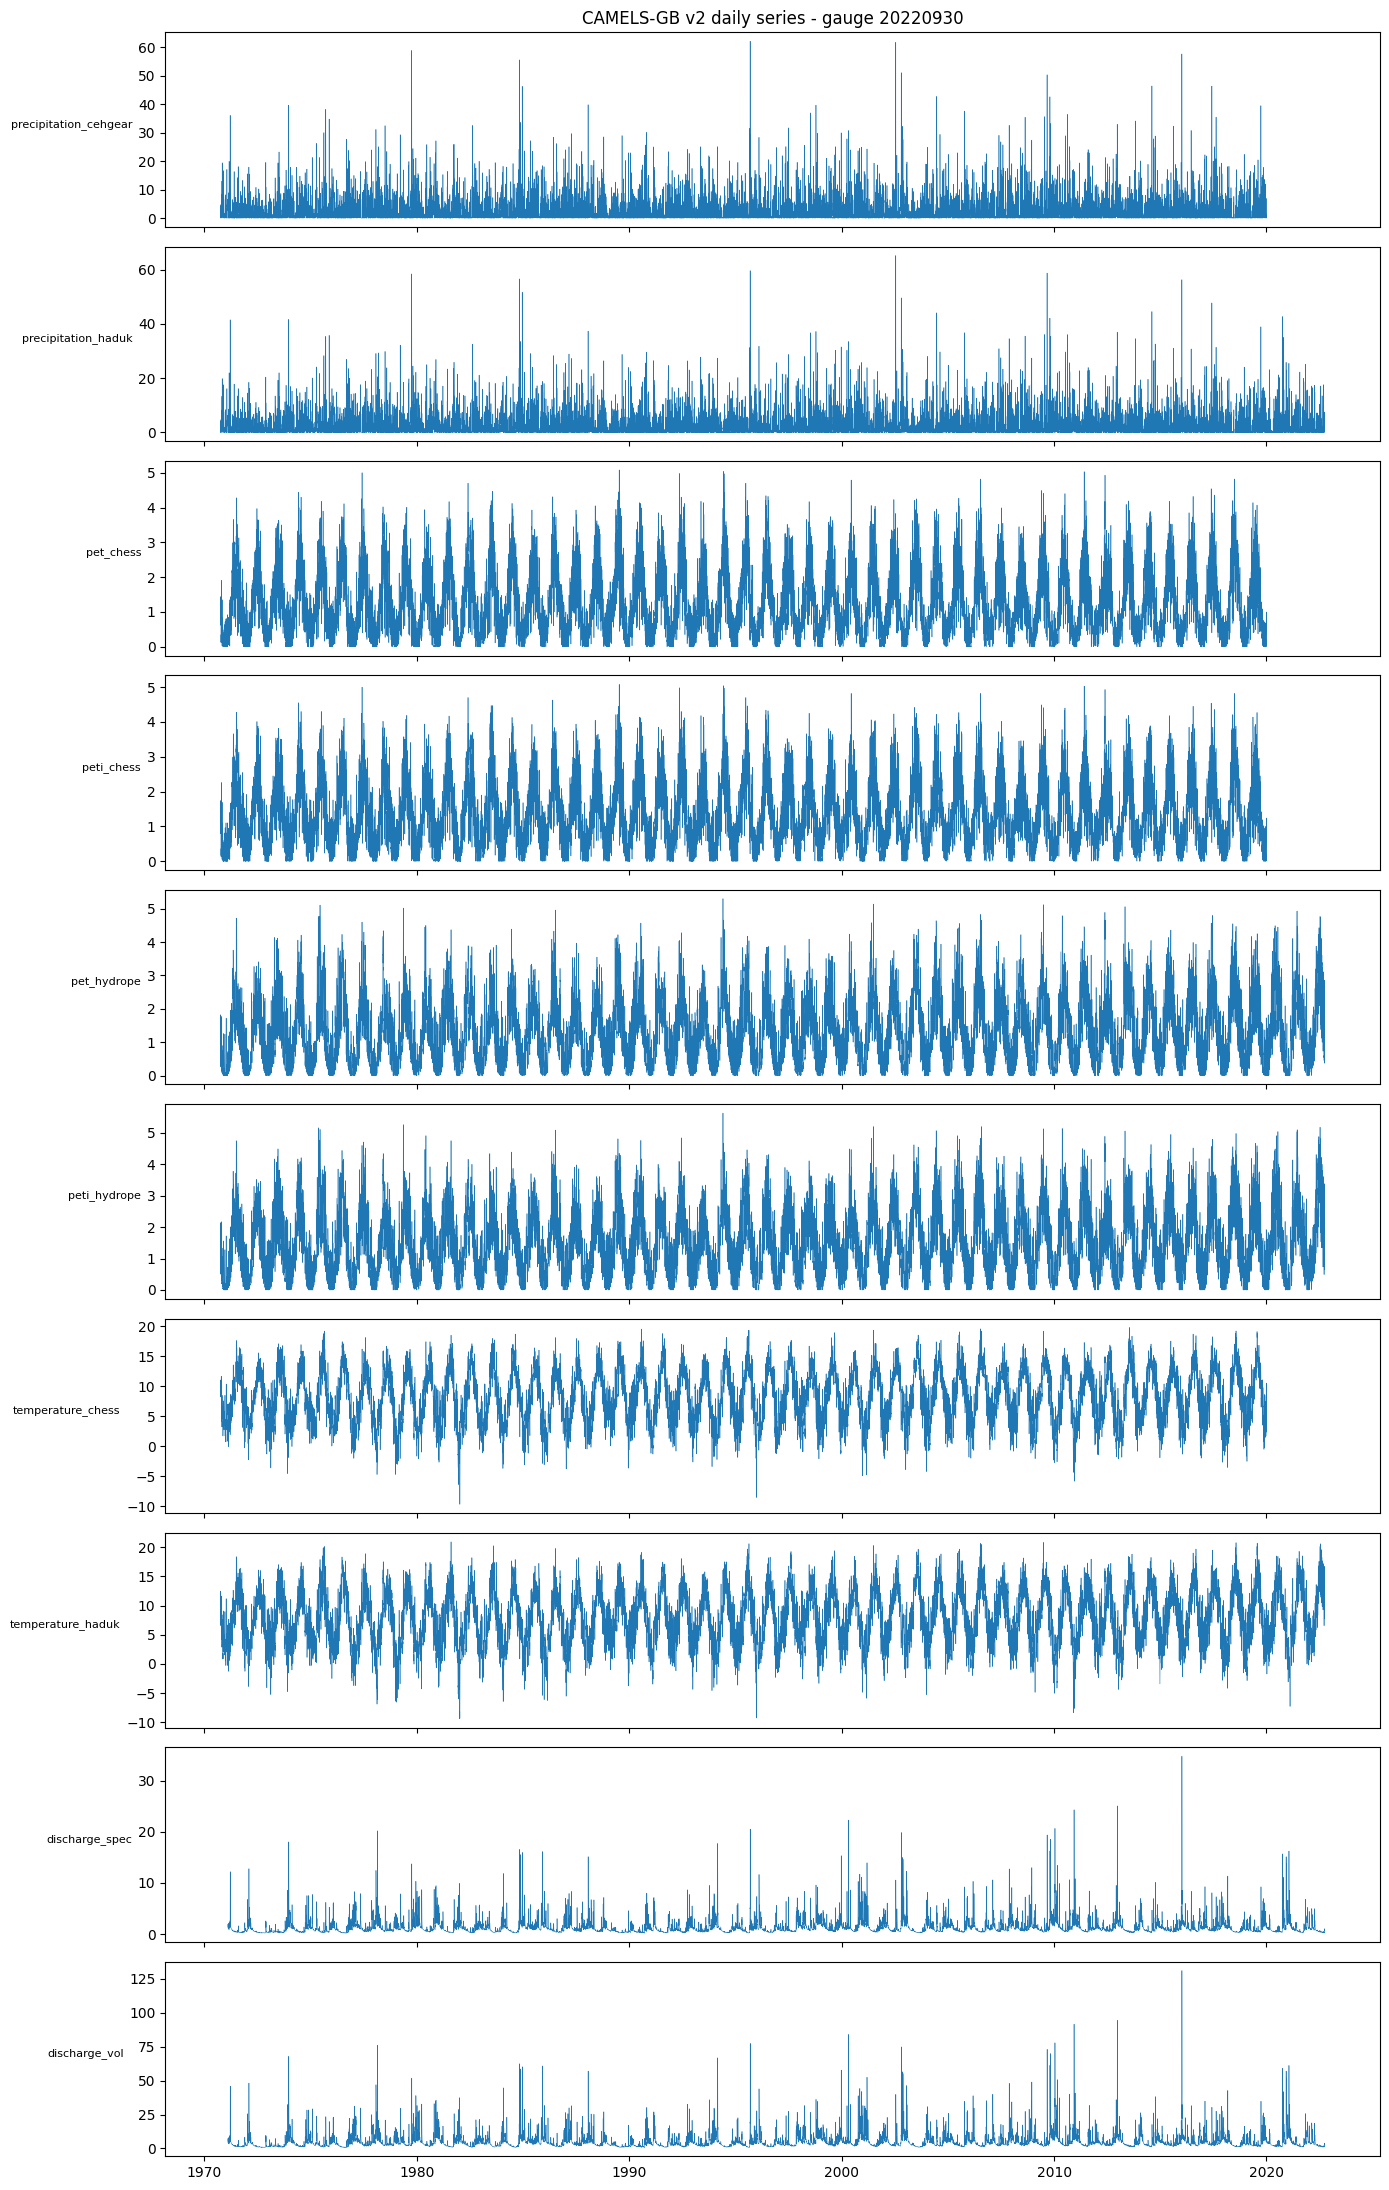

In [ ]:
# =============================================================================
# CELL 3 - Daily hydro-meteorological series for one example catchment
# =============================================================================
DAILY_DIR = DATA_DIR / "Catchment_Timeseries/hydro-meteorological/daily"
daily_files = sorted(DAILY_DIR.glob("*.csv"))

f = daily_files[0]                                     # change the index to look at another
gauge_id = re.findall(r"\d+", f.stem)[-1]              # gauge ID taken from the file name
print("File:", f.name, "| gauge ID:", gauge_id)

daily = read_csv_safe(f)
print("\nColumns:", list(daily.columns))

# --- Find the date column and use it as the index ---------------------------
date_col = next(c for c in daily.columns if "date" in c.lower() or "time" in c.lower())
daily[date_col] = pd.to_datetime(daily[date_col])
daily = daily.set_index(date_col)

print(f"\nPeriod: {daily.index.min().date()} to {daily.index.max().date()} "
      f"({len(daily):,} days)")

# --- Missing data per variable -----------------------------------------------
missing = pd.DataFrame({
    "missing_days": daily.isna().sum(),
    "missing_%": (100 * daily.isna().mean()).round(2),
})
display(missing)
display(daily.describe().T.round(3))

# --- Plot every numeric variable on its own panel ----------------------------
num_cols = daily.select_dtypes("number").columns
fig, axes = plt.subplots(len(num_cols), 1, figsize=(14, 2.2 * len(num_cols)), sharex=True)
for ax, col in zip(axes, num_cols):
    ax.plot(daily.index, daily[col], lw=0.4)
    ax.set_ylabel(col, rotation=0, ha="right", fontsize=8)
axes[0].set_title(f"CAMELS-GB v2 daily series - gauge {gauge_id}")
plt.tight_layout()
plt.show()

671 daily files, 671 hourly files
Gauge 10002: Ugie at Inverugie
Columns: ['precipitation_cehgear', 'precipitation_haduk', 'pet_chess', 'peti_chess', 'pet_hydrope', 'peti_hydrope', 'temperature_chess', 'temperature_haduk', 'discharge_spec', 'discharge_vol']

Data coverage per variable:
                      first_value last_value  missing_%
precipitation_cehgear  1970-10-01 2019-12-31       5.29
precipitation_haduk    1970-10-01 2022-09-30       0.00
pet_chess              1970-10-01 2019-12-31       5.29
peti_chess             1970-10-01 2019-12-31       5.29
pet_hydrope            1970-10-01 2022-09-30       0.00
peti_hydrope           1970-10-01 2022-09-30       0.00
temperature_chess      1970-10-01 2019-12-31       5.29
temperature_haduk      1970-10-01 2022-09-30       0.00
discharge_spec         1971-02-01 2022-09-30       0.65
discharge_vol          1971-02-01 2022-09-30       0.65


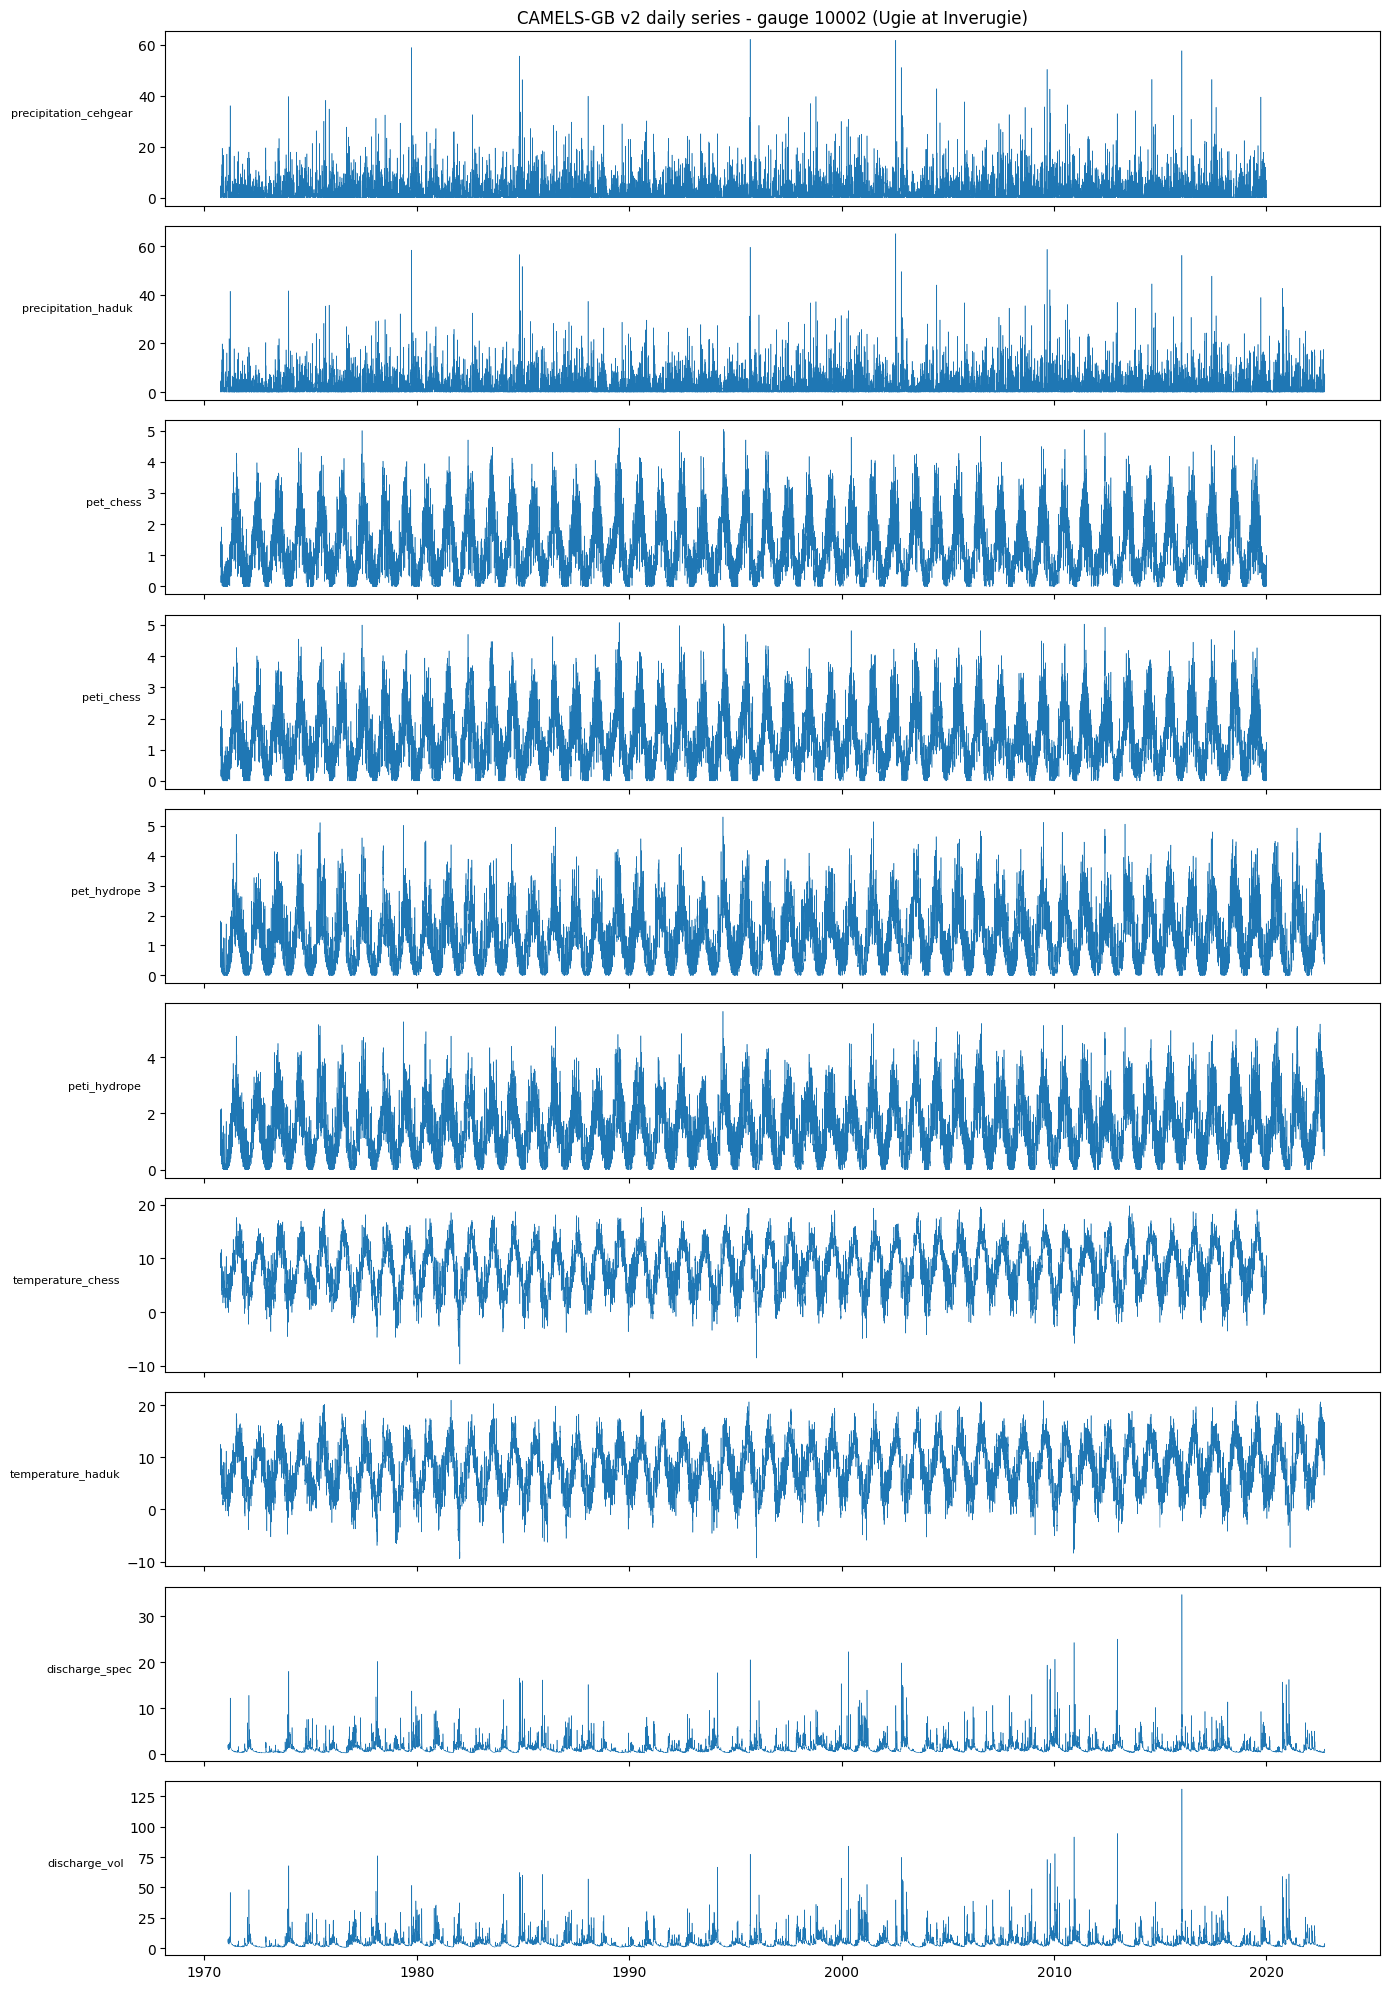

In [ ]:
# =============================================================================
# CELL 3b - Daily hydro-meteorological series for one example catchment
# =============================================================================
DAILY_DIR = DATA_DIR / "Catchment_Timeseries/hydro-meteorological/daily"
HOURLY_DIR = DATA_DIR / "Catchment_Timeseries/hydro-meteorological/hourly"

def gauge_from_name(path):
    """Gauge ID sits between 'timeseries_' and the next '_' in the file name."""
    return re.search(r"timeseries_(\d+)_", path.name).group(1)

daily_files = {gauge_from_name(p): p for p in DAILY_DIR.glob("*.csv")}
hourly_files = {gauge_from_name(p): p for p in HOURLY_DIR.glob("*.csv")}
print(f"{len(daily_files)} daily files, {len(hourly_files)} hourly files")

gauge_id = "10002"                                     # change to look at another gauge
names = attrs["topographic"].set_index("gauge_id")["gauge_name"]
print(f"Gauge {gauge_id}: {names.get(int(gauge_id), '?')}")

daily = pd.read_csv(daily_files[gauge_id])
date_col = next(c for c in daily.columns if "date" in c.lower() or "time" in c.lower())
daily[date_col] = pd.to_datetime(daily[date_col])
daily = daily.set_index(date_col)
print("Columns:", list(daily.columns))

# --- Period each variable actually has data for -----------------------------
coverage = pd.DataFrame({
    "first_value": daily.apply(lambda s: s.first_valid_index()),
    "last_value": daily.apply(lambda s: s.last_valid_index()),
    "missing_%": (100 * daily.isna().mean()).round(2),
})
print("\nData coverage per variable:")
print(coverage.to_string())

# --- Plot every numeric variable ---------------------------------------------
num_cols = daily.select_dtypes("number").columns
fig, axes = plt.subplots(len(num_cols), 1, figsize=(14, 2.0 * len(num_cols)), sharex=True)
for ax, col in zip(axes, num_cols):
    ax.plot(daily.index, daily[col], lw=0.4)
    ax.set_ylabel(col, rotation=0, ha="right", fontsize=8)
axes[0].set_title(f"CAMELS-GB v2 daily series - gauge {gauge_id} ({names.get(int(gauge_id), '')})")
plt.tight_layout()
plt.show()

File: camels_gb_v2_hydromet_hourly_timeseries_10002_19901001-20221001.csv
Columns: ['precipitation_cehgear', 'precipitation_gradgb', 'discharge_spec', 'discharge_vol', 'discharge_flag', 'level', 'level_flag']

Data coverage per variable:
                              first_value          last_value  missing_%
precipitation_cehgear 1990-10-01 09:00:00 2016-12-31 23:00:00      17.96
precipitation_gradgb  2006-01-01 01:00:00 2022-10-01 08:00:00      49.49
discharge_spec        1990-10-01 09:00:00 2022-10-01 08:00:00       0.00
discharge_vol         1990-10-01 09:00:00 2022-10-01 08:00:00       0.00
discharge_flag        1990-10-01 09:00:00 2022-10-01 08:00:00       0.00
level                 1990-10-01 09:00:00 2022-10-01 08:00:00       0.00
level_flag            1990-10-01 09:00:00 2022-10-01 08:00:00       0.00


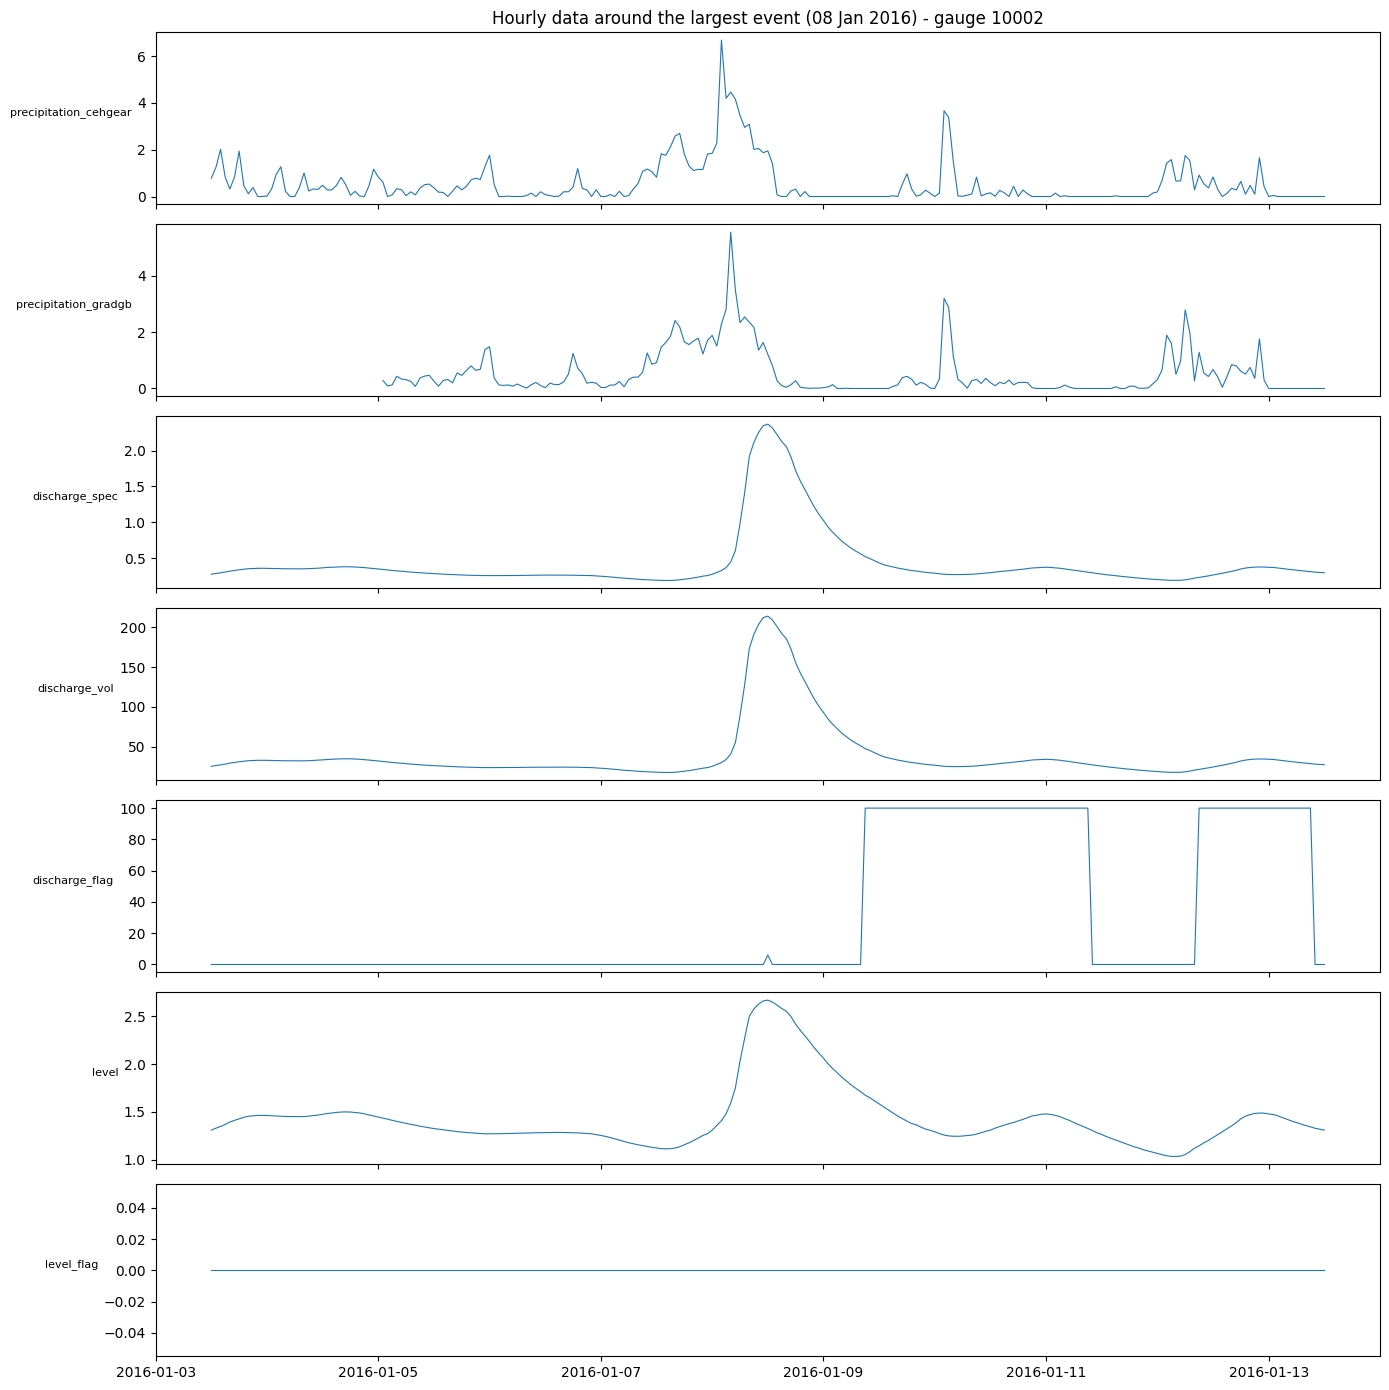

In [ ]:
# =============================================================================
# CELL 4 - Hourly series for the same catchment, zoomed on the largest event
# =============================================================================
hourly = pd.read_csv(hourly_files[gauge_id])
h_date_col = next(c for c in hourly.columns if "date" in c.lower() or "time" in c.lower())
hourly[h_date_col] = pd.to_datetime(hourly[h_date_col])
hourly = hourly.set_index(h_date_col)
print("File:", hourly_files[gauge_id].name)
print("Columns:", list(hourly.columns))

coverage_h = pd.DataFrame({
    "first_value": hourly.apply(lambda s: s.first_valid_index()),
    "last_value": hourly.apply(lambda s: s.last_valid_index()),
    "missing_%": (100 * hourly.isna().mean()).round(2),
})
print("\nData coverage per variable:")
print(coverage_h.to_string())

# --- Zoom in on the largest hourly flow event --------------------------------
h_num = hourly.select_dtypes("number").columns
flow_col = next((c for c in h_num if "discharge" in c.lower() or "flow" in c.lower()), h_num[0])
peak = hourly[flow_col].idxmax()
window = hourly.loc[peak - pd.Timedelta(days=5): peak + pd.Timedelta(days=5)]

fig, axes = plt.subplots(len(h_num), 1, figsize=(14, 2.0 * len(h_num)), sharex=True)
axes = [axes] if len(h_num) == 1 else axes
for ax, col in zip(axes, h_num):
    ax.plot(window.index, window[col], lw=0.8)
    ax.set_ylabel(col, rotation=0, ha="right", fontsize=8)
axes[0].set_title(f"Hourly data around the largest event ({peak:%d %b %Y}) - gauge {gauge_id}")
plt.tight_layout()
plt.show()

Shapefiles found: ['camels_gb_v2_catchment_boundaries.shp']

CRS: EPSG:27700
Columns: ['ID', 'ID_STRING', 'ceast', 'cnorth', 'area', 'geometry']
Number of catchments: 671


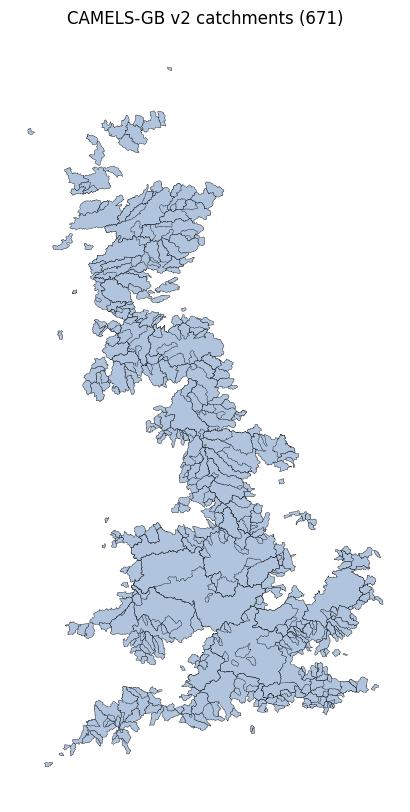

In [ ]:
# =============================================================================
# CELL 5 - Map of the catchment boundaries
# =============================================================================
import geopandas as gpd

BOUND_DIR = DATA_DIR / "Catchment_Boundaries"
shp = sorted(BOUND_DIR.glob("*.shp"))
print("Shapefiles found:", [s.name for s in shp])

gdf = gpd.read_file(shp[0])
print("\nCRS:", gdf.crs)
print("Columns:", list(gdf.columns))
print("Number of catchments:", len(gdf))

ax = gdf.plot(figsize=(7, 10), edgecolor="black", linewidth=0.2, facecolor="lightsteelblue")
ax.set_title("CAMELS-GB v2 catchments (671)")
ax.set_axis_off()
plt.show()

Benchmark catchments: 137 of 671

Benchmark vs all catchments:
                           all_671_median  bench_median  bench_min  bench_max
area                               151.64        101.07       4.38    1505.54
elev_mean                          163.00        207.00      25.00     657.00
p_mean                               2.63          3.09       1.61       8.38
aridity                              0.56          0.46       0.12       1.06
baseflow_index                       0.56          0.52       0.23       0.92
runoff_ratio                         0.53          0.61       0.16       1.39
daily_flow_perc_complete            98.24         99.04      55.55     100.00
hourly_flow_perc_complete           99.62         99.78       0.00     100.00
extrap_ratio                         1.67          1.86       0.93      49.09

Quality checks (benchmark catchments):
  runoff ratio > 1 (water-balance problem): 2
  daily flow < 90% complete:               32
  hourly flow < 90% compl

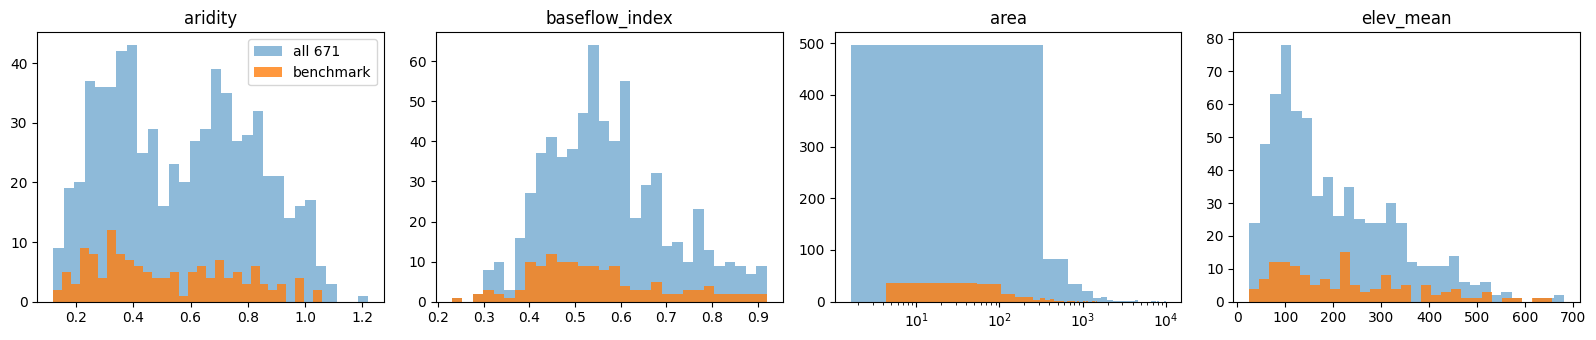

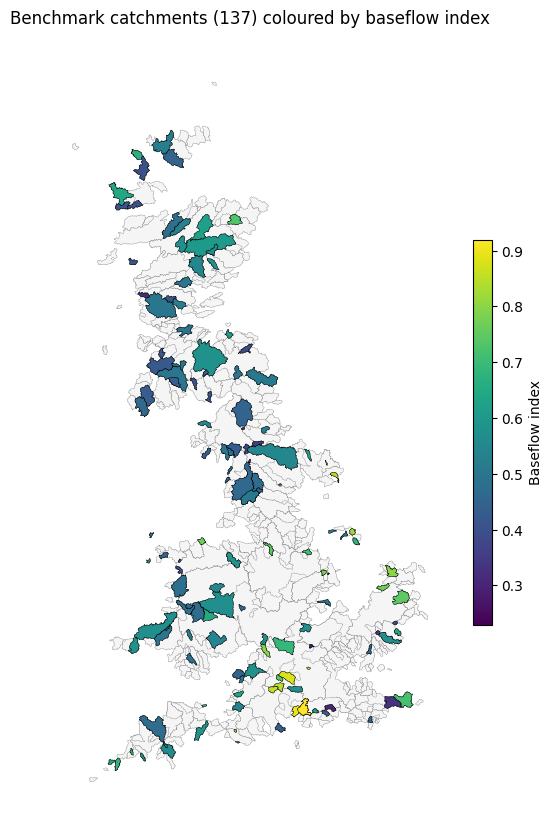

In [ ]:
# =============================================================================
# CELL 6 - The 137 benchmark (near-natural) catchments vs all 671
# =============================================================================
import geopandas as gpd

# --- Join the attribute tables into one table, one row per catchment ---------
keep = {
    "topographic":    ["gauge_id", "gauge_name", "area", "elev_mean", "dpsbar"],
    "climatic":       ["gauge_id", "p_mean", "pet_mean", "aridity", "frac_snow"],
    "hydrologic":     ["gauge_id", "q_mean", "runoff_ratio", "baseflow_index", "Q95", "Q5"],
    "humaninfluence": ["gauge_id", "benchmark_catch", "surfacewater_abs",
                       "groundwater_abs", "num_reservoir"],
    "hydrometry":     ["gauge_id", "station_type", "daily_flow_perc_complete",
                       "hourly_flow_perc_complete", "max_gauging_flow", "max_hourly_flow",
                       "quncert_meta", "station_quality_hourlyflow_issues"],
}
cat = None
for table, cols in keep.items():
    part = attrs[table][cols]
    cat = part if cat is None else cat.merge(part, on="gauge_id", how="left")

cat["benchmark"] = cat["benchmark_catch"].eq("Y")
# how far the highest hourly flow goes beyond the highest manual gauging
cat["extrap_ratio"] = cat["max_hourly_flow"] / cat["max_gauging_flow"]
bench = cat[cat["benchmark"]]
print(f"Benchmark catchments: {len(bench)} of {len(cat)}")

# --- Compare benchmark catchments with all catchments ------------------------
cols = ["area", "elev_mean", "p_mean", "aridity", "baseflow_index",
        "runoff_ratio", "daily_flow_perc_complete", "hourly_flow_perc_complete", "extrap_ratio"]
summary = pd.concat({
    "all_671_median": cat[cols].median(),
    "bench_median": bench[cols].median(),
    "bench_min": bench[cols].min(),
    "bench_max": bench[cols].max(),
}, axis=1).round(2)
print("\nBenchmark vs all catchments:")
print(summary.to_string())

# --- Data-quality issues within the benchmark set ----------------------------
print("\nQuality checks (benchmark catchments):")
print("  runoff ratio > 1 (water-balance problem):", (bench["runoff_ratio"] > 1).sum())
print("  daily flow < 90% complete:              ", (bench["daily_flow_perc_complete"] < 90).sum())
print("  hourly flow < 90% complete:             ", (bench["hourly_flow_perc_complete"] < 90).sum())
print("  hourly flow issue flagged:              ", bench["station_quality_hourlyflow_issues"].notna().sum())
print("  peak flow > 2x highest gauging:         ", (bench["extrap_ratio"] > 2).sum())
print("\nDischarge uncertainty information (benchmark):")
print(bench["quncert_meta"].value_counts().to_string())
print("\nStation types (benchmark):")
print(bench["station_type"].value_counts().head(10).to_string())

# --- Distributions: is the benchmark set varied enough? ----------------------
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["aridity", "baseflow_index", "area", "elev_mean"]):
    ax.hist(cat[col].dropna(), bins=30, alpha=0.5, label="all 671")
    ax.hist(bench[col].dropna(), bins=30, alpha=0.8, label="benchmark")
    ax.set_title(col)
    if col == "area":
        ax.set_xscale("log")
axes[0].legend()
plt.tight_layout()
plt.show()

# --- Map: benchmark catchments coloured by baseflow index --------------------
gdf = gpd.read_file(DATA_DIR / "Catchment_Boundaries/camels_gb_v2_catchment_boundaries.shp")
gdf = gdf.merge(cat, left_on="ID", right_on="gauge_id", how="left")

fig, ax = plt.subplots(figsize=(7, 10))
gdf.plot(ax=ax, facecolor="whitesmoke", edgecolor="grey", linewidth=0.2)
gdf[gdf["benchmark"]].plot(ax=ax, column="baseflow_index", cmap="viridis",
                           edgecolor="black", linewidth=0.3, legend=True,
                           legend_kwds={"label": "Baseflow index", "shrink": 0.5})
ax.set_title(f"Benchmark catchments ({len(bench)}) coloured by baseflow index")
ax.set_axis_off()
plt.show()

In [ ]:
# =============================================================================
# Decode the 3-digit hourly discharge flags (XYZ) - Coxon et al. (2026), Supplement S1
# =============================================================================
NRFA_X = {0: "agrees with NRFA", 1: ">5% off NRFA daily", 2: ">20% off POT peaks",
          3: ">20% off annual maxima", 4: "off daily + POT", 5: "off daily + AMAX"}
BASIC_Y = {0: "OK", 1: "negative", 2: "relative spike", 3: "absolute spike", 4: "drop",
           5: "fluctuation", 6: "truncated low", 7: "truncated high",
           8: "relative + absolute spike", 9: "drop + negative/truncated low"}
HIGH_Z = {0: "not a high flow", 1: "unrealistically high", 2: "exceptionally high",
          3: "big event, no antecedent rain", 4: "big event, no regional high flow",
          5: "no rain and no regional high flow", 6: "validated event",
          7: "exceptional + unsupported", 8: "exceptional + no rain/regional", 9: "exceptional, validated"}

# Turn e.g. 6 -> "006" and split into the three digits
codes = hourly["discharge_flag"].dropna().astype(int).astype(str).str.zfill(3)
decoded = pd.DataFrame({
    "nrfa_check":  codes.str[0].astype(int).map(NRFA_X),
    "basic_qc":    codes.str[1].astype(int).map(BASIC_Y),
    "high_flow_qc": codes.str[2].astype(int).map(HIGH_Z),
})

# Percentage of hours in each category, for each check
for col in decoded.columns:
    print(f"\n{col} (% of hours):")
    print((100 * decoded[col].value_counts(normalize=True)).round(3).to_string())


nrfa_check (% of hours):
nrfa_check
agrees with NRFA      90.172
>5% off NRFA daily     9.827
off daily + POT        0.001
off daily + AMAX       0.000

basic_qc (% of hours):
basic_qc
OK             99.998
fluctuation     0.002

high_flow_qc (% of hours):
high_flow_qc
not a high flow    99.998
validated event     0.002


Benchmark catchments:                         137
After removing runoff ratio > 1:              135  (removed ['27073', '44009'])
With >= 90.0% flow in train AND test:    128  (removed 7)
Forcing complete in train and test for all: True

Selected 50 catchments. Per regime (aridity/BFI):
              available  selected
regime                           
dry/baseflow         20         7
dry/flashy           10         4
dry/mid              12         5
mid/baseflow         18         7
mid/flashy           12         5
mid/mid              13         5
wet/baseflow          4         2
wet/flashy           21         8
wet/mid              18         7

Selected vs eligible (median):
                eligible  selected
area              105.30    101.82
elev_mean         206.50    182.50
p_mean              3.06      3.18
aridity             0.47      0.44
baseflow_index      0.52      0.54
runoff_ratio        0.60      0.61
flow_train_%      100.00    100.00
flow_test_%       100.00  

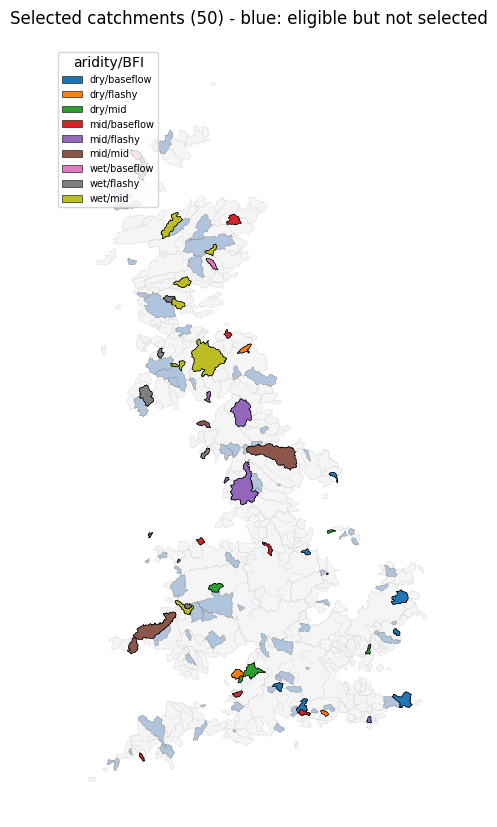

In [ ]:
# =============================================================================
# CELL 7 - Select ~50 catchments for the rainfall-runoff benchmark
# Protocol: periods follow Lees et al. (2021, HESS); forcing = Option A
# (CEH-GEAR precipitation, CHESS-PE PET, CHESS-met temperature)
# =============================================================================
import numpy as np
import geopandas as gpd

# --- Settings ----------------------------------------------------------------
PERIODS = {                                  # Lees et al. (2021)
    "validation": ("1975-01-01", "1980-12-31"),
    "train":      ("1988-01-01", "1997-12-31"),
    "test":       ("1998-01-01", "2008-12-31"),
}
FORCING_A = ["precipitation_cehgear", "pet_chess", "temperature_chess"]
MIN_FLOW_COMPLETE = 90.0                     # % of days with flow, train and test (our choice)
N_TARGET = 50                                # catchments to select
MIN_PER_CLASS = 2                            # keep every aridity/BFI regime represented
SEED = 42                                    # reproducible selection
OUT_DIR = DATA_DIR.parent.parent / "outputs" / "catchment_selection"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Step 1: one attribute table, one row per catchment ----------------------
keep = {
    "topographic":    ["gauge_id", "gauge_name", "gauge_lat", "gauge_lon", "area", "elev_mean"],
    "climatic":       ["gauge_id", "p_mean", "aridity", "frac_snow"],
    "hydrologic":     ["gauge_id", "q_mean", "runoff_ratio", "baseflow_index"],
    "humaninfluence": ["gauge_id", "benchmark_catch"],
    "hydrometry":     ["gauge_id", "station_type", "max_gauging_flow", "max_hourly_flow",
                       "quncert_meta"],
}
cat = None
for table, cols in keep.items():
    part = attrs[table][cols]
    cat = part if cat is None else cat.merge(part, on="gauge_id", how="left")
cat["gauge_id"] = cat["gauge_id"].astype(str)
cat["extrap_ratio"] = cat["max_hourly_flow"] / cat["max_gauging_flow"]

# --- Step 2: benchmark catchments with a plausible water balance -------------
pool = cat[cat["benchmark_catch"].eq("Y")].copy()
print(f"Benchmark catchments:                         {len(pool)}")
dropped_rr = pool[pool["runoff_ratio"] > 1]
pool = pool[pool["runoff_ratio"] <= 1]
print(f"After removing runoff ratio > 1:              {len(pool)}  "
      f"(removed {list(dropped_rr['gauge_id'])})")

# --- Step 3: flow completeness in each period, from the daily files ----------
def period_completeness(gid):
    """% of days with flow (and with all Option-A forcings) in each period."""
    df = pd.read_csv(daily_files[gid], parse_dates=["date"]).set_index("date")
    out = {"gauge_id": gid}
    for name, (start, end) in PERIODS.items():
        sub = df.loc[start:end]
        out[f"flow_{name}_%"] = 100 * sub["discharge_spec"].notna().mean() if len(sub) else 0.0
        out[f"forcing_{name}_%"] = 100 * sub[FORCING_A].notna().all(axis=1).mean() if len(sub) else 0.0
    return out

comp = pd.DataFrame([period_completeness(g) for g in pool["gauge_id"]]).round(1)
pool = pool.merge(comp, on="gauge_id")

ok = (pool["flow_train_%"] >= MIN_FLOW_COMPLETE) & (pool["flow_test_%"] >= MIN_FLOW_COMPLETE)
print(f"With >= {MIN_FLOW_COMPLETE}% flow in train AND test:    {ok.sum()}  "
      f"(removed {(~ok).sum()})")
print("Forcing complete in train and test for all:",
      bool((pool.loc[ok, ['forcing_train_%', 'forcing_test_%']] == 100).all().all()))
eligible = pool[ok].copy()

# --- Step 4: aridity x BFI classes (terciles of the eligible pool) -----------
eligible["aridity_class"] = pd.qcut(eligible["aridity"], 3, labels=["wet", "mid", "dry"])
eligible["bfi_class"] = pd.qcut(eligible["baseflow_index"], 3, labels=["flashy", "mid", "baseflow"])
eligible["regime"] = eligible["aridity_class"].astype(str) + "/" + eligible["bfi_class"].astype(str)

sizes = eligible["regime"].value_counts().sort_index()
quota = np.maximum(np.round(N_TARGET * sizes / sizes.sum()), MIN_PER_CLASS)
quota = np.minimum(quota, sizes).astype(int)
# adjust so quotas add up to N_TARGET (change the largest classes first)
while quota.sum() != min(N_TARGET, sizes.sum()):
    step = 1 if quota.sum() < N_TARGET else -1
    room = (sizes - quota) if step == 1 else (quota - MIN_PER_CLASS)
    quota[room[room > 0].idxmax()] += step

# --- Step 5: random but reproducible pick within each class ------------------
selected = pd.concat([
    eligible[eligible["regime"] == r].sample(n=int(q), random_state=SEED)
    for r, q in quota.items()
]).sort_values("gauge_id", key=lambda s: s.astype(int))

print(f"\nSelected {len(selected)} catchments. Per regime (aridity/BFI):")
print(pd.DataFrame({"available": sizes, "selected": quota}).to_string())

# --- Step 6: summary of the selection ----------------------------------------
cols = ["area", "elev_mean", "p_mean", "aridity", "baseflow_index", "runoff_ratio",
        "flow_train_%", "flow_test_%"]
print("\nSelected vs eligible (median):")
print(pd.concat({"eligible": eligible[cols].median(), "selected": selected[cols].median()},
                axis=1).round(2).to_string())
print(f"\nPeak > 2x highest gauging (matters for high flows, not daily NSE): "
      f"{(selected['extrap_ratio'] > 2).sum()} of {len(selected)}")

print("\nSelected catchments:")
print(selected[["gauge_id", "gauge_name", "regime", "area", "aridity", "baseflow_index",
                "flow_train_%", "flow_test_%"]].to_string(index=False))

# --- Step 7: save (full table + basin list for neuralhydrology) --------------
selected.to_csv(OUT_DIR / "selected_catchments.csv", index=False)
eligible.to_csv(OUT_DIR / "eligible_catchments.csv", index=False)
(OUT_DIR / "basins_50.txt").write_text("\n".join(selected["gauge_id"]) + "\n")
print(f"\nSaved to {OUT_DIR}")

# --- Step 8: map --------------------------------------------------------------
gdf = gpd.read_file(DATA_DIR / "Catchment_Boundaries/camels_gb_v2_catchment_boundaries.shp")
gdf["gauge_id"] = gdf["ID"].astype(int).astype(str)
fig, ax = plt.subplots(figsize=(7, 10))
gdf.plot(ax=ax, facecolor="whitesmoke", edgecolor="lightgrey", linewidth=0.2)
gdf[gdf["gauge_id"].isin(eligible["gauge_id"])].plot(ax=ax, facecolor="lightsteelblue",
                                                    edgecolor="grey", linewidth=0.2)
gdf.merge(selected[["gauge_id", "regime"]], on="gauge_id").plot(
    ax=ax, column="regime", cmap="tab10", edgecolor="black", linewidth=0.4,
    legend=True, legend_kwds={"loc": "upper left", "fontsize": 7, "title": "aridity/BFI"})
ax.set_title(f"Selected catchments ({len(selected)}) - blue: eligible but not selected")
ax.set_axis_off()
plt.show()

**Model Setup**

In [ ]:
# =============================================================================
# CELL 8 - Enable R inside this Python notebook (lets us run airGR with %%R)
# =============================================================================
# If this line fails, first run:  !pip install rpy2
%load_ext rpy2.ipython

In [ ]:
%%R
# =============================================================================
# CELL 9 - Install and load airGR (GR4J, GR6J) - INRAE
# =============================================================================
if (!requireNamespace("airGR", quietly = TRUE)) install.packages("airGR", quiet = TRUE)
suppressPackageStartupMessages(library(airGR))
cat("airGR version:", as.character(packageVersion("airGR")), "\n")
cat("CPU cores available:", parallel::detectCores(), "\n")

airGR version: 1.7.9 
CPU cores available: 2 


In [ ]:
%%R
# =============================================================================
# CELL 10 - Calibrate GR4J and GR6J on 128 catchments (Option A forcing)
# Warm-up 1985-87 | calibration 1988-97 (NSE) | test 1998-2008 (NSE, KGE)
# Periods follow Lees et al. (2021); calibration uses airGR Calibration_Michel
# =============================================================================
suppressPackageStartupMessages({library(airGR); library(parallel)})

# --- Paths -------------------------------------------------------------------
root      <- "/content/drive/MyDrive/rainfall_runoff_benchmark"
daily_dir <- file.path(root, "data/camels_gb_v2/Catchment_Timeseries/hydro-meteorological/daily")
out_dir   <- file.path(root, "outputs/gr_models")
dir.create(file.path(out_dir, "sim"),    recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(out_dir, "params"), recursive = TRUE, showWarnings = FALSE)

# --- Catchments and their daily files ----------------------------------------
gauges <- as.character(read.csv(file.path(root, "outputs/catchment_selection/eligible_catchments.csv"))$gauge_id)
files  <- list.files(daily_dir, pattern = "\\.csv$", full.names = TRUE)
names(files) <- sub(".*timeseries_([0-9]+)_.*", "\\1", basename(files))
cat("Catchments to run:", length(gauges), "\n")

# --- Periods -------------------------------------------------------------------
P_WARM  <- c("1985-01-01", "1987-12-31")
P_TRAIN <- c("1988-01-01", "1997-12-31")
P_TEST  <- c("1998-01-01", "2008-12-31")

# --- Performance metrics (missing observed days are ignored) -----------------
nse <- function(s, o) { k <- !is.na(s) & !is.na(o)
  1 - sum((s[k] - o[k])^2) / sum((o[k] - mean(o[k]))^2) }
kge <- function(s, o) { k <- !is.na(s) & !is.na(o)            # Gupta et al. (2009)
  r <- cor(s[k], o[k]); a <- sd(s[k]) / sd(o[k]); b <- mean(s[k]) / mean(o[k])
  1 - sqrt((r - 1)^2 + (a - 1)^2 + (b - 1)^2) }

# --- Calibrate one model on one catchment ------------------------------------
run_one <- function(gid, model) {
  par_file <- file.path(out_dir, "params", paste0(model, "_", gid, ".csv"))
  if (file.exists(par_file)) return(read.csv(par_file))      # already done -> skip

  out <- tryCatch({
    FUN <- if (model == "GR4J") RunModel_GR4J else RunModel_GR6J

    # read daily data and keep warm-up start to end of test period
    d <- read.csv(files[[gid]])
    d$date <- as.POSIXct(substr(d$date, 1, 10), tz = "UTC")
    d <- d[d$date >= as.POSIXct(P_WARM[1], tz = "UTC") &
           d$date <= as.POSIXct(P_TEST[2], tz = "UTC"), ]
    idx <- function(p) which(d$date >= as.POSIXct(p[1], tz = "UTC") &
                             d$date <= as.POSIXct(p[2], tz = "UTC"))
    i_warm <- idx(P_WARM); i_train <- idx(P_TRAIN); i_test <- idx(P_TEST)
    i_all  <- c(i_train, i_test)

    # model inputs: rainfall (CEH-GEAR) and PET (CHESS-PE), mm/day
    inputs <- CreateInputsModel(FUN_MOD = FUN, DatesR = d$date,
                                Precip = d$precipitation_cehgear, PotEvap = d$pet_chess)

    # calibration on 1988-97, maximising NSE
    run_cal  <- CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                 IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_train,
                                 verbose = FALSE)
    crit_cal <- CreateInputsCrit(FUN_CRIT = ErrorCrit_NSE, InputsModel = inputs,
                                 RunOptions = run_cal, Obs = d$discharge_spec[i_train])
    cal <- Calibration_Michel(InputsModel = inputs, RunOptions = run_cal,
                              InputsCrit = crit_cal,
                              CalibOptions = CreateCalibOptions(FUN_MOD = FUN),
                              FUN_MOD = FUN, verbose = FALSE)
    par <- cal$ParamFinalR

    # one continuous run 1988-2008 with the calibrated parameters
    run_all <- CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_all,
                                verbose = FALSE)
    sim  <- FUN(InputsModel = inputs, RunOptions = run_all, Param = par)$Qsim
    obs  <- d$discharge_spec[i_all]
    n_tr <- length(i_train)
    tr <- 1:n_tr; te <- (n_tr + 1):length(i_all)

    # save simulated vs observed series (used later for maps and plots)
    write.csv(data.frame(date = format(d$date[i_all], "%Y-%m-%d"), q_obs = obs, q_sim = sim),
              file.path(out_dir, "sim", paste0(model, "_", gid, ".csv")), row.names = FALSE)

    res <- data.frame(gauge_id = gid, model = model,
                      nse_train = nse(sim[tr], obs[tr]), kge_train = kge(sim[tr], obs[tr]),
                      nse_test  = nse(sim[te], obs[te]), kge_test  = kge(sim[te], obs[te]),
                      error = NA)
    res[paste0("X", seq_along(par))] <- as.list(par)
    res
  }, error = function(e) data.frame(gauge_id = gid, model = model, error = conditionMessage(e)))

  if (is.na(out$error[1])) write.csv(out, par_file, row.names = FALSE)   # save successes only
  out
}

# --- Run all catchments, both models, in parallel ----------------------------
n_cores <- max(1, detectCores())
for (model in c("GR4J", "GR6J")) {
  t0 <- Sys.time()
  res <- mclapply(gauges, run_one, model = model, mc.cores = n_cores)
  res <- do.call(rbind, lapply(res, function(x) { x[setdiff(c("gauge_id","model","nse_train",
           "kge_train","nse_test","kge_test","error"), names(x))] <- NA; x }))
  n_err <- sum(!is.na(res$error))
  cat(sprintf("%s: %d catchments in %.1f min | errors: %d | median test NSE = %.3f, KGE = %.3f\n",
              model, nrow(res), as.numeric(difftime(Sys.time(), t0, units = "mins")), n_err,
              median(res$nse_test, na.rm = TRUE), median(res$kge_test, na.rm = TRUE)))
  if (n_err > 0) print(head(res[!is.na(res$error), c("gauge_id", "error")]))
}

# --- Combine all saved results into one table --------------------------------
all_res <- do.call(rbind, lapply(list.files(file.path(out_dir, "params"), full.names = TRUE),
                                 function(f) { x <- read.csv(f)
                                   x[setdiff(paste0("X", 1:6), names(x))] <- NA; x }))
write.csv(all_res, file.path(out_dir, "gr_results_optionA.csv"), row.names = FALSE)
cat("\nSaved:", file.path(out_dir, "gr_results_optionA.csv"), "\n")

Catchments to run: 128 
GR4J: 128 catchments in 2.0 min | errors: 0 | median test NSE = 0.863, KGE = 0.870


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%writefile /content/drive/MyDrive/rainfall_runoff_benchmark/gr_calibrate.R
# =============================================================================
# gr_calibrate.R - Calibrate GR4J or GR6J on the eligible catchments (Option A)
# Warm-up 1985-87 | calibration 1988-97 (NSE, Calibration_Michel) | test 1998-2008
# Periods follow Lees et al. (2021). Run with:  Rscript gr_calibrate.R GR6J
# =============================================================================
suppressPackageStartupMessages(library(airGR))

model <- commandArgs(trailingOnly = TRUE)[1]               # "GR4J" or "GR6J"
stopifnot(model %in% c("GR4J", "GR6J"))
FUN <- if (model == "GR4J") RunModel_GR4J else RunModel_GR6J

# --- Paths -------------------------------------------------------------------
root      <- "/content/drive/MyDrive/rainfall_runoff_benchmark"
daily_dir <- file.path(root, "data/camels_gb_v2/Catchment_Timeseries/hydro-meteorological/daily")
out_dir   <- file.path(root, "outputs/gr_models")
dir.create(file.path(out_dir, "sim"),    recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(out_dir, "params"), recursive = TRUE, showWarnings = FALSE)

gauges <- as.character(read.csv(file.path(root, "outputs/catchment_selection/eligible_catchments.csv"))$gauge_id)
files  <- list.files(daily_dir, pattern = "\\.csv$", full.names = TRUE)
names(files) <- sub(".*timeseries_([0-9]+)_.*", "\\1", basename(files))

# --- Periods -------------------------------------------------------------------
P_WARM  <- c("1985-01-01", "1987-12-31")
P_TRAIN <- c("1988-01-01", "1997-12-31")
P_TEST  <- c("1998-01-01", "2008-12-31")

# --- Metrics (missing observed days ignored) ---------------------------------
nse <- function(s, o) { k <- !is.na(s) & !is.na(o)
  1 - sum((s[k] - o[k])^2) / sum((o[k] - mean(o[k]))^2) }
kge <- function(s, o) { k <- !is.na(s) & !is.na(o)            # Gupta et al. (2009)
  r <- cor(s[k], o[k]); a <- sd(s[k]) / sd(o[k]); b <- mean(s[k]) / mean(o[k])
  1 - sqrt((r - 1)^2 + (a - 1)^2 + (b - 1)^2) }

# --- Loop over catchments, one at a time, printing progress ------------------
t_all <- Sys.time()
for (i in seq_along(gauges)) {
  gid <- gauges[i]
  par_file <- file.path(out_dir, "params", paste0(model, "_", gid, ".csv"))
  if (file.exists(par_file)) { cat(sprintf("[%3d/%d] %s %-7s already done - skipped\n",
                                           i, length(gauges), model, gid)); next }
  t0 <- Sys.time()
  res <- tryCatch({
    # read daily data from warm-up start to end of test period
    d <- read.csv(files[[gid]])
    d$date <- as.POSIXct(substr(d$date, 1, 10), tz = "UTC")
    d <- d[d$date >= as.POSIXct(P_WARM[1], tz = "UTC") &
           d$date <= as.POSIXct(P_TEST[2], tz = "UTC"), ]
    idx <- function(p) which(d$date >= as.POSIXct(p[1], tz = "UTC") &
                             d$date <= as.POSIXct(p[2], tz = "UTC"))
    i_warm <- idx(P_WARM); i_train <- idx(P_TRAIN); i_test <- idx(P_TEST)
    i_all  <- c(i_train, i_test)

    # inputs: CEH-GEAR rainfall and CHESS-PE PET (mm/day)
    inputs <- CreateInputsModel(FUN_MOD = FUN, DatesR = d$date,
                                Precip = d$precipitation_cehgear, PotEvap = d$pet_chess)

    # calibrate on 1988-97, maximising NSE
    run_cal  <- CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                 IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_train,
                                 verbose = FALSE)
    crit_cal <- CreateInputsCrit(FUN_CRIT = ErrorCrit_NSE, InputsModel = inputs,
                                 RunOptions = run_cal, Obs = d$discharge_spec[i_train])
    cal <- Calibration_Michel(InputsModel = inputs, RunOptions = run_cal,
                              InputsCrit = crit_cal,
                              CalibOptions = CreateCalibOptions(FUN_MOD = FUN),
                              FUN_MOD = FUN, verbose = FALSE)
    par <- cal$ParamFinalR

    # continuous run 1988-2008 with calibrated parameters
    run_all <- CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_all,
                                verbose = FALSE)
    sim <- FUN(InputsModel = inputs, RunOptions = run_all, Param = par)$Qsim
    obs <- d$discharge_spec[i_all]
    tr  <- seq_along(i_train); te <- (length(i_train) + 1):length(i_all)

    # save simulated vs observed series
    write.csv(data.frame(date = format(d$date[i_all], "%Y-%m-%d"), q_obs = obs, q_sim = sim),
              file.path(out_dir, "sim", paste0(model, "_", gid, ".csv")), row.names = FALSE)

    out <- data.frame(gauge_id = gid, model = model,
                      nse_train = nse(sim[tr], obs[tr]), kge_train = kge(sim[tr], obs[tr]),
                      nse_test  = nse(sim[te], obs[te]), kge_test  = kge(sim[te], obs[te]))
    out[paste0("X", seq_along(par))] <- as.list(par)
    write.csv(out, par_file, row.names = FALSE)
    sprintf("test NSE = %.3f, KGE = %.3f", out$nse_test, out$kge_test)
  }, error = function(e) paste("ERROR:", conditionMessage(e)))

  cat(sprintf("[%3d/%d] %s %-7s %5.1f s  %s\n", i, length(gauges), model, gid,
              as.numeric(difftime(Sys.time(), t0, units = "secs")), res))
  flush.console()
}

# --- Combine all saved results (both models) into one table ------------------
all_res <- do.call(rbind, lapply(list.files(file.path(out_dir, "params"), full.names = TRUE),
                                 function(f) { x <- read.csv(f)
                                   x[setdiff(paste0("X", 1:6), names(x))] <- NA; x }))
write.csv(all_res, file.path(out_dir, "gr_results_optionA.csv"), row.names = FALSE)
for (m in unique(all_res$model)) {
  s <- all_res[all_res$model == m, ]
  cat(sprintf("\n%s: %d catchments | median test NSE = %.3f, KGE = %.3f",
              m, nrow(s), median(s$nse_test, na.rm = TRUE), median(s$kge_test, na.rm = TRUE)))
}
cat(sprintf("\nTotal time: %.1f min\n", as.numeric(difftime(Sys.time(), t_all, units = "mins"))))

Writing /content/drive/MyDrive/rainfall_runoff_benchmark/gr_calibrate.R


In [ ]:
# =============================================================================
# CELL 10b - Run the GR6J calibration as a separate R process (live progress)
# =============================================================================
# airGR must be installed for command-line R too (quick if already present)
!Rscript -e 'if (!requireNamespace("airGR", quietly=TRUE)) install.packages("airGR", repos="https://cloud.r-project.org", quiet=TRUE)'

!Rscript /content/drive/MyDrive/rainfall_runoff_benchmark/gr_calibrate.R GR6J

[  1/128] GR6J 102001  already done - skipped
[  2/128] GR6J 11004     5.3 s  test NSE = 0.835, KGE = 0.884
[  3/128] GR6J 12001   already done - skipped
[  4/128] GR6J 12005     4.2 s  test NSE = 0.708, KGE = 0.748
[  5/128] GR6J 13004   already done - skipped
[  6/128] GR6J 15023     3.7 s  test NSE = 0.856, KGE = 0.888
[  7/128] GR6J 15025   already done - skipped
[  8/128] GR6J 16003     4.4 s  test NSE = 0.849, KGE = 0.887
[  9/128] GR6J 17005   already done - skipped
[ 10/128] GR6J 18001     3.3 s  test NSE = 0.847, KGE = 0.870
[ 11/128] GR6J 18011   already done - skipped
[ 12/128] GR6J 20007     3.6 s  test NSE = 0.849, KGE = 0.768
[ 13/128] GR6J 21006   already done - skipped
[ 14/128] GR6J 21017     6.4 s  test NSE = 0.864, KGE = 0.893
[ 15/128] GR6J 21023   already done - skipped
[ 16/128] GR6J 21024     3.2 s  test NSE = 0.729, KGE = 0.723
[ 17/128] GR6J 22001   already done - skipped
[ 18/128] GR6J 23004     3.0 s  test NSE = 0.835, KGE = 0.819
[ 19/128] GR6J 24004   alrea

In [ ]:
# =============================================================================
# CELL 11 - Full evaluation metrics for GR4J and GR6J (train and test periods)
# Uses neuralhydrology's metric functions so the LSTM is later scored with
# identical code (NSE, KGE + components, FHV/FMS/FLV, peak timing)
# =============================================================================
!pip install -q neuralhydrology

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import wilcoxon
from neuralhydrology.evaluation.metrics import calculate_all_metrics

ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
GR_DIR = ROOT / "outputs/gr_models"
PERIODS = {"train": ("1988-01-01", "1997-12-31"), "test": ("1998-01-01", "2008-12-31")}

# --- Catchment list with regime labels (from the selection step) -------------
elig = pd.read_csv(ROOT / "outputs/catchment_selection/eligible_catchments.csv")
elig["gauge_id"] = elig["gauge_id"].astype(str)

# --- Step 1: merge calibrated parameters from all saved files ----------------
par = pd.concat([pd.read_csv(f) for f in sorted((GR_DIR / "params").glob("*.csv"))],
                ignore_index=True)
par["gauge_id"] = par["gauge_id"].astype(str)
par = par.drop(columns=["error"], errors="ignore")
print("Calibrated:", par.groupby("model")["gauge_id"].nunique().to_dict())
par.to_csv(GR_DIR / "gr_parameters_optionA.csv", index=False)

# --- Step 2: metrics for every model / catchment / period --------------------
def metrics_for(sim_file, start, end):
    """Read one simulation file and compute all metrics for one period."""
    df = pd.read_csv(sim_file, parse_dates=["date"]).set_index("date").loc[start:end]
    obs = xr.DataArray(df["q_obs"].values, coords={"date": df.index}, dims=["date"])
    sim = xr.DataArray(df["q_sim"].values, coords={"date": df.index}, dims=["date"])
    return calculate_all_metrics(obs, sim, resolution="1D")

rows = []
for f in sorted((GR_DIR / "sim").glob("*.csv")):
    model, gid = f.stem.split("_", 1)
    for period, (start, end) in PERIODS.items():
        try:
            m = metrics_for(f, start, end)
        except Exception as e:                        # keep going if one fails
            m = {"error": str(e)}
        rows.append({"model": model, "gauge_id": gid, "period": period, **m})

met = pd.DataFrame(rows)
met = met.merge(elig[["gauge_id", "gauge_name", "regime", "aridity", "baseflow_index"]],
                on="gauge_id", how="left")
met.to_csv(GR_DIR / "gr_metrics_optionA.csv", index=False)
if "error" in met and met["error"].notna().any():
    print("Metric errors:\n", met.loc[met["error"].notna(), ["model", "gauge_id", "period", "error"]])

# --- Step 3: median of each metric, per model and period ---------------------
metric_cols = [c for c in met.columns if c not in
               ["model", "gauge_id", "period", "gauge_name", "regime", "aridity",
                "baseflow_index", "error"]]
print("\nMedian across catchments:")
print(met.groupby(["period", "model"])[metric_cols].median().round(3).T.to_string())

# --- Step 4: GR4J vs GR6J, catchment by catchment (test period) --------------
test = met[met["period"] == "test"].pivot(index="gauge_id", columns="model",
                                          values=["NSE", "KGE", "FLV", "FHV"])
print("\nTest period, GR6J vs GR4J (paired, same catchments):")
for metric, better in [("NSE", "higher"), ("KGE", "higher"), ("FLV", "closer to 0"),
                       ("FHV", "closer to 0")]:
    a, b = test[(metric, "GR4J")], test[(metric, "GR6J")]
    ok = a.notna() & b.notna()
    if better == "higher":
        wins = (b[ok] > a[ok]).sum()
        p = wilcoxon(b[ok], a[ok]).pvalue
    else:                                             # bias metrics: smaller |bias| wins
        wins = (b[ok].abs() < a[ok].abs()).sum()
        p = wilcoxon(b[ok].abs(), a[ok].abs()).pvalue
    print(f"  {metric}: GR6J better in {wins}/{ok.sum()} catchments "
          f"(Wilcoxon signed-rank p = {p:.3g})")

# --- Step 5: median test NSE and FLV by aridity/BFI regime -------------------
print("\nTest-period medians by regime:")
print(met[met["period"] == "test"].pivot_table(index="regime", columns="model",
      values=["NSE", "FLV"], aggfunc="median").round(3).to_string())

# --- Step 6: weakest catchments (test NSE), to investigate later -------------
print("\nLowest 10 test NSE (GR4J):")
print(met[(met["period"] == "test") & (met["model"] == "GR4J")]
      .nsmallest(10, "NSE")[["gauge_id", "gauge_name", "regime", "NSE", "KGE", "FHV", "FLV"]]
      .round(3).to_string(index=False))

Calibrated: {'GR4J': 128, 'GR6J': 128}

Median across catchments:
period         test           train        
model          GR4J    GR6J    GR4J    GR6J
NSE           0.863   0.863   0.863   0.866
MSE           0.921   0.909   0.643   0.612
RMSE          0.960   0.953   0.802   0.783
KGE           0.870   0.873   0.898   0.900
Alpha-NSE     0.903   0.901   0.932   0.931
Beta-KGE      0.985   0.978   0.996   0.996
Beta-NSE     -0.011  -0.016  -0.005  -0.003
Pearson-r     0.932   0.931   0.931   0.934
FHV         -11.633 -10.839  -9.903  -9.964
FMS          -3.493  -1.781  -0.215  -0.578
FLV         -35.468  -8.776 -29.955  18.572
Peak-Timing   0.312   0.318   0.302   0.300
Peak-MAPE    28.621  28.881  29.631  28.187

Test period, GR6J vs GR4J (paired, same catchments):
  NSE: GR6J better in 94/128 catchments (Wilcoxon signed-rank p = 4.73e-07)
  KGE: GR6J better in 76/128 catchments (Wilcoxon signed-rank p = 0.0726)
  FLV: GR6J better in 68/128 catchments (Wilcoxon signed-rank p = 0.39

In [ ]:
# =============================================================================
# CELL 12 - Convert CAMELS-GB v2 into neuralhydrology "GenericDataset" format
# time_series/<gauge_id>.nc (coordinate 'date') + attributes/static_attributes.csv
# Run once; output is saved to Drive and reused for every seed and for Option B
# =============================================================================
!pip install -q neuralhydrology

import re
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
SRC = ROOT / "data/camels_gb_v2"
NH = ROOT / "data/nh_camels_gb_v2"                       # neuralhydrology data_dir
(NH / "time_series").mkdir(parents=True, exist_ok=True)
(NH / "attributes").mkdir(parents=True, exist_ok=True)
(ROOT / "outputs/lstm").mkdir(parents=True, exist_ok=True)

TRAIN = ("1988-01-01", "1997-12-31")
DYNAMIC_A = ["precipitation_cehgear", "pet_chess", "temperature_chess"]
TARGET = "discharge_spec"

# --- Step 1: daily time series -> one netCDF per catchment -------------------
daily_dir = SRC / "Catchment_Timeseries/hydro-meteorological/daily"
train_flow_days = {}
for i, f in enumerate(sorted(daily_dir.glob("*.csv")), 1):
    gid = re.search(r"timeseries_(\d+)_", f.name).group(1)
    df = pd.read_csv(f, parse_dates=["date"]).set_index("date")
    df.index.name = "date"                                 # required coordinate name
    out = NH / "time_series" / f"{gid}.nc"
    if not out.exists():
        df.astype("float32").to_xarray().to_netcdf(out)   # keeps all variables (A and B)
    train_flow_days[gid] = int(df.loc[TRAIN[0]:TRAIN[1], TARGET].notna().sum())
    if i % 100 == 0:
        print(f"  {i} catchments converted")
print(f"Time series files: {len(list((NH / 'time_series').glob('*.nc')))}")

# --- Step 2: static attributes (no discharge-derived signatures) -------------
def read_attr(name):
    """Read one attribute table; repair rows with stray commas (hydrometry issue)."""
    p = SRC / f"Catchment_Attributes/camels_gb_v2_{name}_attributes.csv"
    return pd.read_csv(p, encoding="latin-1", on_bad_lines="skip")

STATIC = {
    "topographic": ["area", "elev_mean", "dpsbar"],
    "climatic":    ["p_mean", "pet_mean", "aridity", "p_seasonality", "frac_snow",
                    "high_prec_freq", "high_prec_dur", "low_prec_freq", "low_prec_dur"],
    "soil":        ["sand_perc", "silt_perc", "clay_perc", "porosity_hypres",
                    "conductivity_hypres", "soil_depth_pelletier"],
    "landcover":   ["dwood_perc_2015", "ewood_perc_2015", "crop_perc_2015",
                    "urban_perc_2015"],                    # LCM2015, as in CAMELS-GB v1
}
attrs = None
for table, cols in STATIC.items():
    part = read_attr(table)[["gauge_id"] + cols]
    attrs = part if attrs is None else attrs.merge(part, on="gauge_id", how="outer")
attrs["gauge_id"] = attrs["gauge_id"].astype(str)
attrs = attrs.set_index("gauge_id")
static_list = [c for cols in STATIC.values() for c in cols]
print(f"\nStatic attributes ({len(static_list)}): {static_list}")

# --- Step 3: training catchments = complete attributes + >= 1 yr flow in train
has_attrs = attrs.notna().all(axis=1)
has_flow = pd.Series(train_flow_days).reindex(attrs.index).fillna(0) >= 365
train_basins = sorted(attrs.index[has_attrs & has_flow], key=int)
print(f"\nCatchments with missing attributes:  {list(attrs.index[~has_attrs])}")
print(f"Catchments with < 1 yr training flow: {list(attrs.index[has_attrs & ~has_flow])}")
print(f"Training catchments: {len(train_basins)}")

attrs.loc[train_basins].to_csv(NH / "attributes" / "static_attributes.csv")

# --- Step 4: basin lists -----------------------------------------------------
elig = pd.read_csv(ROOT / "outputs/catchment_selection/eligible_catchments.csv")
test_basins = [g for g in elig["gauge_id"].astype(str) if g in train_basins]
missing = sorted(set(elig["gauge_id"].astype(str)) - set(test_basins))
print(f"Test catchments (of our 128): {len(test_basins)}  | not usable: {missing}")

(ROOT / "outputs/lstm/basins_train.txt").write_text("\n".join(train_basins) + "\n")
(ROOT / "outputs/lstm/basins_test_128.txt").write_text("\n".join(test_basins) + "\n")
print("Basin lists saved.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  100 catchments converted
  200 catchments converted
  300 catchments converted
  400 catchments converted
  500 catchments converted
  600 catchments converted
Time series files: 671

Static attributes (22): ['area', 'elev_mean', 'dpsbar', 'p_mean', 'pet_mean', 'aridity', 'p_seasonality', 'frac_snow', 'high_prec_freq', 'high_prec_dur', 'low_prec_freq', 'low_prec_dur', 'sand_perc', 'silt_perc', 'clay_perc', 'porosity_hypres', 'conductivity_hypres', 'soil_depth_pelletier', 'dwood_perc_2015', 'ewood_perc_2015', 'crop_perc_2015', 'urban_perc_2015']

Catchments with missing attributes:  []
Catchments with < 1 yr training flow: ['25029', '28116', '40022', '42026', '42027', '46014', '47011', '107001']
Training catchments: 663
Test catchments (of our 128): 128  | not usable: []
Basin lists saved.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# =============================================================================
# CELL 13 - Train the LSTM ensemble (Lees et al., 2021 protocol; Option A forcing)
# Each seed is trained separately and saved to Drive; completed seeds are skipped
# =============================================================================
!pip install -q neuralhydrology
from pathlib import Path
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

import torch
from neuralhydrology.nh_run import start_run

ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
NH = ROOT / "data/nh_camels_gb_v2"
RUN_DIR = ROOT / "outputs/lstm/runs"
CFG_DIR = ROOT / "outputs/lstm/configs"
RUN_DIR.mkdir(parents=True, exist_ok=True); CFG_DIR.mkdir(parents=True, exist_ok=True)

ALL_SEEDS = [1, 2, 3, 4, 5, 6, 7, 8]          # 8-member ensemble (Lees et al., 2021)
SEEDS_THIS_SESSION = [8]                      # start with one seed to check timing
EPOCHS = 30

assert torch.cuda.is_available(), "No GPU - set Runtime > Change runtime type > T4 GPU"
print("GPU:", torch.cuda.get_device_name(0))

static_list = pd.read_csv(NH / "attributes/static_attributes.csv", nrows=1).columns[1:].tolist()

def write_config(seed):
    """Create the YAML config for one ensemble member."""
    yml = f"""
# --- experiment ---
experiment_name: lstm_optionA_seed{seed}
run_dir: {RUN_DIR}
seed: {seed}
device: cuda:0

# --- basins and periods (Lees et al., 2021) ---
train_basin_file: {ROOT}/outputs/lstm/basins_train.txt
validation_basin_file: {ROOT}/outputs/lstm/basins_train.txt
test_basin_file: {ROOT}/outputs/lstm/basins_test_128.txt
train_start_date: '01/01/1988'
train_end_date: '31/12/1997'
validation_start_date: '01/01/1975'
validation_end_date: '31/12/1980'
test_start_date: '01/01/1998'
test_end_date: '31/12/2008'

# --- validation monitoring (does not change training) ---
validate_every: 5
validate_n_random_basins: 100
metrics: [NSE]
save_validation_results: False

# --- model (Lees et al., 2021) ---
model: cudalstm
head: regression
output_activation: linear
hidden_size: 64
initial_forget_bias: 3
output_dropout: 0.4

# --- training ---
optimizer: Adam
loss: NSE
learning_rate:
  0: 1e-3
  10: 5e-4
  25: 1e-4
batch_size: 256
epochs: {EPOCHS}
clip_gradient_norm: 1
predict_last_n: 1
seq_length: 365
num_workers: 2
log_interval: 5
log_tensorboard: False
log_n_figures: 0
save_weights_every: 5

# --- data (Option A forcing) ---
dataset: generic
data_dir: {NH}
dynamic_inputs: [precipitation_cehgear, pet_chess, temperature_chess]
target_variables: [discharge_spec]
clip_targets_to_zero: [discharge_spec]
static_attributes: {static_list}
"""
    path = CFG_DIR / f"lstm_optionA_seed{seed}.yml"
    path.write_text(yml)
    return path

def seed_done(seed):
    """A seed is complete if a run folder holds the final-epoch weights."""
    return any((d / f"model_epoch{EPOCHS:03d}.pt").exists()
               for d in RUN_DIR.glob(f"lstm_optionA_seed{seed}_*"))

for seed in SEEDS_THIS_SESSION:
    if seed_done(seed):
        print(f"Seed {seed}: already trained - skipped")
        continue
    print(f"\n===== Training seed {seed} =====")
    start_run(config_file=write_config(seed))

print("\nStatus:", {s: ("done" if seed_done(s) else "pending") for s in ALL_SEEDS})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4

===== Training seed 8 =====
# Validation:   1%|          | 1/100 [00:00<00:32,  3.03it/s]

# Validation:  21%|██        | 21/100 [00:07<00:21,  3.65it/s]

# Validation:  28%|██▊       | 28/100 [00:09<00:22,  3.26it/s]

# Validation:  32%|███▏      | 32/100 [00:10<00:18,  3.65it/s]

# Validation:  33%|███▎      | 33/100 [00:11<00:24,  2.77it/s]

# Validation:  36%|███▌      | 36/100 [00:12<00:32,  1.98it/s]

... (48 outputs left out)

# Validation:  15%|█▌        | 15/100 [00:03<00:31,  2.73it/s]

# Validation:  59%|█████▉    | 59/100 [00:13<00:07,  5.46it/s]

# Validation:  87%|████████▋ | 87/100 [00:19<00:01,  6.53it/s]

# Validation: 100%|██████████| 100/100 [00:24<00:00,  4.06it/s]

Status: {1: 'done', 2: 'done', 3: 'done', 4: 'done', 5: 'done', 6: 'done', 7: 'done', 8: 'done'}


In [4]:
# =============================================================================
# CELL 17 - Evaluate all 8 LSTM seeds on the test period (1998-2008), build the
# ensemble (mean of seed predictions, Lees et al. 2021) and score everything
# with the same metric function used for GR4J/GR6J
# =============================================================================
!pip install -q neuralhydrology

import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from google.colab import drive
from neuralhydrology.nh_run import eval_run
from neuralhydrology.evaluation.metrics import calculate_all_metrics

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
RUN_DIR = ROOT / "outputs/lstm/runs"
SIM_DIR = ROOT / "outputs/lstm/sim"
CMP_DIR = ROOT / "outputs/comparison"
CMP_DIR.mkdir(parents=True, exist_ok=True)
SEEDS, EPOCH = range(1, 9), 30

def finished_run(seed):
    """Run folder for this seed that contains the final-epoch weights."""
    runs = [d for d in sorted(RUN_DIR.glob(f"lstm_optionA_seed{seed}_*"))
            if (d / f"model_epoch{EPOCH:03d}.pt").exists()]
    if not runs:
        raise FileNotFoundError(f"No finished run for seed {seed}")
    return runs[-1]

def nh_metrics(df):
    """All neuralhydrology metrics for a DataFrame with date, q_obs, q_sim."""
    dates = pd.to_datetime(df["date"]).values
    obs = xr.DataArray(df["q_obs"].values, coords={"date": dates}, dims=["date"])
    sim = xr.DataArray(df["q_sim"].values, coords={"date": dates}, dims=["date"])
    return calculate_all_metrics(obs, sim, resolution="1D")

# --- Step 1: run each seed on the test period and save its simulations -------
for seed in SEEDS:
    out_dir = SIM_DIR / f"seed{seed}"
    if out_dir.exists() and len(list(out_dir.glob("*.csv"))) >= 128:
        print(f"Seed {seed}: simulations already saved")
        continue
    run = finished_run(seed)
    res_file = run / "test" / f"model_epoch{EPOCH:03d}" / "test_results.p"
    if not res_file.exists():
        eval_run(run_dir=run, period="test", epoch=EPOCH)
    with open(res_file, "rb") as fh:
        results = pickle.load(fh)
    out_dir.mkdir(parents=True, exist_ok=True)
    for gid, res in results.items():
        ds = res["1D"]["xr"].isel(time_step=-1)                  # predict_last_n = 1
        pd.DataFrame({"date": pd.to_datetime(ds["date"].values),
                      "q_obs": ds["discharge_spec_obs"].values,
                      "q_sim": ds["discharge_spec_sim"].values}
                     ).to_csv(out_dir / f"{gid}.csv", index=False)
    print(f"Seed {seed}: {len(results)} catchments evaluated and saved")

# --- Step 2: ensemble = mean of the 8 seed simulations ----------------------
basins = sorted(p.stem for p in (SIM_DIR / "seed1").glob("*.csv"))
ens_dir = SIM_DIR / "ensemble"
ens_dir.mkdir(parents=True, exist_ok=True)
rows = []
for gid in basins:
    seeds_df = [pd.read_csv(SIM_DIR / f"seed{s}" / f"{gid}.csv", parse_dates=["date"]).set_index("date")
                for s in SEEDS]
    # sanity check: every seed was evaluated against the same observations
    assert all(np.allclose(d["q_obs"], seeds_df[0]["q_obs"], equal_nan=True) for d in seeds_df)
    ens = seeds_df[0][["q_obs"]].copy()
    ens["q_sim"] = pd.concat([d["q_sim"] for d in seeds_df], axis=1).mean(axis=1)
    ens.reset_index().to_csv(ens_dir / f"{gid}.csv", index=False)

    rows.append({"model": "LSTM_ensemble", "gauge_id": gid, **nh_metrics(ens.reset_index())})
    for s, d in zip(SEEDS, seeds_df):                            # individual seeds too
        rows.append({"model": f"LSTM_seed{s}", "gauge_id": gid, **nh_metrics(d.reset_index())})

lstm = pd.DataFrame(rows)

# --- Step 3: combine with GR4J / GR6J test-period metrics --------------------
gr = pd.read_csv(ROOT / "outputs/gr_models/gr_metrics_optionA.csv", dtype={"gauge_id": str})
gr = gr[gr["period"] == "test"].drop(columns=["period"])
elig = pd.read_csv(ROOT / "outputs/catchment_selection/eligible_catchments.csv", dtype={"gauge_id": str})
allm = pd.concat([gr, lstm], ignore_index=True)
allm = allm.drop(columns=["gauge_name", "regime", "aridity", "baseflow_index"], errors="ignore")
allm = allm.merge(elig[["gauge_id", "gauge_name", "regime", "aridity", "baseflow_index"]],
                  on="gauge_id", how="left")
allm.to_csv(CMP_DIR / "metrics_test_all_models.csv", index=False)

# --- Step 4: headline medians ------------------------------------------------
cols = ["NSE", "KGE", "Alpha-NSE", "Beta-KGE", "Pearson-r", "FHV", "FMS", "FLV", "Peak-Timing"]
main = allm[allm["model"].isin(["GR4J", "GR6J", "LSTM_ensemble"])]
print(f"\nTest period 1998-2008, {main['gauge_id'].nunique()} catchments - medians:")
print(main.groupby("model")[cols].median().round(3).T.to_string())

seed_nse = allm[allm["model"].str.startswith("LSTM_seed")].groupby("model")["NSE"].median()
print(f"\nSingle-seed median NSE: {seed_nse.min():.3f} - {seed_nse.max():.3f} "
      f"(ensemble: {main.loc[main['model'] == 'LSTM_ensemble', 'NSE'].median():.3f})")
print(f"\nSaved: {CMP_DIR / 'metrics_test_all_models.csv'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Seed 1: simulations already saved
# Evaluation: 100%|██████████| 128/128 [00:36<00:00,  3.46it/s]
Seed 2: 128 catchments evaluated and saved
# Evaluation: 100%|██████████| 128/128 [00:35<00:00,  3.56it/s]
Seed 3: 128 catchments evaluated and saved
# Evaluation: 100%|██████████| 128/128 [00:36<00:00,  3.52it/s]
Seed 4: 128 catchments evaluated and saved
# Evaluation: 100%|██████████| 128/128 [00:35<00:00,  3.61it/s]
Seed 5: 128 catchments evaluated and saved
# Evaluation: 100%|██████████| 128/128 [00:35<00:00,  3.64it/s]
Seed 6: 128 catchments evaluated and saved
# Evaluation: 100%|██████████| 128/128 [00:35<00:00,  3.59it/s]
Seed 7: 128 catchments evaluated and saved
# Evaluation: 100%|██████████| 128/128 [00:35<00:00,  3.58it/s]
Seed 8: 128 catchments evaluated and saved

Test period 1998-2008, 128 catchments - medians:
model          GR4J    GR6J  LSTM_ense

Paired comparisons (test period). median_gain > 0 favours the first model:
     metric            comparison a_better_in  median_gain  p_raw  p_holm significant
        NSE LSTM_ensemble vs GR4J     113/128        0.027 0.0000  0.0000         yes
        NSE LSTM_ensemble vs GR6J     111/128        0.025 0.0000  0.0000         yes
        NSE          GR6J vs GR4J      94/128        0.002 0.0000  0.0000         yes
        KGE LSTM_ensemble vs GR4J      68/128        0.005 0.0202  0.1411          no
        KGE LSTM_ensemble vs GR6J      61/128       -0.002 0.3065  0.6130          no
        KGE          GR6J vs GR4J      76/128        0.003 0.0726  0.3629          no
        FHV LSTM_ensemble vs GR4J      73/128        0.904 0.0088  0.0972          no
        FHV LSTM_ensemble vs GR6J      73/128        0.930 0.0150  0.1348          no
        FHV          GR6J vs GR4J      79/128        0.467 0.1397  0.5388          no
        FMS LSTM_ensemble vs GR4J      72/128        1.401 0.0116

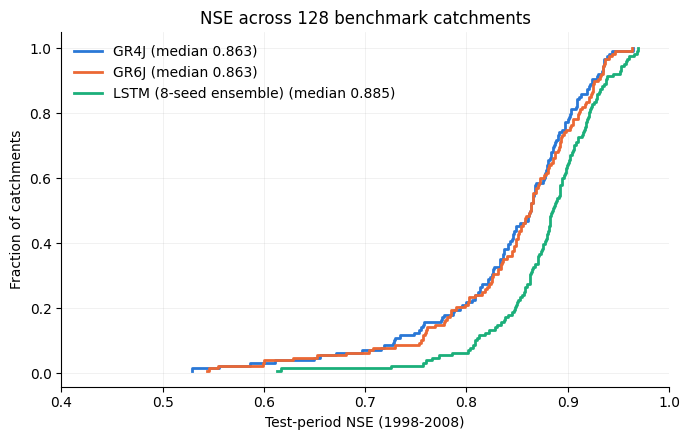

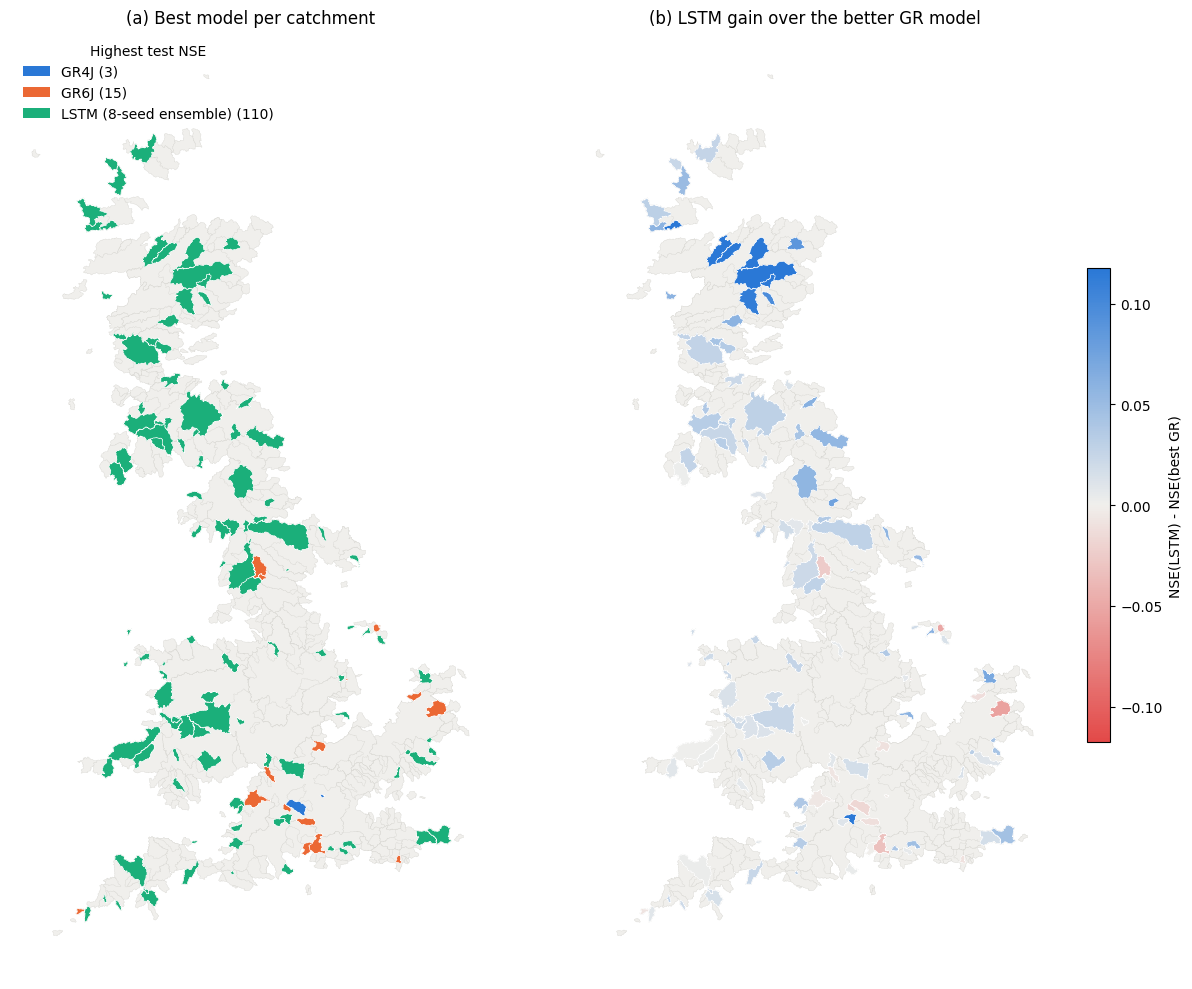


Largest LSTM gains:
          NSE_GR4J  NSE_GR6J  NSE_LSTM   gain                 gauge_name        regime
gauge_id                                                                              
7001         0.529     0.544     0.810  0.267      Findhorn at Shenachie       wet/mid
8004         0.529     0.546     0.813  0.266        Avon at Delnashaugh  mid/baseflow
12001        0.655     0.652     0.875  0.220             Dee at Woodend  wet/baseflow
8009         0.611     0.629     0.830  0.200  Dulnain at Balnaan Bridge       mid/mid
39028        0.650     0.681     0.862  0.181          Dun at Hungerford  dry/baseflow
12005        0.697     0.708     0.850  0.142        Muick at Invermuick       wet/mid
4005         0.754     0.760     0.880  0.120         Meig at Glenmeanie    wet/flashy
15025        0.748     0.759     0.871  0.112        Ericht at Craighall       wet/mid

Where GR beats the LSTM most:
          NSE_GR4J  NSE_GR6J  NSE_LSTM   gain                         gauge_na

In [5]:
# =============================================================================
# CELL 18 - Compare GR4J, GR6J and the LSTM ensemble: paired tests, regimes,
# NSE distribution and maps of where each model wins
# =============================================================================
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

DATA_DIR = ROOT / "data/camels_gb_v2"
MODELS = ["GR4J", "GR6J", "LSTM_ensemble"]
COLORS = {"GR4J": "#2a78d6", "GR6J": "#eb6834", "LSTM_ensemble": "#1baf7a"}  # CVD-checked
LABELS = {"GR4J": "GR4J", "GR6J": "GR6J", "LSTM_ensemble": "LSTM (8-seed ensemble)"}

df = pd.read_csv(CMP_DIR / "metrics_test_all_models.csv", dtype={"gauge_id": str})
df = df[df["model"].isin(MODELS)]

# --- Step 1: paired Wilcoxon tests with Holm correction ----------------------
# "higher" = higher is better; "abs" = smaller |bias| is better; "lower" = lower is better
CRITERIA = {"NSE": "higher", "KGE": "higher", "FHV": "abs", "FMS": "abs",
            "FLV": "abs", "Peak-Timing": "lower"}
PAIRS = [("LSTM_ensemble", "GR4J"), ("LSTM_ensemble", "GR6J"), ("GR6J", "GR4J")]

tests = []
for metric, rule in CRITERIA.items():
    wide = df.pivot(index="gauge_id", columns="model", values=metric)
    for a, b in PAIRS:
        x, y = wide[a], wide[b]
        ok = x.notna() & y.notna()
        if rule == "higher":
            gain = x[ok] - y[ok]                    # > 0 means a is better
        elif rule == "lower":
            gain = y[ok] - x[ok]
        else:
            gain = y[ok].abs() - x[ok].abs()        # > 0 means a has smaller |bias|
        tests.append({"metric": metric, "comparison": f"{a} vs {b}",
                      "a_better_in": f"{(gain > 0).sum()}/{ok.sum()}",
                      "median_gain": gain.median(),
                      "p_raw": wilcoxon(gain[gain != 0]).pvalue})
tests = pd.DataFrame(tests)
tests["p_holm"] = multipletests(tests["p_raw"], method="holm")[1]
tests["significant"] = np.where(tests["p_holm"] < 0.05, "yes", "no")
print("Paired comparisons (test period). median_gain > 0 favours the first model:")
print(tests.round({"median_gain": 3, "p_raw": 4, "p_holm": 4}).to_string(index=False))
tests.to_csv(CMP_DIR / "paired_tests.csv", index=False)

# --- Step 2: results by aridity/BFI regime -----------------------------------
print("\nMedian test NSE by regime:")
print(df.pivot_table(index="regime", columns="model", values="NSE", aggfunc="median").round(3).to_string())
print("\nMedian test FLV (low-flow bias, %) by regime:")
print(df.pivot_table(index="regime", columns="model", values="FLV", aggfunc="median").round(1).to_string())

nse = df.pivot(index="gauge_id", columns="model", values="NSE")
best = nse[MODELS].idxmax(axis=1).rename("best_model")
regime = df.drop_duplicates("gauge_id").set_index("gauge_id")["regime"]
print("\nBest model by NSE - number of catchments per regime:")
print(pd.crosstab(regime, best, margins=True).to_string())

# --- Step 3: cumulative distribution of test NSE (as in Kratzert/Lees) -------
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in MODELS:
    v = np.sort(nse[m].dropna().values)
    cdf = np.arange(1, len(v) + 1) / len(v)
    ax.step(v, cdf, where="post", lw=2, color=COLORS[m],
            label=f"{LABELS[m]} (median {np.median(v):.3f})")
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("Test-period NSE (1998-2008)")
ax.set_ylabel("Fraction of catchments")
ax.grid(alpha=0.25, lw=0.5)
ax.legend(frameon=False, loc="upper left")
ax.set_title(f"NSE across {len(nse)} benchmark catchments")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(CMP_DIR / "nse_cdf.png", dpi=200)
plt.show()

# --- Step 4: maps - best model, and LSTM gain over the best GR model ---------
gdf = gpd.read_file(DATA_DIR / "Catchment_Boundaries/camels_gb_v2_catchment_boundaries.shp")
gdf["gauge_id"] = gdf["ID"].astype(int).astype(str)
gdf = gdf.merge(best, left_on="gauge_id", right_index=True, how="left")
gdf["d_nse"] = (nse["LSTM_ensemble"] - nse[["GR4J", "GR6J"]].max(axis=1)).reindex(gdf["gauge_id"]).values
sel = gdf[gdf["best_model"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(13, 10))

# (a) which model has the highest NSE in each catchment
ax = axes[0]
gdf.plot(ax=ax, facecolor="#f0efec", edgecolor="#d6d5d0", linewidth=0.2)
for m in MODELS:
    part = sel[sel["best_model"] == m]
    if len(part):
        part.plot(ax=ax, facecolor=COLORS[m], edgecolor="white", linewidth=0.4)
counts = sel["best_model"].value_counts()
ax.legend(handles=[Patch(facecolor=COLORS[m], label=f"{LABELS[m]} ({counts.get(m, 0)})")
                   for m in MODELS], loc="upper left", frameon=False, title="Highest test NSE")
ax.set_title("(a) Best model per catchment")
ax.set_axis_off()

# (b) LSTM ensemble NSE minus the better of GR4J/GR6J (red = GR better, blue = LSTM better)
ax = axes[1]
div = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
lim = np.nanpercentile(np.abs(sel["d_nse"]), 95)
gdf.plot(ax=ax, facecolor="#f0efec", edgecolor="#d6d5d0", linewidth=0.2)
sel.plot(ax=ax, column="d_nse", cmap=div, norm=TwoSlopeNorm(0, -lim, lim),
         edgecolor="white", linewidth=0.4, legend=True,
         legend_kwds={"label": "NSE(LSTM) - NSE(best GR)", "shrink": 0.5})
ax.set_title("(b) LSTM gain over the better GR model")
ax.set_axis_off()

plt.tight_layout()
plt.savefig(CMP_DIR / "maps_best_model.png", dpi=200)
plt.show()

# --- Step 5: catchments where the LSTM gains or loses most -------------------
tab = pd.DataFrame({"NSE_GR4J": nse["GR4J"], "NSE_GR6J": nse["GR6J"],
                    "NSE_LSTM": nse["LSTM_ensemble"],
                    "gain": nse["LSTM_ensemble"] - nse[["GR4J", "GR6J"]].max(axis=1)})
tab = tab.join(df.drop_duplicates("gauge_id").set_index("gauge_id")[["gauge_name", "regime"]])
print("\nLargest LSTM gains:")
print(tab.nlargest(8, "gain").round(3).to_string())
print("\nWhere GR beats the LSTM most:")
print(tab.nsmallest(8, "gain").round(3).to_string())
print(f"\nFigures and tables saved in: {CMP_DIR}")

In [6]:
%%writefile /content/drive/MyDrive/rainfall_runoff_benchmark/gr_cemaneige.R
# =============================================================================
# gr_cemaneige.R - Calibrate CemaNeige-GR4J or CemaNeige-GR6J (Valery et al., 2014)
# Same protocol as gr_calibrate.R: warm-up 1985-87 | calibration 1988-97 (NSE,
# Calibration_Michel) | test 1998-2008. Forcing: CEH-GEAR, CHESS-PE, CHESS-met T.
# Run with:  Rscript gr_cemaneige.R GR4J   (or GR6J)
# =============================================================================
suppressPackageStartupMessages(library(airGR))

base <- commandArgs(trailingOnly = TRUE)[1]                 # "GR4J" or "GR6J"
stopifnot(base %in% c("GR4J", "GR6J"))
FUN   <- if (base == "GR4J") RunModel_CemaNeigeGR4J else RunModel_CemaNeigeGR6J
model <- paste0("CemaNeige", base)                           # used in file names

# --- Paths -------------------------------------------------------------------
root      <- "/content/drive/MyDrive/rainfall_runoff_benchmark"
daily_dir <- file.path(root, "data/camels_gb_v2/Catchment_Timeseries/hydro-meteorological/daily")
out_dir   <- file.path(root, "outputs/gr_models")
dir.create(file.path(out_dir, "sim"),    recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(out_dir, "params"), recursive = TRUE, showWarnings = FALSE)

gauges <- as.character(read.csv(file.path(root, "outputs/catchment_selection/eligible_catchments.csv"))$gauge_id)
files  <- list.files(daily_dir, pattern = "\\.csv$", full.names = TRUE)
names(files) <- sub(".*timeseries_([0-9]+)_.*", "\\1", basename(files))

# --- Hypsometry: 101 elevation quantiles interpolated from CAMELS-GB values --
topo <- read.csv(file.path(root, "data/camels_gb_v2/Catchment_Attributes/camels_gb_v2_topographic_attributes.csv"))
topo$gauge_id <- as.character(topo$gauge_id)
hypso_for <- function(gid) {
  r <- topo[topo$gauge_id == gid, ]
  approx(x = c(0, 10, 50, 90, 100),
         y = c(r$elev_min, r$elev_10, r$elev_50, r$elev_90, r$elev_max),
         xout = 0:100)$y                                     # min, q01..q99, max
}

# --- Periods -------------------------------------------------------------------
P_WARM  <- c("1985-01-01", "1987-12-31")
P_TRAIN <- c("1988-01-01", "1997-12-31")
P_TEST  <- c("1998-01-01", "2008-12-31")

# --- Metrics (missing observed days ignored) ---------------------------------
nse <- function(s, o) { k <- !is.na(s) & !is.na(o)
  1 - sum((s[k] - o[k])^2) / sum((o[k] - mean(o[k]))^2) }
kge <- function(s, o) { k <- !is.na(s) & !is.na(o)            # Gupta et al. (2009)
  r <- cor(s[k], o[k]); a <- sd(s[k]) / sd(o[k]); b <- mean(s[k]) / mean(o[k])
  1 - sqrt((r - 1)^2 + (a - 1)^2 + (b - 1)^2) }

# --- Loop over catchments, one at a time, printing progress ------------------
t_all <- Sys.time()
for (i in seq_along(gauges)) {
  gid <- gauges[i]
  par_file <- file.path(out_dir, "params", paste0(model, "_", gid, ".csv"))
  if (file.exists(par_file)) { cat(sprintf("[%3d/%d] %s %-7s already done - skipped\n",
                                           i, length(gauges), model, gid)); next }
  t0 <- Sys.time()
  res <- tryCatch({
    # read daily data from warm-up start to end of test period
    d <- read.csv(files[[gid]])
    d$date <- as.POSIXct(substr(d$date, 1, 10), tz = "UTC")
    d <- d[d$date >= as.POSIXct(P_WARM[1], tz = "UTC") &
           d$date <= as.POSIXct(P_TEST[2], tz = "UTC"), ]
    idx <- function(p) which(d$date >= as.POSIXct(p[1], tz = "UTC") &
                             d$date <= as.POSIXct(p[2], tz = "UTC"))
    i_warm <- idx(P_WARM); i_train <- idx(P_TRAIN); i_test <- idx(P_TEST)
    i_all  <- c(i_train, i_test)

    # inputs: rainfall, PET, mean air temperature + 5 elevation layers
    inputs <- CreateInputsModel(FUN_MOD = FUN, DatesR = d$date,
                                Precip = d$precipitation_cehgear, PotEvap = d$pet_chess,
                                TempMean = d$temperature_chess,
                                HypsoData = hypso_for(gid), NLayers = 5, verbose = FALSE)

    # calibrate on 1988-97, maximising NSE (6 or 8 parameters)
    run_cal  <- suppressWarnings(CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                 IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_train,
                                 verbose = FALSE))
    crit_cal <- CreateInputsCrit(FUN_CRIT = ErrorCrit_NSE, InputsModel = inputs,
                                 RunOptions = run_cal, Obs = d$discharge_spec[i_train])
    cal <- Calibration_Michel(InputsModel = inputs, RunOptions = run_cal,
                              InputsCrit = crit_cal,
                              CalibOptions = CreateCalibOptions(FUN_MOD = FUN),
                              FUN_MOD = FUN, verbose = FALSE)
    par <- cal$ParamFinalR

    # continuous run 1988-2008 with the calibrated parameters
    run_all <- suppressWarnings(CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_all,
                                verbose = FALSE))
    sim <- FUN(InputsModel = inputs, RunOptions = run_all, Param = par)$Qsim
    obs <- d$discharge_spec[i_all]
    tr  <- seq_along(i_train); te <- (length(i_train) + 1):length(i_all)

    # save simulated vs observed series
    write.csv(data.frame(date = format(d$date[i_all], "%Y-%m-%d"), q_obs = obs, q_sim = sim),
              file.path(out_dir, "sim", paste0(model, "_", gid, ".csv")), row.names = FALSE)

    out <- data.frame(gauge_id = gid, model = model,
                      nse_train = nse(sim[tr], obs[tr]), kge_train = kge(sim[tr], obs[tr]),
                      nse_test  = nse(sim[te], obs[te]), kge_test  = kge(sim[te], obs[te]))
    out[paste0("X", seq_along(par))] <- as.list(par)
    write.csv(out, par_file, row.names = FALSE)
    sprintf("test NSE = %.3f, KGE = %.3f", out$nse_test, out$kge_test)
  }, error = function(e) paste("ERROR:", conditionMessage(e)))

  cat(sprintf("[%3d/%d] %s %-7s %5.1f s  %s\n", i, length(gauges), model, gid,
              as.numeric(difftime(Sys.time(), t0, units = "secs")), res))
  flush.console()
}
cat(sprintf("\n%s finished in %.1f min\n", model,
            as.numeric(difftime(Sys.time(), t_all, units = "mins"))))

Writing /content/drive/MyDrive/rainfall_runoff_benchmark/gr_cemaneige.R


In [7]:
# =============================================================================
# CELL 19b - Calibrate CemaNeige-GR4J and CemaNeige-GR6J on the 128 catchments
# =============================================================================
from google.colab import drive
drive.mount("/content/drive")

# airGR for command-line R (installs once per session)
!Rscript -e 'if (!requireNamespace("airGR", quietly=TRUE)) install.packages("airGR", repos="https://cloud.r-project.org", quiet=TRUE)'

!Rscript /content/drive/MyDrive/rainfall_runoff_benchmark/gr_cemaneige.R GR4J
!Rscript /content/drive/MyDrive/rainfall_runoff_benchmark/gr_cemaneige.R GR6J

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[  1/128] CemaNeigeGR4J 102001    7.3 s  test NSE = 0.778, KGE = 0.746
[  2/128] CemaNeigeGR4J 11004     5.7 s  test NSE = 0.886, KGE = 0.938
[  3/128] CemaNeigeGR4J 12001     5.1 s  test NSE = 0.820, KGE = 0.892
[  4/128] CemaNeigeGR4J 12005     5.4 s  test NSE = 0.841, KGE = 0.915
[  5/128] CemaNeigeGR4J 13004     5.4 s  test NSE = 0.823, KGE = 0.829
[  6/128] CemaNeigeGR4J 15023     5.0 s  test NSE = 0.895, KGE = 0.907
[  7/128] CemaNeigeGR4J 15025     8.0 s  test NSE = 0.824, KGE = 0.881
[  8/128] CemaNeigeGR4J 16003     4.9 s  test NSE = 0.886, KGE = 0.895
[  9/128] CemaNeigeGR4J 17005     3.3 s  test NSE = 0.867, KGE = 0.872
[ 10/128] CemaNeigeGR4J 18001     3.2 s  test NSE = 0.851, KGE = 0.892
[ 11/128] CemaNeigeGR4J 18011     3.0 s  test NSE = 0.930, KGE = 0.928
[ 12/128] CemaNeigeGR4J 20007     3.3 s  test NSE = 0.861, KGE = 0.781
[ 13/128] CemaNeige

In [8]:
# =============================================================================
# CELL 20 - Effect of the CemaNeige snow module, and whether it closes the gap
# to the LSTM. Same metric function (neuralhydrology) and test period as before
# =============================================================================
!pip install -q neuralhydrology

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import wilcoxon, spearmanr
from statsmodels.stats.multitest import multipletests
from neuralhydrology.evaluation.metrics import calculate_all_metrics

ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
GR_DIR, CMP_DIR = ROOT / "outputs/gr_models", ROOT / "outputs/comparison"
TEST = ("1998-01-01", "2008-12-31")

# --- Step 1: test-period metrics for the two CemaNeige models ----------------
rows = []
for f in sorted((GR_DIR / "sim").glob("CemaNeige*.csv")):
    model, gid = f.stem.split("_", 1)
    df = pd.read_csv(f, parse_dates=["date"]).set_index("date").loc[TEST[0]:TEST[1]]
    obs = xr.DataArray(df["q_obs"].values, coords={"date": df.index}, dims=["date"])
    sim = xr.DataArray(df["q_sim"].values, coords={"date": df.index}, dims=["date"])
    rows.append({"model": model, "gauge_id": gid, **calculate_all_metrics(obs, sim, resolution="1D")})
cn = pd.DataFrame(rows)
print("CemaNeige catchments evaluated:", cn.groupby("model")["gauge_id"].nunique().to_dict())

# --- Step 2: add to the full comparison table --------------------------------
allm = pd.read_csv(CMP_DIR / "metrics_test_all_models.csv", dtype={"gauge_id": str})
allm = allm[~allm["model"].str.startswith("CemaNeige")]            # avoid duplicates on rerun
info = allm.drop_duplicates("gauge_id")[["gauge_id", "gauge_name", "regime", "aridity", "baseflow_index"]]
allm = pd.concat([allm, cn.merge(info, on="gauge_id", how="left")], ignore_index=True)
allm.to_csv(CMP_DIR / "metrics_test_all_models.csv", index=False)

MODELS = ["GR4J", "CemaNeigeGR4J", "GR6J", "CemaNeigeGR6J", "LSTM_ensemble"]
main = allm[allm["model"].isin(MODELS)]
cols = ["NSE", "KGE", "Pearson-r", "FHV", "FMS", "FLV", "Peak-Timing"]
print("\nTest-period medians (1998-2008):")
print(main.groupby("model")[cols].median().reindex(MODELS).round(3).T.to_string())

# --- Step 3: paired NSE tests (Holm-corrected) -------------------------------
nse = main.pivot(index="gauge_id", columns="model", values="NSE")
pairs = [("CemaNeigeGR4J", "GR4J"), ("CemaNeigeGR6J", "GR6J"),
         ("LSTM_ensemble", "CemaNeigeGR4J"), ("LSTM_ensemble", "CemaNeigeGR6J")]
tests = []
for a, b in pairs:
    gain = (nse[a] - nse[b]).dropna()
    tests.append({"comparison": f"{a} vs {b}", "a_better_in": f"{(gain > 0).sum()}/{len(gain)}",
                  "median_gain": gain.median(), "p_raw": wilcoxon(gain[gain != 0]).pvalue})
tests = pd.DataFrame(tests)
tests["p_holm"] = multipletests(tests["p_raw"], method="holm")[1]
print("\nPaired NSE comparisons (median_gain > 0 favours the first model):")
print(tests.round(4).to_string(index=False))

# --- Step 4: is the improvement linked to snow? ------------------------------
clim = pd.read_csv(ROOT / "data/camels_gb_v2/Catchment_Attributes/camels_gb_v2_climatic_attributes.csv",
                   dtype={"gauge_id": str}).set_index("gauge_id")
snow = clim["frac_snow"].reindex(nse.index)
best_gr        = nse[["GR4J", "GR6J"]].max(axis=1)
best_gr_snow   = nse[["CemaNeigeGR4J", "CemaNeigeGR6J"]].max(axis=1)
snow_gain      = best_gr_snow - best_gr                       # what the snow module adds
lstm_gap_before = nse["LSTM_ensemble"] - best_gr              # LSTM advantage, no snow module
lstm_gap_after  = nse["LSTM_ensemble"] - best_gr_snow         # LSTM advantage, with snow module

print("\nSpearman correlation with frac_snow (fraction of precipitation falling as snow):")
for name, s in [("NSE gain from snow module", snow_gain),
                ("LSTM advantage over GR (no snow)", lstm_gap_before),
                ("LSTM advantage over GR (with snow)", lstm_gap_after)]:
    rho, p = spearmanr(snow, s, nan_policy="omit")
    print(f"  {name:<36} rho = {rho:+.2f}  (p = {p:.3g})")

# --- Step 5: the snowiest catchments in detail -------------------------------
tab = pd.DataFrame({"frac_snow": snow, "GR_best": best_gr, "GR_snow_best": best_gr_snow,
                    "LSTM": nse["LSTM_ensemble"], "gap_before": lstm_gap_before,
                    "gap_after": lstm_gap_after})
tab = tab.join(info.set_index("gauge_id")["gauge_name"])
print("\n10 snowiest catchments (NSE, test period):")
print(tab.nlargest(10, "frac_snow").round(3).to_string())
print(f"\nMedian LSTM advantage: {lstm_gap_before.median():+.3f} without snow module -> "
      f"{lstm_gap_after.median():+.3f} with snow module")

CemaNeige catchments evaluated: {'CemaNeigeGR4J': 128, 'CemaNeigeGR6J': 128}

Test-period medians (1998-2008):
model          GR4J  CemaNeigeGR4J    GR6J  CemaNeigeGR6J  LSTM_ensemble
NSE           0.863          0.868   0.863          0.869          0.885
KGE           0.870          0.878   0.873          0.882          0.872
Pearson-r     0.932          0.936   0.931          0.935          0.946
FHV         -11.633         -9.833 -10.839        -10.050        -11.032
FMS          -3.493         -3.118  -1.781         -3.810         -4.446
FLV         -35.468        -40.810  -8.776          1.004         25.099
Peak-Timing   0.312          0.302   0.318          0.280          0.261

Paired NSE comparisons (median_gain > 0 favours the first model):
                    comparison a_better_in  median_gain  p_raw  p_holm
         CemaNeigeGR4J vs GR4J      94/128       0.0011    0.0     0.0
         CemaNeigeGR6J vs GR6J      96/128       0.0014    0.0     0.0
LSTM_ensemble vs CemaNeig

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


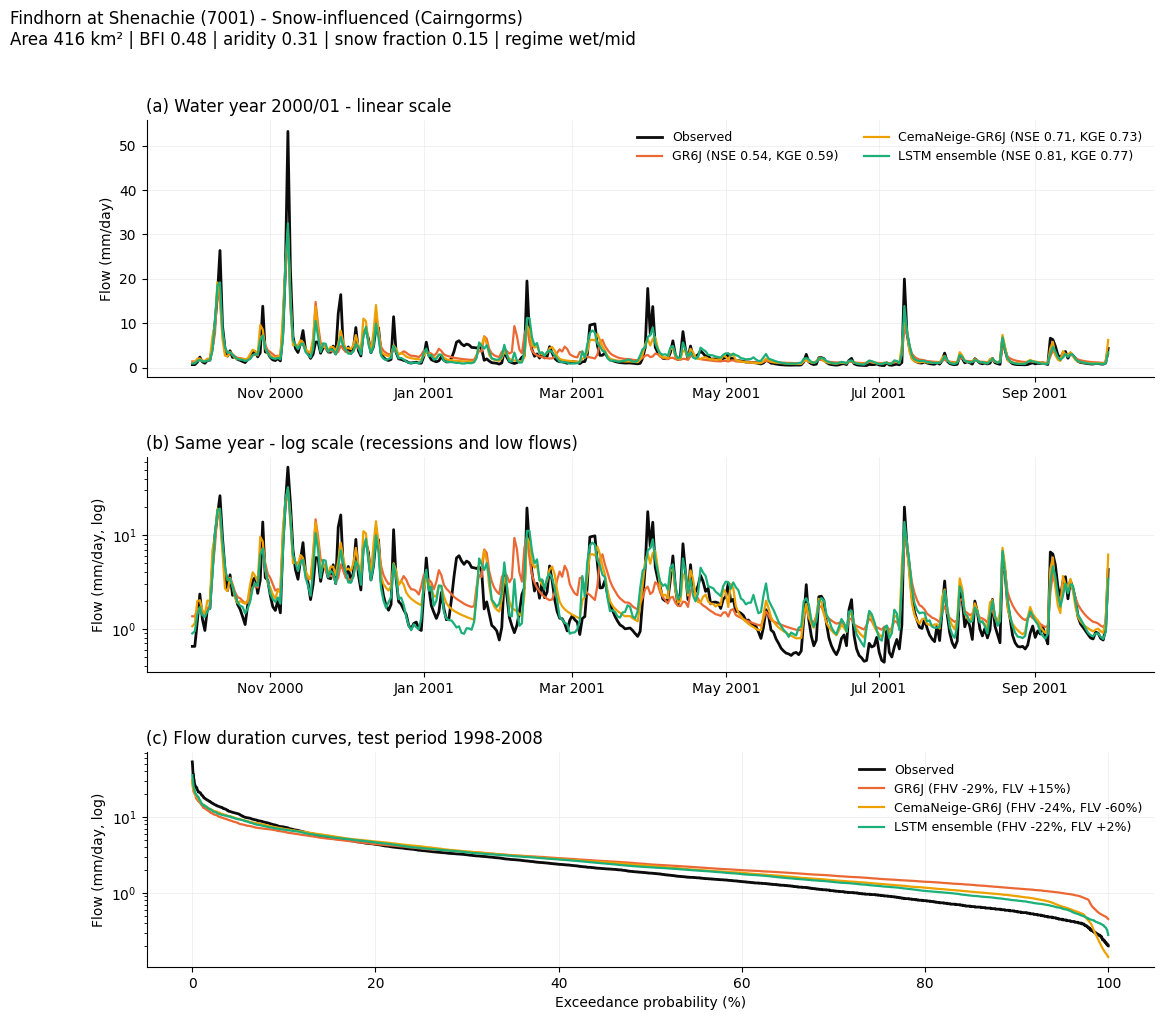

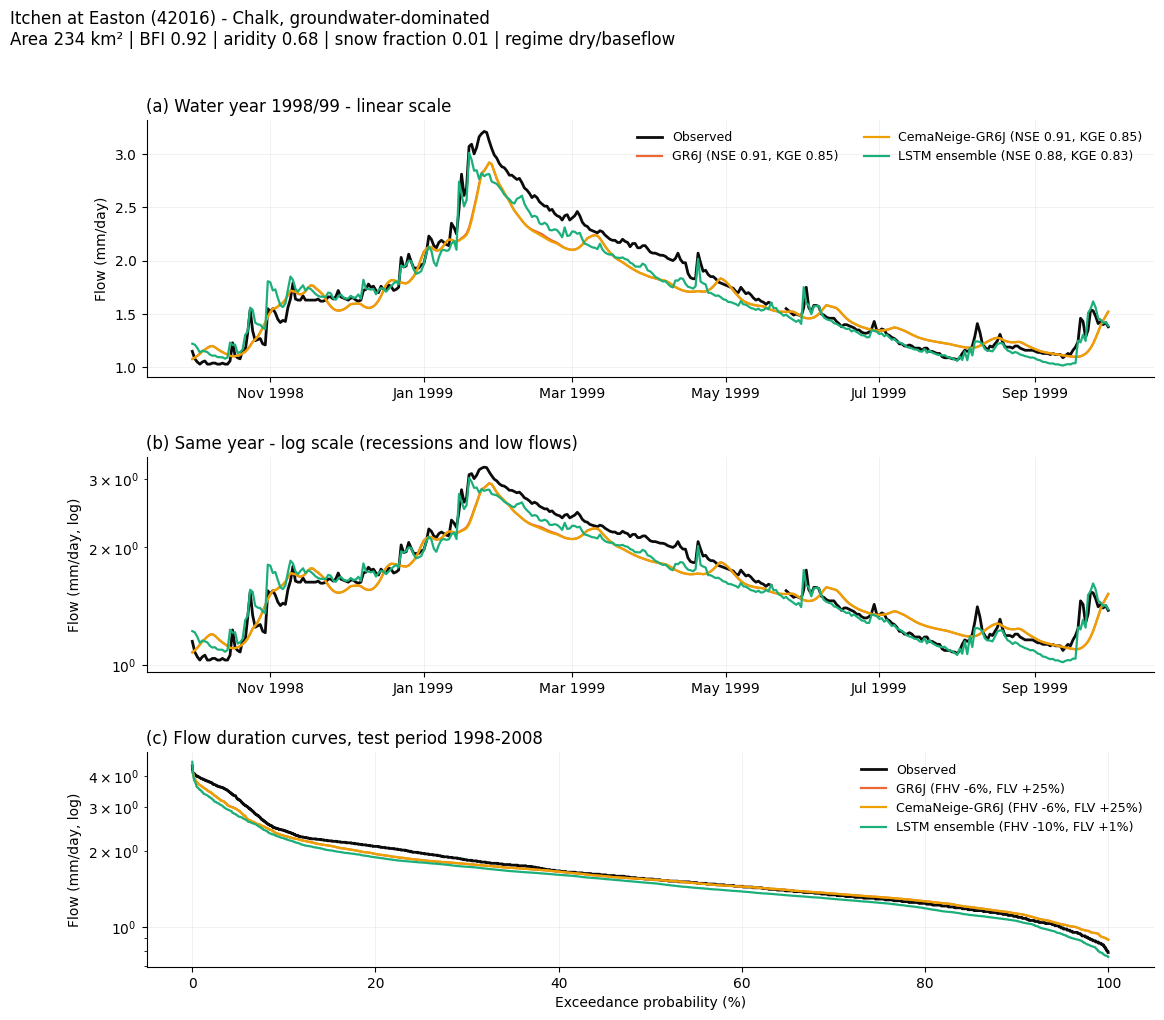

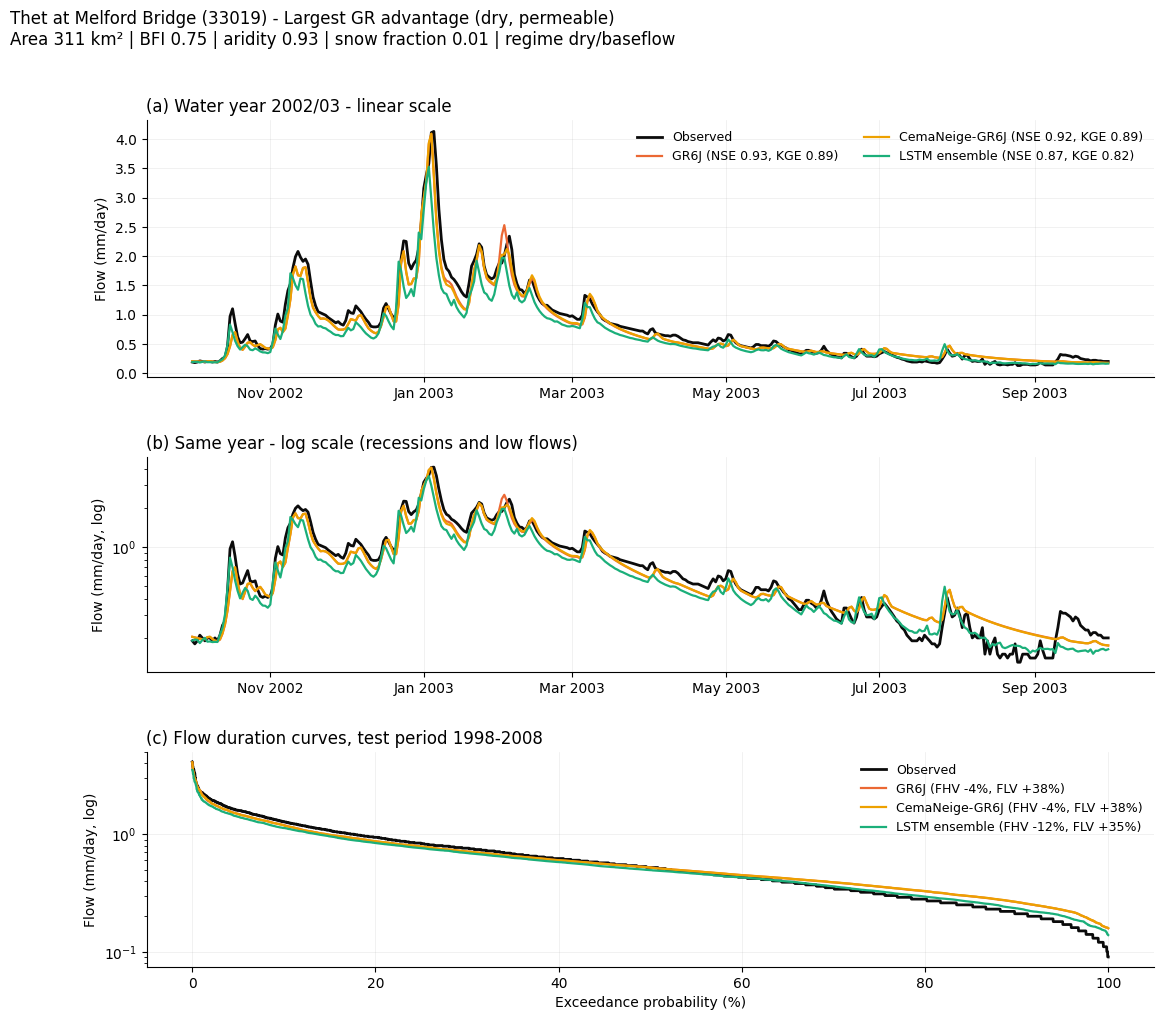

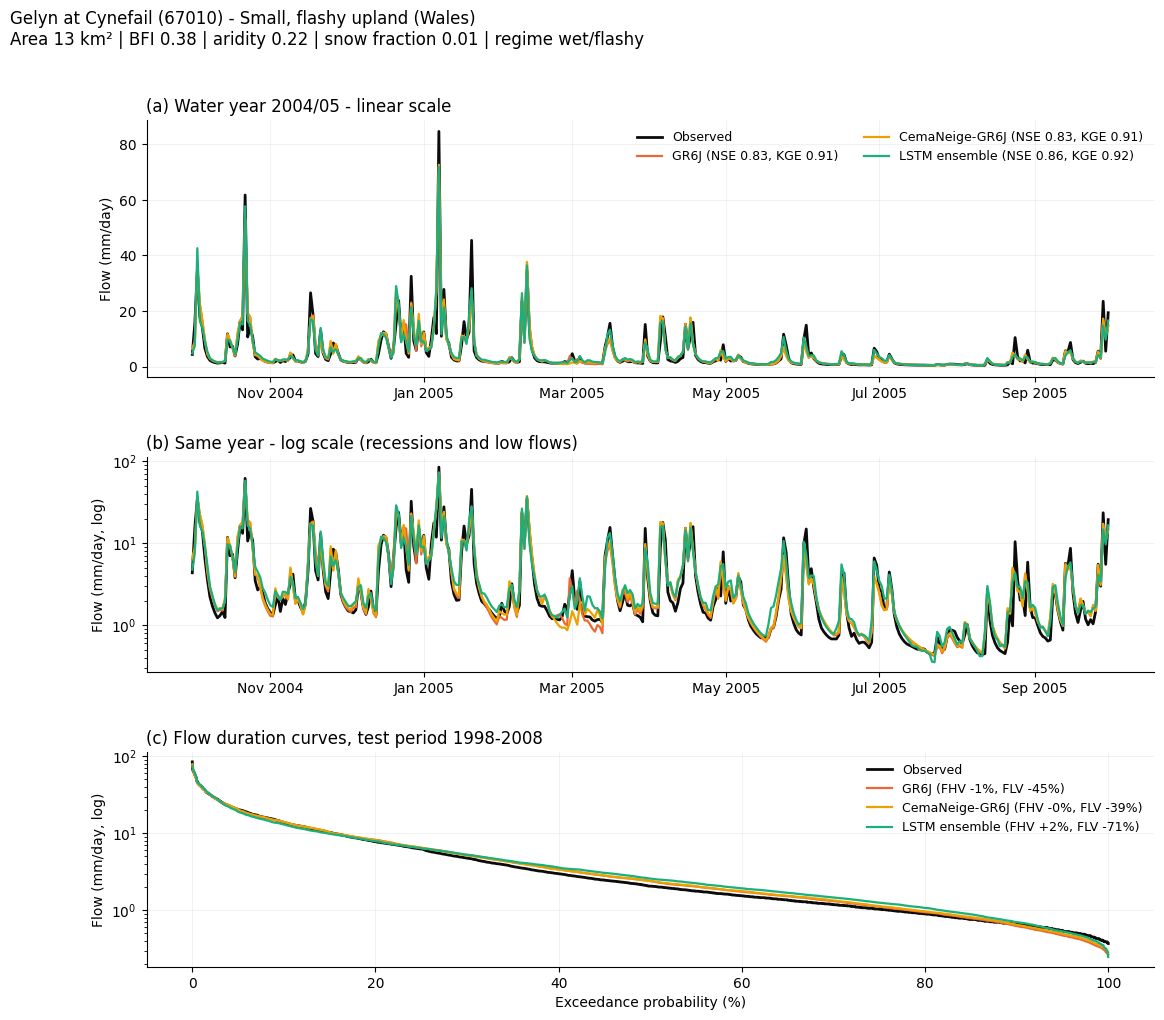

gauge_id              catchment                                 story water_year  NSE_GR6J  NSE_CemaNeigeGR6J  NSE_LSTM_ensemble
    7001  Findhorn at Shenachie          Snow-influenced (Cairngorms)    2000/01     0.544              0.715              0.810
   42016       Itchen at Easton          Chalk, groundwater-dominated    1998/99     0.915              0.914              0.882
   33019 Thet at Melford Bridge Largest GR advantage (dry, permeable)    2002/03     0.925              0.923              0.871
   67010      Gelyn at Cynefail          Small, flashy upland (Wales)    2004/05     0.834              0.835              0.864

Figures saved in: /content/drive/MyDrive/rainfall_runoff_benchmark/outputs/comparison/case_studies


In [9]:
# =============================================================================
# CELL 21 - Case-study hydrographs: observed vs GR6J, CemaNeige-GR6J, LSTM ensemble
# Per catchment: (a) one water year, linear  (b) same year, log scale
#                (c) flow duration curves for the whole test period 1998-2008
# =============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
CMP_DIR = ROOT / "outputs/comparison"
OUT = CMP_DIR / "case_studies"
OUT.mkdir(parents=True, exist_ok=True)
TEST = ("1998-01-01", "2008-12-31")

# --- Case studies (edit freely) ----------------------------------------------
CASES = {
    "7001":  "Snow-influenced (Cairngorms)",
    "42016": "Chalk, groundwater-dominated",
    "33019": "Largest GR advantage (dry, permeable)",
    "67010": "Small, flashy upland (Wales)",
}
# Optional: force a water year per catchment, e.g. {"7001": 2001}
# (2001 = Oct 2000 - Sep 2001). Otherwise the year with the highest observed peak is used.
WATER_YEAR = {}

# --- Models, colours (fixed order, CVD-checked) and file locations ----------
MODELS = {
    "GR6J":          {"label": "GR6J",           "color": "#eb6834",
                      "file": lambda g: ROOT / f"outputs/gr_models/sim/GR6J_{g}.csv"},
    "CemaNeigeGR6J": {"label": "CemaNeige-GR6J", "color": "#eda100",
                      "file": lambda g: ROOT / f"outputs/gr_models/sim/CemaNeigeGR6J_{g}.csv"},
    "LSTM_ensemble": {"label": "LSTM ensemble",  "color": "#1baf7a",
                      "file": lambda g: ROOT / f"outputs/lstm/sim/ensemble/{g}.csv"},
}
OBS_COLOR = "#0b0b0b"

metrics = pd.read_csv(CMP_DIR / "metrics_test_all_models.csv", dtype={"gauge_id": str})
attrs = (pd.read_csv(ROOT / "outputs/catchment_selection/eligible_catchments.csv", dtype={"gauge_id": str})
           .set_index("gauge_id"))
clim = (pd.read_csv(ROOT / "data/camels_gb_v2/Catchment_Attributes/camels_gb_v2_climatic_attributes.csv",
                    dtype={"gauge_id": str}).set_index("gauge_id"))

def load_series(gid):
    """Observed + simulated daily flow (mm/day) for the test period, aligned by date."""
    out = None
    for key, m in MODELS.items():
        d = pd.read_csv(m["file"](gid), parse_dates=["date"]).set_index("date").loc[TEST[0]:TEST[1]]
        if out is None:
            out = d[["q_obs"]].copy()
        out[key] = d["q_sim"]
    return out

def fdc(q):
    """Flow duration curve: exceedance probability (%) and sorted flows."""
    q = np.sort(q.dropna().values)[::-1]
    return 100 * np.arange(1, len(q) + 1) / (len(q) + 1), q

def style(ax):
    """Recessive grid and axes."""
    ax.grid(alpha=0.25, lw=0.5)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

summary = []
for gid, story in CASES.items():
    df = load_series(gid)
    a = attrs.loc[gid]

    # water year (Oct-Sep) with the highest observed peak, unless set by hand
    wy = (df.index + pd.offsets.DateOffset(months=3)).year           # Oct-Dec -> next year
    year = WATER_YEAR.get(gid, int(wy[df["q_obs"].values.argmax()]))
    sel = df[(wy == year)]

    # model labels carry the test-period NSE and KGE
    m = metrics[metrics["gauge_id"] == gid].set_index("model")
    lab = {k: f"{v['label']} (NSE {m.loc[k, 'NSE']:.2f}, KGE {m.loc[k, 'KGE']:.2f})"
           for k, v in MODELS.items()}

    fig = plt.figure(figsize=(13, 11))
    gs = fig.add_gridspec(3, 1, height_ratios=[1.2, 1, 1], hspace=0.35)

    # (a) linear hydrograph - floods and timing
    ax = fig.add_subplot(gs[0])
    ax.plot(sel.index, sel["q_obs"], color=OBS_COLOR, lw=2, label="Observed")
    for k, v in MODELS.items():
        ax.plot(sel.index, sel[k], color=v["color"], lw=1.6, label=lab[k])
    ax.set_ylabel("Flow (mm/day)")
    ax.set_title(f"(a) Water year {year-1}/{str(year)[-2:]} - linear scale", loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend(frameon=False, ncol=2, fontsize=9, loc="upper right")
    style(ax)

    # (b) same year, log scale - recessions and low flows
    ax = fig.add_subplot(gs[1], sharex=ax)
    ax.plot(sel.index, sel["q_obs"], color=OBS_COLOR, lw=2)
    for k, v in MODELS.items():
        ax.plot(sel.index, sel[k], color=v["color"], lw=1.6)
    ax.set_yscale("log")
    ax.set_ylabel("Flow (mm/day, log)")
    ax.set_title("(b) Same year - log scale (recessions and low flows)", loc="left")
    style(ax)

    # (c) flow duration curves, whole test period
    ax = fig.add_subplot(gs[2])
    p, q = fdc(df["q_obs"])
    ax.plot(p, q, color=OBS_COLOR, lw=2, label="Observed")
    for k, v in MODELS.items():
        p, q = fdc(df[k][df["q_obs"].notna()])                     # same days as observed
        ax.plot(p, q, color=v["color"], lw=1.6,
                label=f"{v['label']} (FHV {m.loc[k, 'FHV']:+.0f}%, FLV {m.loc[k, 'FLV']:+.0f}%)")
    ax.set_yscale("log")
    ax.set_xlabel("Exceedance probability (%)")
    ax.set_ylabel("Flow (mm/day, log)")
    ax.set_title("(c) Flow duration curves, test period 1998-2008", loc="left")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    style(ax)

    fig.suptitle(f"{a['gauge_name']} ({gid}) - {story}\n"
                 f"Area {a['area']:.0f} km² | BFI {a['baseflow_index']:.2f} | aridity {a['aridity']:.2f} | "
                 f"snow fraction {clim.loc[gid, 'frac_snow']:.2f} | regime {a['regime']}",
                 fontsize=12, x=0.02, ha="left")
    plt.savefig(OUT / f"case_{gid}.png", dpi=200, bbox_inches="tight")
    plt.show()

    summary.append({"gauge_id": gid, "catchment": a["gauge_name"], "story": story,
                    "water_year": f"{year-1}/{str(year)[-2:]}",
                    **{f"NSE_{k}": round(m.loc[k, "NSE"], 3) for k in MODELS}})

print(pd.DataFrame(summary).to_string(index=False))
print(f"\nFigures saved in: {OUT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


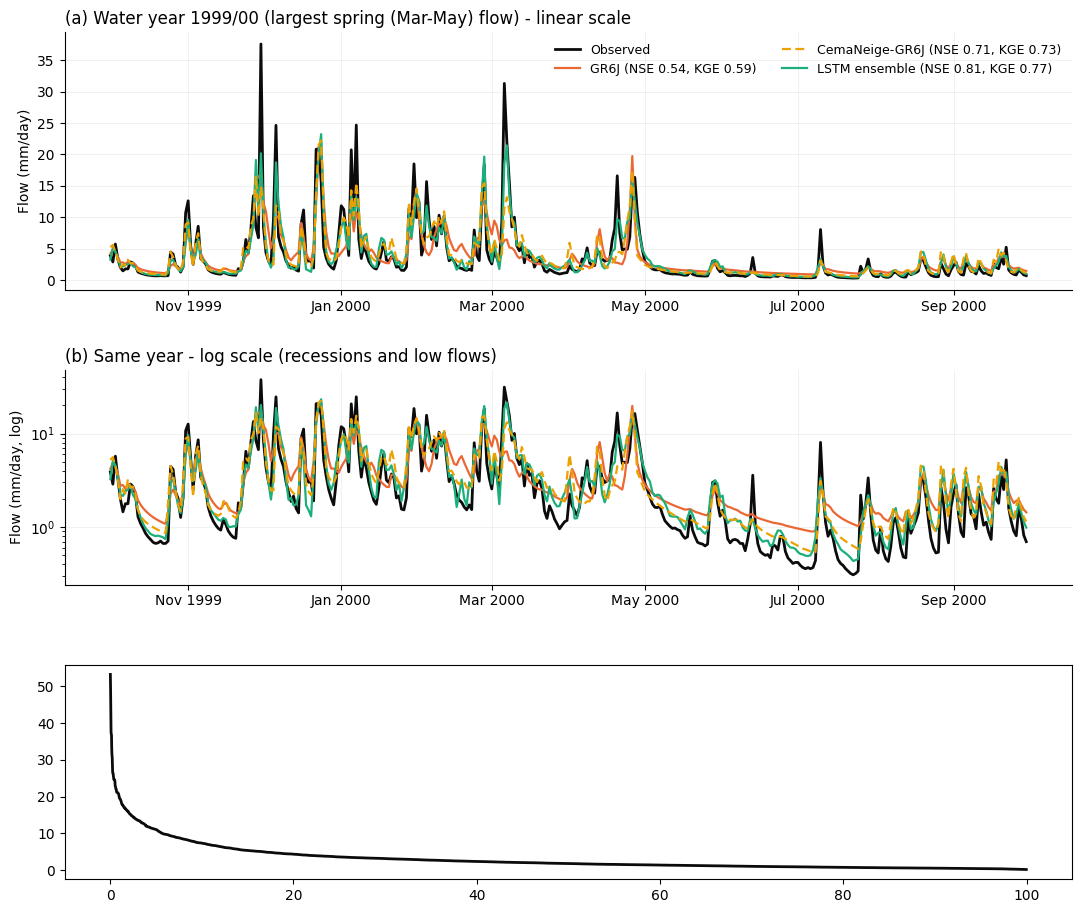

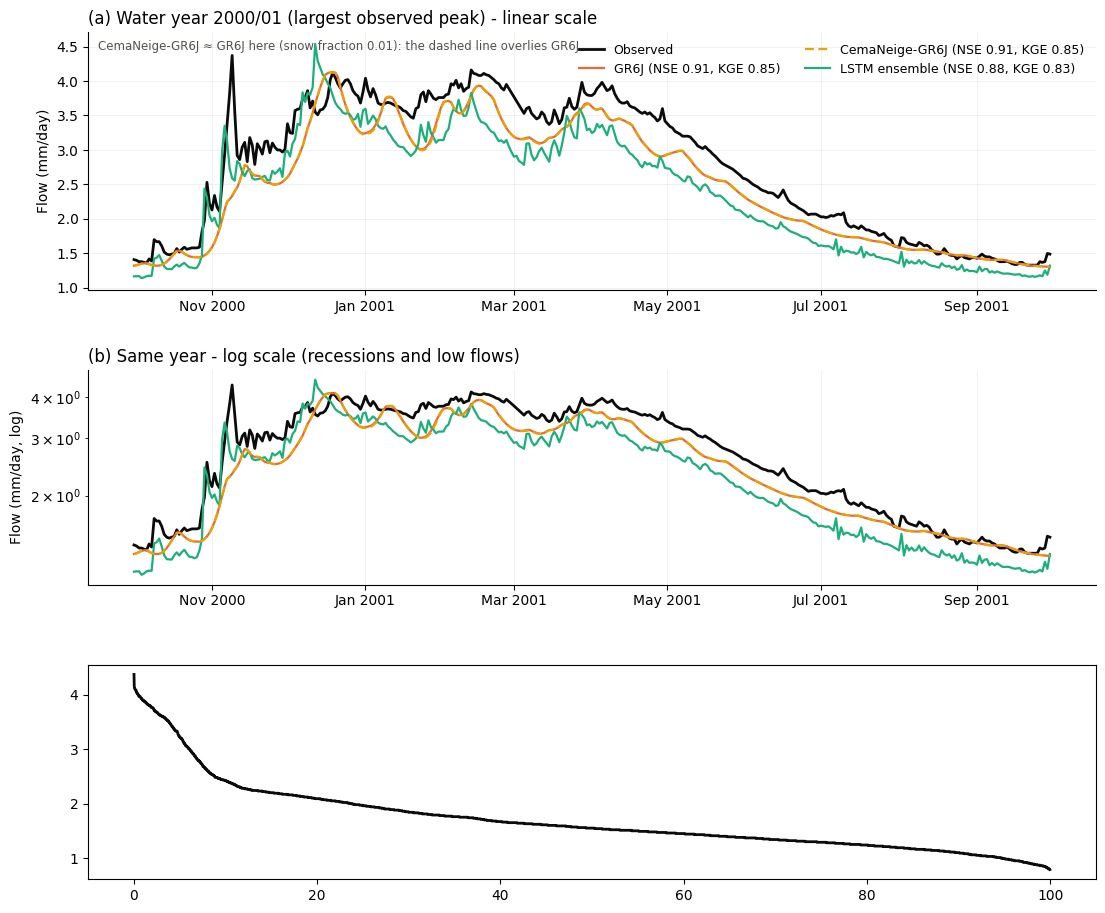

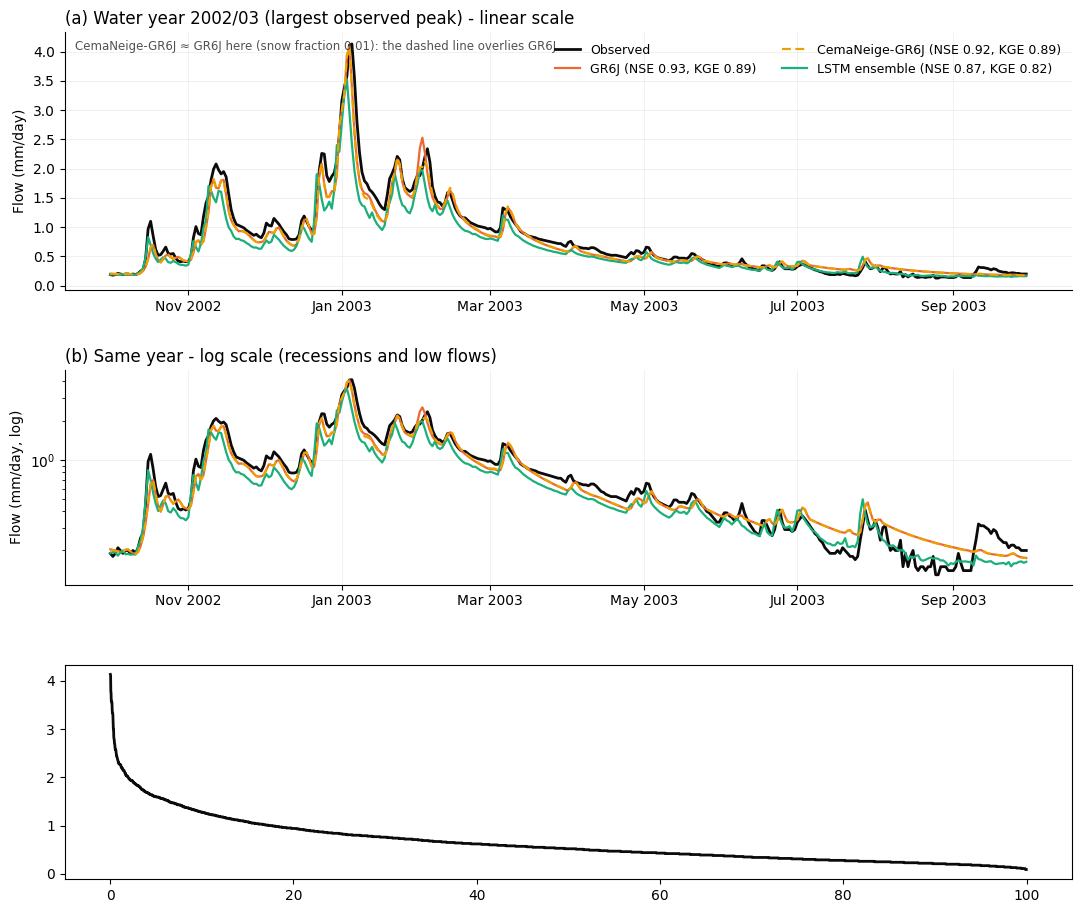

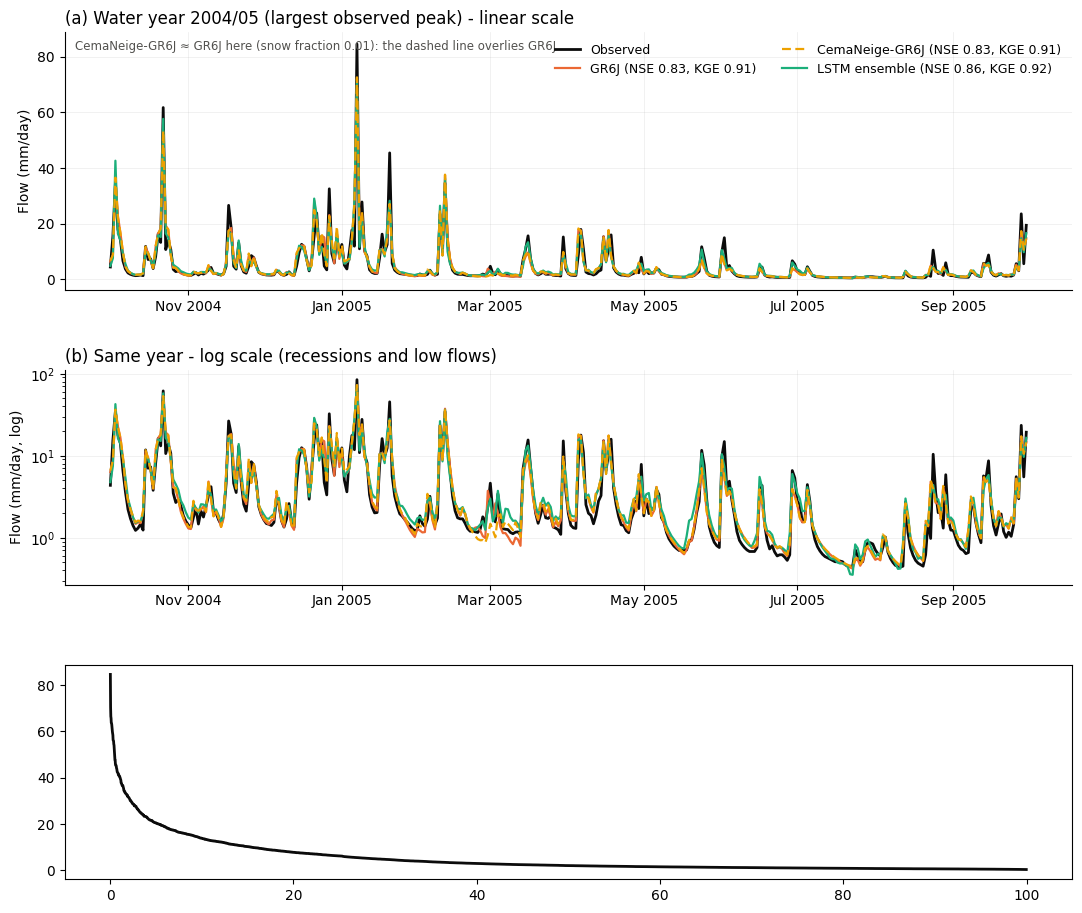

In [10]:
# =============================================================================
# CELL 21 b - Case-study hydrographs: observed vs GR6J, CemaNeige-GR6J, LSTM ensemble
# Per catchment: (a) one water year, linear  (b) same year, log scale
#                (c) flow duration curves for the whole test period 1998-2008
# Water year: snowy catchments -> largest spring (Mar-May) flow; others -> largest peak
# =============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
CMP_DIR = ROOT / "outputs/comparison"
OUT = CMP_DIR / "case_studies"
OUT.mkdir(parents=True, exist_ok=True)
TEST = ("1998-01-01", "2008-12-31")
FULL_WATER_YEARS = range(1999, 2009)        # 1998/99 ... 2007/08 (complete Oct-Sep years)
SNOWY = 0.05                                # frac_snow threshold for choosing a melt year

# --- Case studies (edit freely) ----------------------------------------------
CASES = {
    "7001":  "Snow-influenced (Cairngorms)",
    "42016": "Chalk, groundwater-dominated",
    "33019": "Largest GR advantage (dry, permeable)",
    "67010": "Small, flashy upland (Wales)",
}
# Optional manual override, e.g. {"7001": 2001} (2001 = Oct 2000 - Sep 2001)
WATER_YEAR = {}

# --- Models, colours (fixed order, CVD-checked), line styles and files -------
MODELS = {
    "GR6J":          {"label": "GR6J",           "color": "#eb6834", "ls": "-",
                      "file": lambda g: ROOT / f"outputs/gr_models/sim/GR6J_{g}.csv"},
    "CemaNeigeGR6J": {"label": "CemaNeige-GR6J", "color": "#eda100", "ls": (0, (4, 2)),
                      "file": lambda g: ROOT / f"outputs/gr_models/sim/CemaNeigeGR6J_{g}.csv"},
    "LSTM_ensemble": {"label": "LSTM ensemble",  "color": "#1baf7a", "ls": "-",
                      "file": lambda g: ROOT / f"outputs/lstm/sim/ensemble/{g}.csv"},
}
DRAW_ORDER = ["GR6J", "LSTM_ensemble", "CemaNeigeGR6J"]   # dashed line last, on top
OBS_COLOR = "#0b0b0b"

metrics = pd.read_csv(CMP_DIR / "metrics_test_all_models.csv", dtype={"gauge_id": str})
attrs = (pd.read_csv(ROOT / "outputs/catchment_selection/eligible_catchments.csv", dtype={"gauge_id": str})
           .set_index("gauge_id"))
clim = (pd.read_csv(ROOT / "data/camels_gb_v2/Catchment_Attributes/camels_gb_v2_climatic_attributes.csv",
                    dtype={"gauge_id": str}).set_index("gauge_id"))

def load_series(gid):
    """Observed + simulated daily flow (mm/day) for the test period, aligned by date."""
    out = None
    for key, m in MODELS.items():
        d = pd.read_csv(m["file"](gid), parse_dates=["date"]).set_index("date").loc[TEST[0]:TEST[1]]
        if out is None:
            out = d[["q_obs"]].copy()
        out[key] = d["q_sim"]
    return out

def water_year(index):
    """Water year label: Oct-Dec belong to the following year (Oct 2000 -> 2001)."""
    return (index + pd.offsets.DateOffset(months=3)).year

def choose_year(df, snow_frac):
    """Snowy: year with the largest Mar-May observed flow. Otherwise: largest peak."""
    obs = df["q_obs"]
    wy = pd.Series(water_year(df.index), index=df.index)
    obs, wy = obs[wy.isin(FULL_WATER_YEARS)], wy[wy.isin(FULL_WATER_YEARS)]
    if snow_frac >= SNOWY:
        spring = obs[obs.index.month.isin([3, 4, 5])]
        return int(spring.groupby(wy[spring.index]).mean().idxmax()), "largest spring (Mar-May) flow"
    return int(wy[obs.idxmax()]), "largest observed peak"

def fdc(q):
    """Flow duration curve: exceedance probability (%) and sorted flows."""
    q = np.sort(q.dropna().values)[::-1]
    return 100 * np.arange(1, len(q) + 1) / (len(q) + 1), q

def style(ax):
    """Recessive grid and axes."""
    ax.grid(alpha=0.25, lw=0.5)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

summary = []
for gid, story in CASES.items():
    df = load_series(gid)
    a = attrs.loc[gid]
    snow_frac = clim.loc[gid, "frac_snow"]

    # --- choose the water year to display ------------------------------------
    if gid in WATER_YEAR:
        year, why = WATER_YEAR[gid], "chosen manually"
    else:
        year, why = choose_year(df, snow_frac)
    sel = df[water_year(df.index) == year]

    # --- labels carry test-period NSE and KGE --------------------------------
    m = metrics[metrics["gauge_id"] == gid].set_index("model")
    lab = {k: f"{v['label']} (NSE {m.loc[k, 'NSE']:.2f}, KGE {m.loc[k, 'KGE']:.2f})"
           for k, v in MODELS.items()}
    same_as_gr6j = abs(m.loc["CemaNeigeGR6J", "NSE"] - m.loc["GR6J", "NSE"]) < 0.005

    fig = plt.figure(figsize=(13, 11))
    gs = fig.add_gridspec(3, 1, height_ratios=[1.2, 1, 1], hspace=0.35)

    # (a) linear hydrograph - floods and timing
    ax = fig.add_subplot(gs[0])
    ax.plot(sel.index, sel["q_obs"], color=OBS_COLOR, lw=2, label="Observed")
    for k in DRAW_ORDER:
        v = MODELS[k]
        ax.plot(sel.index, sel[k], color=v["color"], ls=v["ls"], lw=1.6, label=lab[k])
    ax.set_ylabel("Flow (mm/day)")
    ax.set_title(f"(a) Water year {year-1}/{str(year)[-2:]} ({why}) - linear scale", loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    handles, labels = ax.get_legend_handles_labels()
    order = [0] + [1 + DRAW_ORDER.index(k) for k in MODELS]          # legend in model order
    ax.legend([handles[i] for i in order], [labels[i] for i in order],
              frameon=False, ncol=2, fontsize=9, loc="upper right")
    if same_as_gr6j:
        ax.text(0.01, 0.97, "CemaNeige-GR6J ≈ GR6J here (snow fraction "
                f"{snow_frac:.2f}): the dashed line overlies GR6J",
                transform=ax.transAxes, fontsize=8.5, color="#52514e", va="top")
    style(ax)

    # (b) same year, log scale - recessions and low flows
    ax = fig.add_subplot(gs[1], sharex=ax)
    ax.plot(sel.index, sel["q_obs"], color=OBS_COLOR, lw=2)
    for k in DRAW_ORDER:
        v = MODELS[k]
        ax.plot(sel.index, sel[k], color=v["color"], ls=v["ls"], lw=1.6)
    ax.set_yscale("log")
    ax.set_ylabel("Flow (mm/day, log)")
    ax.set_title("(b) Same year - log scale (recessions and low flows)", loc="left")
    style(ax)

    # (c) flow duration curves, whole test period (days with observations only)
    ax = fig.add_subplot(gs[2])
    p, q = fdc(df["q_obs"])
    ax.plot(p, q, color=OBS_COLOR, lw=2, label="Observed")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


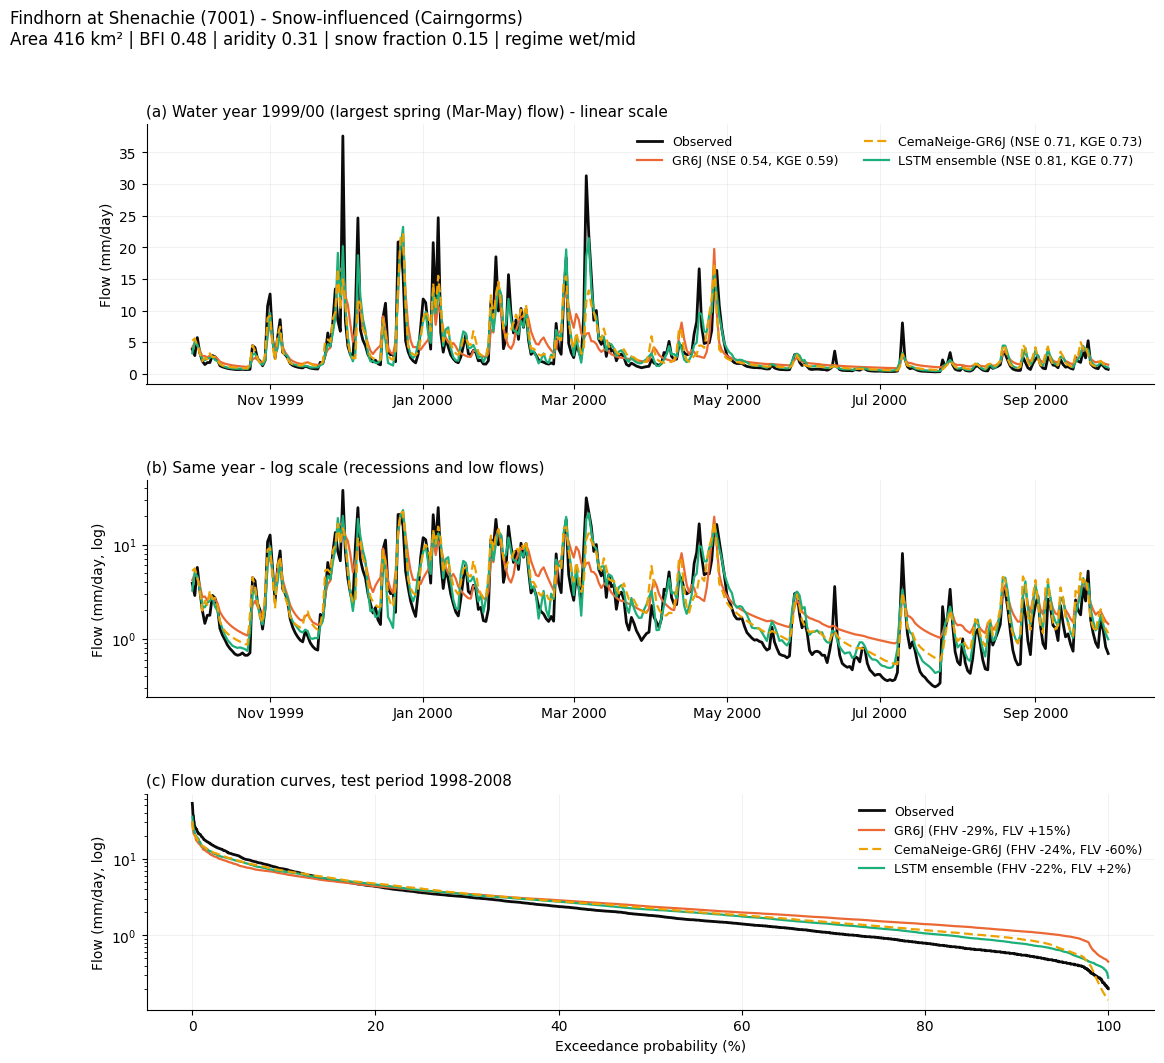

OK  7001 Findhorn at Shenachie: water year 1999/00 (largest spring (Mar-May) flow) -> saved


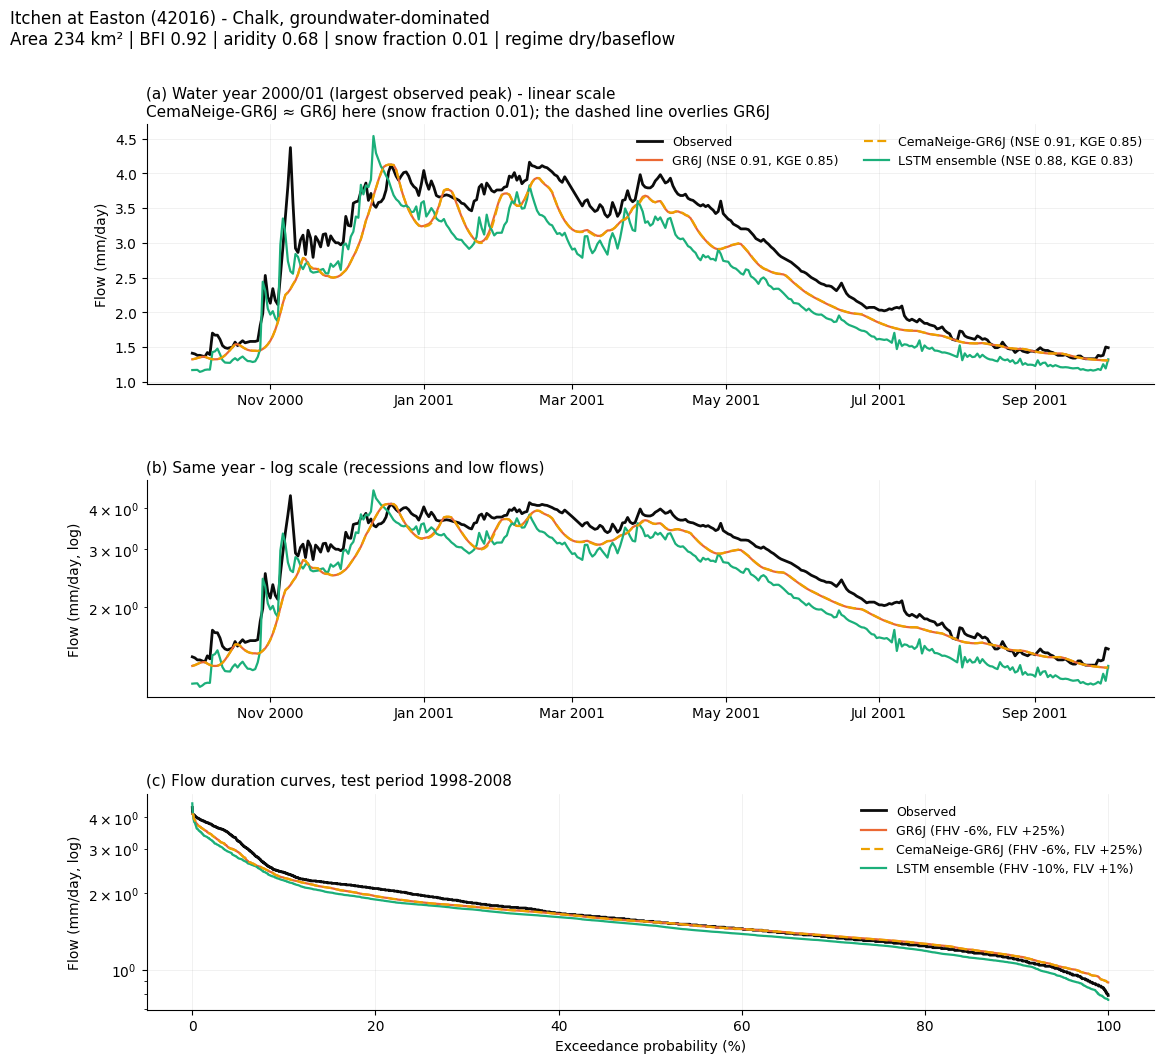

OK  42016 Itchen at Easton: water year 2000/01 (largest observed peak) -> saved


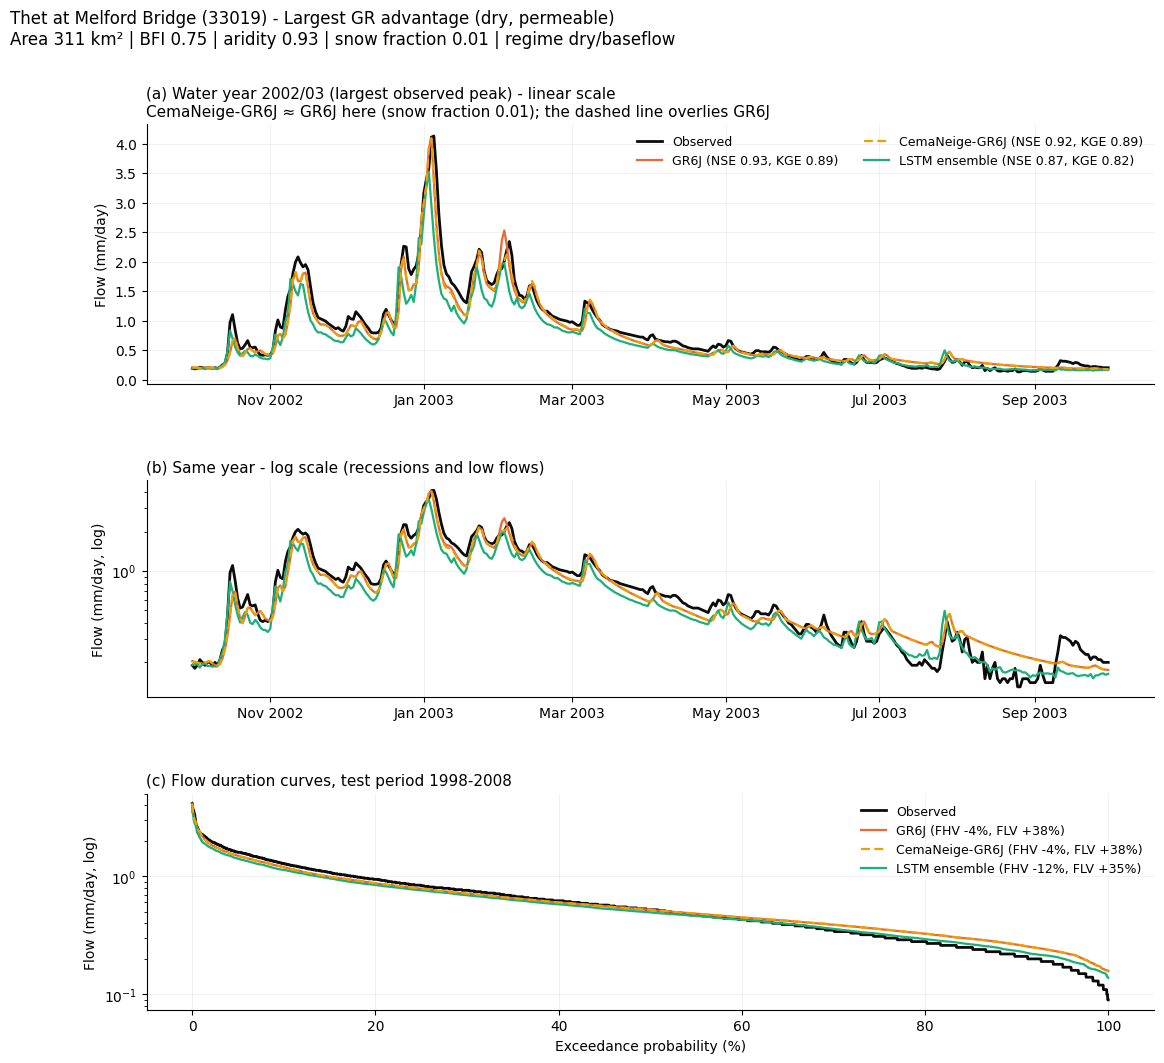

OK  33019 Thet at Melford Bridge: water year 2002/03 (largest observed peak) -> saved


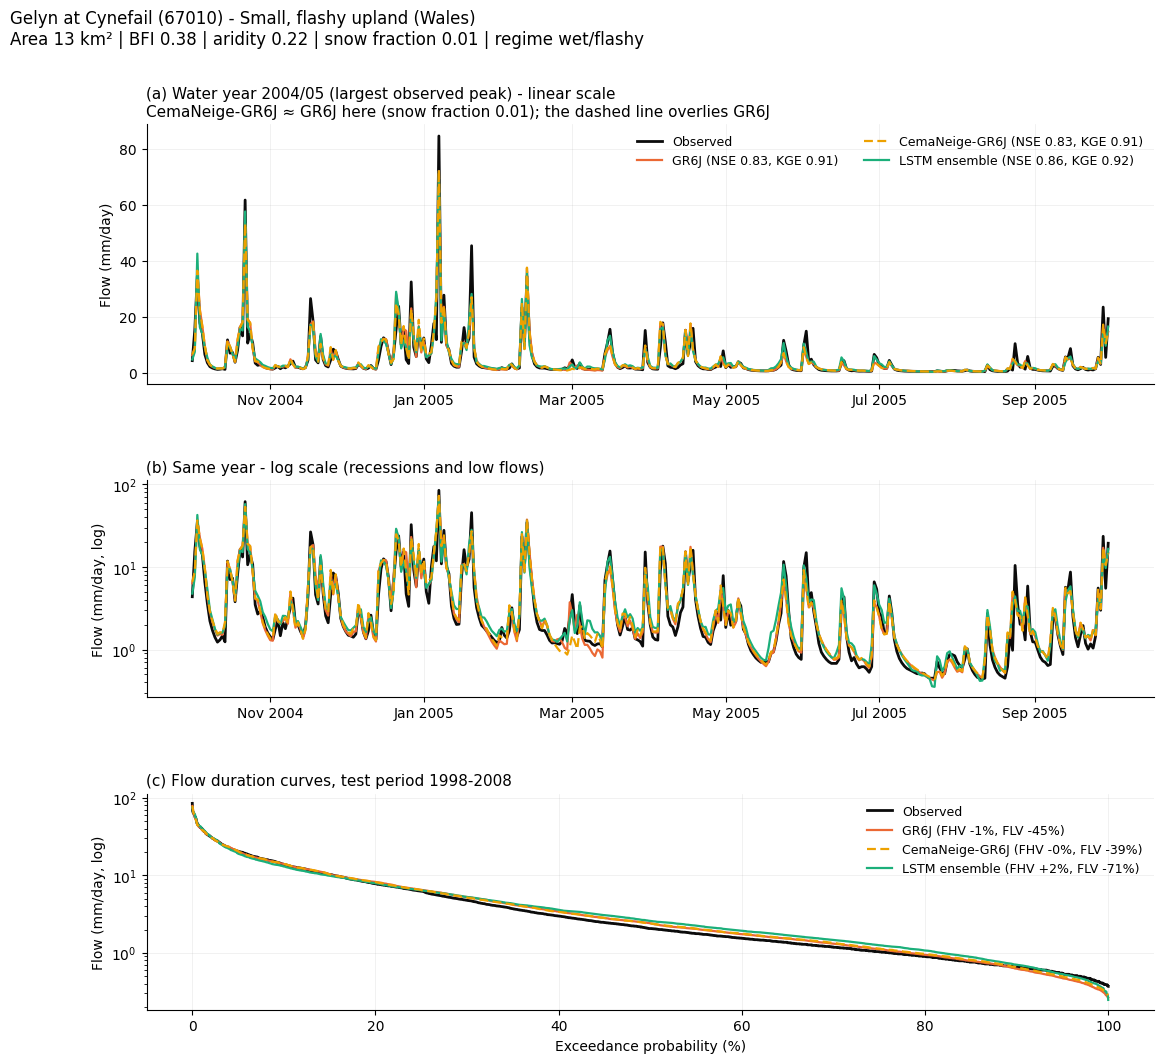

OK  67010 Gelyn at Cynefail: water year 2004/05 (largest observed peak) -> saved

gauge_id              catchment                                 story water_year                           why  NSE_GR6J  NSE_CemaNeigeGR6J  NSE_LSTM_ensemble
    7001  Findhorn at Shenachie          Snow-influenced (Cairngorms)    1999/00 largest spring (Mar-May) flow     0.544              0.715              0.810
   42016       Itchen at Easton          Chalk, groundwater-dominated    2000/01         largest observed peak     0.915              0.914              0.882
   33019 Thet at Melford Bridge Largest GR advantage (dry, permeable)    2002/03         largest observed peak     0.925              0.923              0.871
   67010      Gelyn at Cynefail          Small, flashy upland (Wales)    2004/05         largest observed peak     0.834              0.835              0.864

Figures saved in: /content/drive/MyDrive/rainfall_runoff_benchmark/outputs/comparison/case_studies


In [12]:
# =============================================================================
# CELL 21 - Case-study hydrographs: observed vs GR6J, CemaNeige-GR6J, LSTM ensemble
# Per catchment: (a) one water year, linear  (b) same year, log scale
#                (c) flow duration curves for the whole test period 1998-2008
# Water year: snowy catchments -> largest spring (Mar-May) flow; others -> largest peak
# Each catchment is wrapped in try/except so any error is printed in full
# =============================================================================
import traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
CMP_DIR = ROOT / "outputs/comparison"
OUT = CMP_DIR / "case_studies"
OUT.mkdir(parents=True, exist_ok=True)
TEST = ("1998-01-01", "2008-12-31")
FULL_WATER_YEARS = range(1999, 2009)        # 1998/99 ... 2007/08 (complete Oct-Sep years)
SNOWY = 0.05                                # frac_snow threshold for choosing a melt year

# --- Case studies (edit freely) ----------------------------------------------
CASES = {
    "7001":  "Snow-influenced (Cairngorms)",
    "42016": "Chalk, groundwater-dominated",
    "33019": "Largest GR advantage (dry, permeable)",
    "67010": "Small, flashy upland (Wales)",
}
# Optional manual override, e.g. {"7001": 2001} (2001 = Oct 2000 - Sep 2001)
WATER_YEAR = {}

# --- Models in legend order; colours fixed and CVD-checked -------------------
MODELS = {
    "GR6J":          {"label": "GR6J",           "color": "#eb6834", "ls": "-",
                      "file": lambda g: ROOT / f"outputs/gr_models/sim/GR6J_{g}.csv"},
    "CemaNeigeGR6J": {"label": "CemaNeige-GR6J", "color": "#eda100", "ls": (0, (4, 2)),
                      "file": lambda g: ROOT / f"outputs/gr_models/sim/CemaNeigeGR6J_{g}.csv"},
    "LSTM_ensemble": {"label": "LSTM ensemble",  "color": "#1baf7a", "ls": "-",
                      "file": lambda g: ROOT / f"outputs/lstm/sim/ensemble/{g}.csv"},
}
DRAW_ORDER = ["GR6J", "LSTM_ensemble", "CemaNeigeGR6J"]   # dashed line drawn last, on top
OBS_COLOR = "#0b0b0b"
NOTE_COLOR = "#52514e"

metrics = pd.read_csv(CMP_DIR / "metrics_test_all_models.csv", dtype={"gauge_id": str})
attrs = (pd.read_csv(ROOT / "outputs/catchment_selection/eligible_catchments.csv", dtype={"gauge_id": str})
           .set_index("gauge_id"))
clim = (pd.read_csv(ROOT / "data/camels_gb_v2/Catchment_Attributes/camels_gb_v2_climatic_attributes.csv",
                    dtype={"gauge_id": str}).set_index("gauge_id"))

def load_series(gid):
    """Observed + simulated daily flow (mm/day) for the test period, aligned by date."""
    out = None
    for key, m in MODELS.items():
        d = pd.read_csv(m["file"](gid), parse_dates=["date"]).set_index("date").loc[TEST[0]:TEST[1]]
        if out is None:
            out = d[["q_obs"]].copy()
        out[key] = d["q_sim"]
    return out

def water_year(index):
    """Water year label: Oct-Dec belong to the following year (Oct 2000 -> 2001)."""
    return (index + pd.offsets.DateOffset(months=3)).year

def choose_year(df, snow_frac):
    """Snowy: year with the largest mean Mar-May observed flow. Otherwise: largest peak."""
    wy = pd.Series(water_year(df.index), index=df.index)
    keep = wy.isin(FULL_WATER_YEARS)
    obs, wy = df.loc[keep, "q_obs"], wy[keep]
    if snow_frac >= SNOWY:
        spring = obs[obs.index.month.isin([3, 4, 5])]
        return int(spring.groupby(wy[spring.index]).mean().idxmax()), "largest spring (Mar-May) flow"
    return int(wy[obs.idxmax()]), "largest observed peak"

def fdc(q):
    """Flow duration curve: exceedance probability (%) and flows sorted high to low."""
    q = np.sort(q.dropna().to_numpy())[::-1]
    return 100 * np.arange(1, len(q) + 1) / (len(q) + 1), q

def style(ax):
    """Recessive grid and axes."""
    ax.grid(alpha=0.25, lw=0.5)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

def plot_lines(ax, x_obs, y_obs, series, label_fn=None):
    """Draw observed + models; return handles in legend order (Observed, then MODELS order)."""
    handles = {"obs": ax.plot(x_obs, y_obs, color=OBS_COLOR, lw=2, label="Observed")[0]}
    for k in DRAW_ORDER:
        x, y = series[k]
        v = MODELS[k]
        handles[k] = ax.plot(x, y, color=v["color"], ls=v["ls"], lw=1.6,
                             label=label_fn(k) if label_fn else v["label"])[0]
    return [handles["obs"]] + [handles[k] for k in MODELS]

summary = []
for gid, story in CASES.items():
    try:
        df = load_series(gid)
        a = attrs.loc[gid]
        snow_frac = float(clim.loc[gid, "frac_snow"])

        # --- choose the water year to display --------------------------------
        if gid in WATER_YEAR:
            year, why = WATER_YEAR[gid], "chosen manually"
        else:
            year, why = choose_year(df, snow_frac)
        sel = df[water_year(df.index) == year]

        m = metrics[metrics["gauge_id"] == gid].set_index("model")
        same_as_gr6j = abs(m.loc["CemaNeigeGR6J", "NSE"] - m.loc["GR6J", "NSE"]) < 0.005

        fig = plt.figure(figsize=(13, 11.5))
        gs = fig.add_gridspec(3, 1, height_ratios=[1.2, 1, 1], hspace=0.42)

        # (a) linear hydrograph - floods and timing
        ax1 = fig.add_subplot(gs[0])
        h = plot_lines(ax1, sel.index, sel["q_obs"],
                       {k: (sel.index, sel[k]) for k in MODELS},
                       lambda k: f"{MODELS[k]['label']} (NSE {m.loc[k, 'NSE']:.2f}, KGE {m.loc[k, 'KGE']:.2f})")
        ax1.legend(handles=h, frameon=False, ncol=2, fontsize=9, loc="upper right")
        title = f"(a) Water year {year-1}/{str(year)[-2:]} ({why}) - linear scale"
        if same_as_gr6j:
            title += (f"\nCemaNeige-GR6J ≈ GR6J here (snow fraction {snow_frac:.2f}); "
                      "the dashed line overlies GR6J")
        ax1.set_title(title, loc="left", fontsize=11)
        ax1.set_ylabel("Flow (mm/day)")
        ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        style(ax1)

        # (b) same year, log scale - recessions and low flows
        ax2 = fig.add_subplot(gs[1], sharex=ax1)
        plot_lines(ax2, sel.index, sel["q_obs"], {k: (sel.index, sel[k]) for k in MODELS})
        ax2.set_yscale("log")
        ax2.set_ylabel("Flow (mm/day, log)")
        ax2.set_title("(b) Same year - log scale (recessions and low flows)", loc="left", fontsize=11)
        style(ax2)

        # (c) flow duration curves, whole test period (days with observations only)
        ax3 = fig.add_subplot(gs[2])
        has_obs = df["q_obs"].notna()
        p_obs, q_obs = fdc(df["q_obs"])
        h = plot_lines(ax3, p_obs, q_obs,
                       {k: fdc(df.loc[has_obs, k]) for k in MODELS},
                       lambda k: f"{MODELS[k]['label']} (FHV {m.loc[k, 'FHV']:+.0f}%, FLV {m.loc[k, 'FLV']:+.0f}%)")
        ax3.legend(handles=h, frameon=False, fontsize=9, loc="upper right")
        ax3.set_yscale("log")
        ax3.set_xlabel("Exceedance probability (%)")
        ax3.set_ylabel("Flow (mm/day, log)")
        ax3.set_title("(c) Flow duration curves, test period 1998-2008", loc="left", fontsize=11)
        style(ax3)

        fig.suptitle(f"{a['gauge_name']} ({gid}) - {story}\n"
                     f"Area {a['area']:.0f} km² | BFI {a['baseflow_index']:.2f} | aridity {a['aridity']:.2f} | "
                     f"snow fraction {snow_frac:.2f} | regime {a['regime']}",
                     fontsize=12, x=0.02, ha="left")
        fig.savefig(OUT / f"case_{gid}.png", dpi=200, bbox_inches="tight")
        plt.show()
        print(f"OK  {gid} {a['gauge_name']}: water year {year-1}/{str(year)[-2:]} ({why}) -> saved")

        summary.append({"gauge_id": gid, "catchment": a["gauge_name"], "story": story,
                        "water_year": f"{year-1}/{str(year)[-2:]}", "why": why,
                        **{f"NSE_{k}": round(m.loc[k, "NSE"], 3) for k in MODELS}})
    except Exception:
        print(f"\nERROR in catchment {gid}:")
        traceback.print_exc()
        plt.close("all")

print()
print(pd.DataFrame(summary).to_string(index=False))
print(f"\nFigures saved in: {OUT}")

In [ ]:
# =============================================================================
# CELL 14 - Check one LSTM seed: validation log, test-period metrics, save sims
# Same metric function as GR4J/GR6J (neuralhydrology calculate_all_metrics)
# =============================================================================
import pickle
from pathlib import Path
import pandas as pd
from neuralhydrology.nh_run import eval_run
from neuralhydrology.evaluation.metrics import calculate_all_metrics

ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
RUN_DIR = ROOT / "outputs/lstm/runs"
SIM_DIR = ROOT / "outputs/lstm/sim"
SEED, EPOCH = 1, 30

run = sorted(RUN_DIR.glob(f"lstm_optionA_seed{SEED}_*"))[-1]       # latest run folder
print("Run folder:", run.name)

# --- Step 1: validation scores written during training -----------------------
print("\nValidation (1975-80, 100 random catchments):")
for line in (run / "output.log").read_text().splitlines():
    if "validation" in line.lower() and "nse" in line.lower():
        print("  ", line.split(": ", 1)[-1])

# --- Step 2: run the trained model on the test period (128 catchments) -------
res_file = run / "test" / f"model_epoch{EPOCH:03d}" / "test_results.p"
if not res_file.exists():
    eval_run(run_dir=run, period="test", epoch=EPOCH)
with open(res_file, "rb") as fh:
    results = pickle.load(fh)

# --- Step 3: metrics per catchment + save simulated series -------------------
out_dir = SIM_DIR / f"seed{SEED}"
out_dir.mkdir(parents=True, exist_ok=True)
rows = []
for gid, res in results.items():
    ds = res["1D"]["xr"].isel(time_step=-1)                      # predict_last_n = 1
    obs, sim = ds["discharge_spec_obs"], ds["discharge_spec_sim"]
    pd.DataFrame({"date": pd.to_datetime(ds["date"].values),
                  "q_obs": obs.values, "q_sim": sim.values}).to_csv(out_dir / f"{gid}.csv", index=False)
    rows.append({"gauge_id": str(gid), **calculate_all_metrics(obs, sim, resolution="1D")})

lstm = pd.DataFrame(rows)
lstm["model"] = f"LSTM_seed{SEED}"
print(f"\nTest catchments evaluated: {len(lstm)}")

# --- Step 4: compare with GR4J and GR6J (test period, same 128 catchments) ---
gr = pd.read_csv(ROOT / "outputs/gr_models/gr_metrics_optionA.csv", dtype={"gauge_id": str})
gr = gr[gr["period"] == "test"]
cols = ["NSE", "KGE", "Alpha-NSE", "Beta-KGE", "FHV", "FMS", "FLV", "Peak-Timing"]
both = pd.concat([gr[["model", "gauge_id"] + cols], lstm[["model", "gauge_id"] + cols]])
print("\nTest-period medians (1998-2008):")
print(both.groupby("model")[cols].median().round(3).T.to_string())

# catchment-by-catchment NSE: how often does this single seed beat each GR model?
piv = both.pivot(index="gauge_id", columns="model", values="NSE")
for m in ["GR4J", "GR6J"]:
    print(f"LSTM seed {SEED} NSE > {m} in {(piv[f'LSTM_seed{SEED}'] > piv[m]).sum()}/{len(piv)} catchments")

lstm.to_csv(ROOT / f"outputs/lstm/metrics_seed{SEED}_test.csv", index=False)

ModuleNotFoundError: No module named 'neuralhydrology'

**Option B**

In [13]:
%%writefile /content/drive/MyDrive/rainfall_runoff_benchmark/gr_run.R
# =============================================================================
# gr_run.R - Calibrate GR4J / GR6J / CemaNeigeGR4J / CemaNeigeGR6J with forcing A or B
# Protocol (unchanged): warm-up 1985-87 | calibration 1988-97 (NSE, Calibration_Michel)
# | test 1998-2008.  Forcing A: CEH-GEAR, CHESS-PE, CHESS-met T
#                    Forcing B: HadUK-Grid P, Hydro-PE, HadUK-Grid T
# Run with:  Rscript gr_run.R <model> <A|B>
# =============================================================================
suppressPackageStartupMessages(library(airGR))

args    <- commandArgs(trailingOnly = TRUE)
model   <- args[1]
forcing <- args[2]
stopifnot(model %in% c("GR4J", "GR6J", "CemaNeigeGR4J", "CemaNeigeGR6J"), forcing %in% c("A", "B"))

FUN  <- switch(model, GR4J = RunModel_GR4J, GR6J = RunModel_GR6J,
               CemaNeigeGR4J = RunModel_CemaNeigeGR4J, CemaNeigeGR6J = RunModel_CemaNeigeGR6J)
snow <- grepl("CemaNeige", model)
FORCING <- list(A = c(P = "precipitation_cehgear", E = "pet_chess",   T = "temperature_chess"),
                B = c(P = "precipitation_haduk",   E = "pet_hydrope", T = "temperature_haduk"))
fv <- FORCING[[forcing]]

# --- Paths (Option B results kept in their own folder) -----------------------
root      <- "/content/drive/MyDrive/rainfall_runoff_benchmark"
daily_dir <- file.path(root, "data/camels_gb_v2/Catchment_Timeseries/hydro-meteorological/daily")
out_dir   <- file.path(root, if (forcing == "A") "outputs/gr_models" else "outputs/gr_models_optionB")
dir.create(file.path(out_dir, "sim"),    recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(out_dir, "params"), recursive = TRUE, showWarnings = FALSE)

gauges <- as.character(read.csv(file.path(root, "outputs/catchment_selection/eligible_catchments.csv"))$gauge_id)
files  <- list.files(daily_dir, pattern = "\\.csv$", full.names = TRUE)
names(files) <- sub(".*timeseries_([0-9]+)_.*", "\\1", basename(files))

# --- Hypsometry for CemaNeige (interpolated from CAMELS-GB elevation values) --
topo <- read.csv(file.path(root, "data/camels_gb_v2/Catchment_Attributes/camels_gb_v2_topographic_attributes.csv"))
topo$gauge_id <- as.character(topo$gauge_id)
hypso_for <- function(gid) {
  r <- topo[topo$gauge_id == gid, ]
  approx(x = c(0, 10, 50, 90, 100),
         y = c(r$elev_min, r$elev_10, r$elev_50, r$elev_90, r$elev_max), xout = 0:100)$y
}

# --- Periods and metrics -----------------------------------------------------
P_WARM  <- c("1985-01-01", "1987-12-31")
P_TRAIN <- c("1988-01-01", "1997-12-31")
P_TEST  <- c("1998-01-01", "2008-12-31")
nse <- function(s, o) { k <- !is.na(s) & !is.na(o)
  1 - sum((s[k] - o[k])^2) / sum((o[k] - mean(o[k]))^2) }
kge <- function(s, o) { k <- !is.na(s) & !is.na(o)            # Gupta et al. (2009)
  r <- cor(s[k], o[k]); a <- sd(s[k]) / sd(o[k]); b <- mean(s[k]) / mean(o[k])
  1 - sqrt((r - 1)^2 + (a - 1)^2 + (b - 1)^2) }

cat(sprintf("=== %s | forcing %s: P=%s, E=%s%s ===\n", model, forcing, fv["P"], fv["E"],
            if (snow) paste0(", T=", fv["T"]) else ""))

# --- Loop over catchments ----------------------------------------------------
t_all <- Sys.time()
for (i in seq_along(gauges)) {
  gid <- gauges[i]
  par_file <- file.path(out_dir, "params", paste0(model, "_", gid, ".csv"))
  if (file.exists(par_file)) { cat(sprintf("[%3d/%d] %s %-7s already done - skipped\n",
                                           i, length(gauges), model, gid)); next }
  t0 <- Sys.time()
  res <- tryCatch({
    d <- read.csv(files[[gid]])
    d$date <- as.POSIXct(substr(d$date, 1, 10), tz = "UTC")
    d <- d[d$date >= as.POSIXct(P_WARM[1], tz = "UTC") &
           d$date <= as.POSIXct(P_TEST[2], tz = "UTC"), ]
    idx <- function(p) which(d$date >= as.POSIXct(p[1], tz = "UTC") &
                             d$date <= as.POSIXct(p[2], tz = "UTC"))
    i_warm <- idx(P_WARM); i_train <- idx(P_TRAIN); i_test <- idx(P_TEST)
    i_all  <- c(i_train, i_test)

    # model inputs (temperature + elevation layers only for CemaNeige)
    if (snow) {
      inputs <- CreateInputsModel(FUN_MOD = FUN, DatesR = d$date,
                                  Precip = d[[fv["P"]]], PotEvap = d[[fv["E"]]],
                                  TempMean = d[[fv["T"]]], HypsoData = hypso_for(gid),
                                  NLayers = 5, verbose = FALSE)
    } else {
      inputs <- CreateInputsModel(FUN_MOD = FUN, DatesR = d$date,
                                  Precip = d[[fv["P"]]], PotEvap = d[[fv["E"]]])
    }

    # calibration on 1988-97, maximising NSE
    run_cal  <- suppressWarnings(CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                 IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_train, verbose = FALSE))
    crit_cal <- CreateInputsCrit(FUN_CRIT = ErrorCrit_NSE, InputsModel = inputs,
                                 RunOptions = run_cal, Obs = d$discharge_spec[i_train])
    cal <- Calibration_Michel(InputsModel = inputs, RunOptions = run_cal, InputsCrit = crit_cal,
                              CalibOptions = CreateCalibOptions(FUN_MOD = FUN),
                              FUN_MOD = FUN, verbose = FALSE)
    par <- cal$ParamFinalR

    # continuous run 1988-2008 with calibrated parameters
    run_all <- suppressWarnings(CreateRunOptions(FUN_MOD = FUN, InputsModel = inputs,
                                IndPeriod_WarmUp = i_warm, IndPeriod_Run = i_all, verbose = FALSE))
    sim <- FUN(InputsModel = inputs, RunOptions = run_all, Param = par)$Qsim
    obs <- d$discharge_spec[i_all]
    tr  <- seq_along(i_train); te <- (length(i_train) + 1):length(i_all)

    write.csv(data.frame(date = format(d$date[i_all], "%Y-%m-%d"), q_obs = obs, q_sim = sim),
              file.path(out_dir, "sim", paste0(model, "_", gid, ".csv")), row.names = FALSE)
    out <- data.frame(gauge_id = gid, model = model, forcing = forcing,
                      nse_train = nse(sim[tr], obs[tr]), kge_train = kge(sim[tr], obs[tr]),
                      nse_test  = nse(sim[te], obs[te]), kge_test  = kge(sim[te], obs[te]))
    out[paste0("X", seq_along(par))] <- as.list(par)
    write.csv(out, par_file, row.names = FALSE)
    sprintf("test NSE = %.3f, KGE = %.3f", out$nse_test, out$kge_test)
  }, error = function(e) paste("ERROR:", conditionMessage(e)))

  cat(sprintf("[%3d/%d] %s %-7s %5.1f s  %s\n", i, length(gauges), model, gid,
              as.numeric(difftime(Sys.time(), t0, units = "secs")), res))
  flush.console()
}
cat(sprintf("%s (forcing %s) finished in %.1f min\n\n", model, forcing,
            as.numeric(difftime(Sys.time(), t_all, units = "mins"))))

Writing /content/drive/MyDrive/rainfall_runoff_benchmark/gr_run.R


In [14]:
# =============================================================================
# CELL 23 - Launch GR4J, GR6J, CemaNeigeGR4J, CemaNeigeGR6J (Option B) as one
# background job on the CPU; progress goes to a log file on Drive
# =============================================================================
import subprocess
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
LOG = ROOT / "outputs/gr_models_optionB_log.txt"

# airGR for command-line R (installs once per session)
!Rscript -e 'if (!requireNamespace("airGR", quietly=TRUE)) install.packages("airGR", repos="https://cloud.r-project.org", quiet=TRUE)'

script = ROOT / "gr_run.R"
cmd = " && ".join(f"Rscript '{script}' {m} B" for m in
                  ["GR4J", "GR6J", "CemaNeigeGR4J", "CemaNeigeGR6J"])
gr_job = subprocess.Popen(cmd, shell=True, stdout=open(LOG, "w"), stderr=subprocess.STDOUT)
print(f"GR Option B started (PID {gr_job.pid}). Log: {LOG}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GR Option B started (PID 99201). Log: /content/drive/MyDrive/rainfall_runoff_benchmark/outputs/gr_models_optionB_log.txt


In [15]:
# =============================================================================
# CELL 24 - Train the LSTM ensemble with Option B forcing (HadUK-Grid P and T,
# Hydro-PE PET). All other settings identical to Option A (Lees et al., 2021)
# Each seed saved to Drive; completed seeds are skipped automatically
# =============================================================================
!pip install -q neuralhydrology

from pathlib import Path
import pandas as pd
import torch
from google.colab import drive
from neuralhydrology.nh_run import start_run

drive.mount("/content/drive")

# --- Paths -------------------------------------------------------------------
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
NH = ROOT / "data/nh_camels_gb_v2"                 # converted data (from Cell 12)
RUN_DIR = ROOT / "outputs/lstm/runs"
CFG_DIR = ROOT / "outputs/lstm/configs"
RUN_DIR.mkdir(parents=True, exist_ok=True)
CFG_DIR.mkdir(parents=True, exist_ok=True)

# --- Option B forcing --------------------------------------------------------
OPTION = "B"
DYNAMIC = ["precipitation_haduk", "pet_hydrope", "temperature_haduk"]

# --- Seeds -------------------------------------------------------------------
ALL_SEEDS = [1, 2, 3, 4, 5, 6, 7, 8]
SEEDS_THIS_SESSION = [1, 2, 3, 4, 5, 6, 7, 8]      # change if you split across sessions
EPOCHS = 30

# --- Checks ------------------------------------------------------------------
assert torch.cuda.is_available(), "No GPU - set Runtime > Change runtime type > GPU"
assert (NH / "attributes/static_attributes.csv").exists(), "Converted data missing - run Cell 12"
print("GPU:", torch.cuda.get_device_name(0))

static_list = pd.read_csv(NH / "attributes/static_attributes.csv", nrows=1).columns[1:].tolist()

def write_config(seed):
    """YAML config for one ensemble member (identical to Option A except inputs/name)."""
    yml = f"""
# --- experiment ---
experiment_name: lstm_option{OPTION}_seed{seed}
run_dir: {RUN_DIR}
seed: {seed}
device: cuda:0

# --- basins and periods (Lees et al., 2021) ---
train_basin_file: {ROOT}/outputs/lstm/basins_train.txt
validation_basin_file: {ROOT}/outputs/lstm/basins_train.txt
test_basin_file: {ROOT}/outputs/lstm/basins_test_128.txt
train_start_date: '01/01/1988'
train_end_date: '31/12/1997'
validation_start_date: '01/01/1975'
validation_end_date: '31/12/1980'
test_start_date: '01/01/1998'
test_end_date: '31/12/2008'

# --- validation monitoring (does not change training) ---
validate_every: 5
validate_n_random_basins: 100
metrics: [NSE]
save_validation_results: False

# --- model (Lees et al., 2021) ---
model: cudalstm
head: regression
output_activation: linear
hidden_size: 64
initial_forget_bias: 3
output_dropout: 0.4

# --- training ---
optimizer: Adam
loss: NSE
learning_rate:
  0: 1e-3
  10: 5e-4
  25: 1e-4
batch_size: 256
epochs: {EPOCHS}
clip_gradient_norm: 1
predict_last_n: 1
seq_length: 365
num_workers: 2
log_interval: 5
log_tensorboard: False
log_n_figures: 0
save_weights_every: 5

# --- data (Option {OPTION} forcing) ---
dataset: generic
data_dir: {NH}
dynamic_inputs: {DYNAMIC}
target_variables: [discharge_spec]
clip_targets_to_zero: [discharge_spec]
static_attributes: {static_list}
"""
    path = CFG_DIR / f"lstm_option{OPTION}_seed{seed}.yml"
    path.write_text(yml)
    return path

def seed_done(seed):
    """A seed is complete if a run folder holds the final-epoch weights."""
    return any((d / f"model_epoch{EPOCHS:03d}.pt").exists()
               for d in RUN_DIR.glob(f"lstm_option{OPTION}_seed{seed}_*"))

# --- Train the seeds for this session (one after another) --------------------
for seed in SEEDS_THIS_SESSION:
    if seed_done(seed):
        print(f"Seed {seed}: already trained - skipped")
        continue
    print(f"\n===== Training Option {OPTION}, seed {seed} =====")
    start_run(config_file=write_config(seed))

print(f"\nOption {OPTION} status:", {s: ("done" if seed_done(s) else "pending") for s in ALL_SEEDS})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4

===== Training Option B, seed 1 =====
# Validation:  21%|██        | 21/100 [00:05<00:51,  1.55it/s]

# Validation:  26%|██▌       | 26/100 [00:06<00:20,  3.53it/s]

# Validation:  29%|██▉       | 29/100 [00:07<00:18,  3.74it/s]

# Validation:  51%|█████     | 51/100 [00:13<00:13,  3.76it/s]

# Validation:  52%|█████▏    | 52/100 [00:13<00:17,  2.80it/s]

# Validation:  81%|████████  | 81/100 [00:21<00:06,  3.05it/s]

... (413 outputs left out)

# Validation:  15%|█▌        | 15/100 [00:03<00:28,  3.03it/s]

# Validation:  59%|█████▉    | 59/100 [00:14<00:07,  5.75it/s]

# Validation:  87%|████████▋ | 87/100 [00:20<00:02,  6.34it/s]

# Validation: 100%|██████████| 100/100 [00:25<00:00,  3.93it/s]

Option B status: {1: 'done', 2: 'done', 3: 'done', 4: 'done', 5: 'done', 6: 'done', 7: 'done', 8: 'done'}


**Model evaluation**

In [1]:
# =============================================================================
# CELL 25 - Option B evaluation: GR4J, GR6J, CemaNeige-GR4J/-GR6J and the 8-seed
# LSTM ensemble on the test period (1998-2008), same metric code as Option A
# =============================================================================
!pip install -q neuralhydrology

import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from google.colab import drive
from neuralhydrology.nh_run import eval_run
from neuralhydrology.evaluation.metrics import calculate_all_metrics

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/rainfall_runoff_benchmark")
GR_B = ROOT / "outputs/gr_models_optionB"
RUN_DIR = ROOT / "outputs/lstm/runs"
SIM_B = ROOT / "outputs/lstm/sim_optionB"
CMP_DIR = ROOT / "outputs/comparison"
TEST = ("1998-01-01", "2008-12-31")
GR_MODELS = ["GR4J", "GR6J", "CemaNeigeGR4J", "CemaNeigeGR6J"]
SEEDS, EPOCH = range(1, 9), 30

def nh_metrics(dates, obs, sim):
    """All neuralhydrology metrics for one observed/simulated series."""
    o = xr.DataArray(np.asarray(obs), coords={"date": pd.to_datetime(dates)}, dims=["date"])
    s = xr.DataArray(np.asarray(sim), coords={"date": pd.to_datetime(dates)}, dims=["date"])
    return calculate_all_metrics(o, s, resolution="1D")

# --- Step 1: GR models (Option B) - completeness check and test metrics ------
rows = []
for m in GR_MODELS:
    files = sorted((GR_B / "sim").glob(f"{m}_*.csv"))
    print(f"{m:<15} Option B simulations: {len(files)}/128")
    for f in files:
        gid = f.stem.split("_", 1)[1]
        d = pd.read_csv(f, parse_dates=["date"]).set_index("date").loc[TEST[0]:TEST[1]]
        rows.append({"model": m, "gauge_id": gid, **nh_metrics(d.index, d["q_obs"], d["q_sim"])})

# --- Step 2: evaluate each Option B LSTM seed on the test period -------------
def finished_run(seed):
    runs = [d for d in sorted(RUN_DIR.glob(f"lstm_optionB_seed{seed}_*"))
            if (d / f"model_epoch{EPOCH:03d}.pt").exists()]
    if not runs:
        raise FileNotFoundError(f"No finished Option B run for seed {seed}")
    return runs[-1]

for seed in SEEDS:
    out_dir = SIM_B / f"seed{seed}"
    if out_dir.exists() and len(list(out_dir.glob("*.csv"))) >= 128:
        print(f"Seed {seed}: simulations already saved")
        continue
    run = finished_run(seed)
    res_file = run / "test" / f"model_epoch{EPOCH:03d}" / "test_results.p"
    if not res_file.exists():
        eval_run(run_dir=run, period="test", epoch=EPOCH)
    with open(res_file, "rb") as fh:
        results = pickle.load(fh)
    out_dir.mkdir(parents=True, exist_ok=True)
    for gid, res in results.items():
        ds = res["1D"]["xr"].isel(time_step=-1)                  # predict_last_n = 1
        pd.DataFrame({"date": pd.to_datetime(ds["date"].values),
                      "q_obs": ds["discharge_spec_obs"].values,
                      "q_sim": ds["discharge_spec_sim"].values}
                     ).to_csv(out_dir / f"{gid}.csv", index=False)
    print(f"Seed {seed}: {len(results)} catchments evaluated")

# --- Step 3: ensemble = mean of the 8 seeds; metrics for seeds and ensemble --
(SIM_B / "ensemble").mkdir(parents=True, exist_ok=True)
for gid in sorted(p.stem for p in (SIM_B / "seed1").glob("*.csv")):
    seeds_df = [pd.read_csv(SIM_B / f"seed{s}" / f"{gid}.csv", parse_dates=["date"]).set_index("date")
                for s in SEEDS]
    ens = seeds_df[0][["q_obs"]].copy()
    ens["q_sim"] = pd.concat([d["q_sim"] for d in seeds_df], axis=1).mean(axis=1)
    ens.reset_index().to_csv(SIM_B / "ensemble" / f"{gid}.csv", index=False)
    rows.append({"model": "LSTM_ensemble", "gauge_id": gid,
                 **nh_metrics(ens.index, ens["q_obs"], ens["q_sim"])})
    for s, d in zip(SEEDS, seeds_df):
        rows.append({"model": f"LSTM_seed{s}", "gauge_id": gid,
                     **nh_metrics(d.index, d["q_obs"], d["q_sim"])})

# --- Step 4: save and summarise ---------------------------------------------
met_b = pd.DataFrame(rows)
met_b["forcing"] = "B"
met_b.to_csv(CMP_DIR / "metrics_test_optionB.csv", index=False)

MAIN = GR_MODELS + ["LSTM_ensemble"]
cols = ["NSE", "KGE", "Pearson-r", "FHV", "FMS", "FLV", "Peak-Timing"]
print("\nOption B - test-period medians (1998-2008):")
print(met_b[met_b["model"].isin(MAIN)].groupby("model")[cols].median().reindex(MAIN).round(3).T.to_string())
seed_nse = met_b[met_b["model"].str.startswith("LSTM_seed")].groupby("model")["NSE"].median()
print(f"\nSingle-seed median NSE (B): {seed_nse.min():.3f} - {seed_nse.max():.3f}")

Mounted at /content/drive
GR4J            Option B simulations: 128/128
GR6J            Option B simulations: 128/128
CemaNeigeGR4J   Option B simulations: 128/128
CemaNeigeGR6J   Option B simulations: 128/128
# Evaluation: 100%|██████████| 128/128 [01:22<00:00,  1.55it/s]
Seed 1: 128 catchments evaluated
# Evaluation: 100%|██████████| 128/128 [00:31<00:00,  4.01it/s]
Seed 2: 128 catchments evaluated
# Evaluation: 100%|██████████| 128/128 [00:32<00:00,  3.91it/s]
Seed 3: 128 catchments evaluated
# Evaluation: 100%|██████████| 128/128 [00:32<00:00,  3.99it/s]
Seed 4: 128 catchments evaluated
# Evaluation: 100%|██████████| 128/128 [00:32<00:00,  3.95it/s]
Seed 5: 128 catchments evaluated
# Evaluation: 100%|██████████| 128/128 [00:33<00:00,  3.86it/s]
Seed 6: 128 catchments evaluated
# Evaluation: 100%|██████████| 128/128 [00:32<00:00,  3.92it/s]
Seed 7: 128 catchments evaluated
# Evaluation: 100%|██████████| 128/128 [00:33<00:00,  3.88it/s]
Seed 8: 128 catchments evaluated

Option B - te

**Sensitivity Analysis**

In [2]:
# =============================================================================
# CELL 26 - Sensitivity to forcing data: Option A (CEH-GEAR + CHESS-PE) vs
# Option B (HadUK-Grid + Hydro-PE). Same catchments, periods and metrics.
# =============================================================================
from scipy.stats import wilcoxon, spearmanr
from statsmodels.stats.multitest import multipletests

MAIN = ["GR4J", "GR6J", "CemaNeigeGR4J", "CemaNeigeGR6J", "LSTM_ensemble"]
met_a = pd.read_csv(CMP_DIR / "metrics_test_all_models.csv", dtype={"gauge_id": str})
met_a["forcing"] = "A"
met_b = pd.read_csv(CMP_DIR / "metrics_test_optionB.csv", dtype={"gauge_id": str})
both = pd.concat([met_a, met_b], ignore_index=True)
both = both[both["model"].isin(MAIN)]
info = met_a.drop_duplicates("gauge_id").set_index("gauge_id")[["gauge_name", "regime"]]

# --- 1. Medians side by side -------------------------------------------------
print("Median test metrics by forcing option:")
for metric in ["NSE", "KGE", "FHV", "FLV", "Peak-Timing"]:
    t = both.pivot_table(index="model", columns="forcing", values=metric, aggfunc="median").reindex(MAIN)
    t["B - A"] = t["B"] - t["A"]
    print(f"\n{metric}:\n{t.round(3).to_string()}")

# --- 2. Does the ranking hold within Option B? (paired NSE, Holm) ------------
nse_b = met_b[met_b["model"].isin(MAIN)].pivot(index="gauge_id", columns="model", values="NSE")
pairs = [("LSTM_ensemble", "GR6J"), ("LSTM_ensemble", "CemaNeigeGR6J"),
         ("CemaNeigeGR6J", "GR6J"), ("GR6J", "GR4J")]
tests = []
for a, b in pairs:
    g = (nse_b[a] - nse_b[b]).dropna()
    tests.append({"comparison (Option B)": f"{a} vs {b}", "a_better_in": f"{(g > 0).sum()}/{len(g)}",
                  "median_gain": g.median(), "p_raw": wilcoxon(g[g != 0]).pvalue})
tests = pd.DataFrame(tests)
tests["p_holm"] = multipletests(tests["p_raw"], method="holm")[1]
print("\nPaired NSE comparisons within Option B:")
print(tests.round(4).to_string(index=False))

# --- 3. How much does each model change from A to B? -------------------------
rows = []
for m in MAIN:
    w = both[both["model"] == m].pivot(index="gauge_id", columns="forcing", values="NSE").dropna()
    d = w["B"] - w["A"]
    rho, _ = spearmanr(w["A"], w["B"])
    rows.append({"model": m, "median_dNSE_(B-A)": d.median(), "B_better_in": f"{(d > 0).sum()}/{len(d)}",
                 "p_wilcoxon": wilcoxon(d[d != 0]).pvalue,
                 "spearman_rho_A_vs_B": rho})
print("\nChange in NSE from Option A to Option B (same catchments):")
print(pd.DataFrame(rows).round(4).to_string(index=False))

# --- 4. Best model per catchment: same answer under A and B? -----------------
best = {}
for opt in ["A", "B"]:
    w = both[both["forcing"] == opt].pivot(index="gauge_id", columns="model", values="NSE")
    best[opt] = w[["GR4J", "GR6J", "LSTM_ensemble"]].idxmax(axis=1)       # as in the main maps
agree = (best["A"] == best["B"]).mean()
print(f"\nBest model (GR4J/GR6J/LSTM) by NSE - counts:\n"
      f"{pd.DataFrame({'A': best['A'].value_counts(), 'B': best['B'].value_counts()}).fillna(0).astype(int)}")
print(f"Same best model under A and B in {100 * agree:.0f}% of catchments")

# --- 5. Regimes and the snow finding under Option B --------------------------
print("\nMedian test NSE by regime, Option B:")
print(met_b[met_b["model"].isin(MAIN)].merge(info, left_on="gauge_id", right_index=True)
      .pivot_table(index="regime", columns="model", values="NSE", aggfunc="median")[MAIN].round(3).to_string())

clim = pd.read_csv(ROOT / "data/camels_gb_v2/Catchment_Attributes/camels_gb_v2_climatic_attributes.csv",
                   dtype={"gauge_id": str}).set_index("gauge_id")
snow = clim["frac_snow"].reindex(nse_b.index)
gap_no_snow = nse_b["LSTM_ensemble"] - nse_b[["GR4J", "GR6J"]].max(axis=1)
gap_snow = nse_b["LSTM_ensemble"] - nse_b[["CemaNeigeGR4J", "CemaNeigeGR6J"]].max(axis=1)
print("\nOption B - Spearman correlation of the LSTM advantage with frac_snow:")
for name, s in [("vs GR without snow module", gap_no_snow), ("vs GR with snow module", gap_snow)]:
    rho, p = spearmanr(snow, s)
    print(f"  {name:<28} rho = {rho:+.2f} (p = {p:.3g})")

pd.DataFrame(rows).to_csv(CMP_DIR / "sensitivity_A_vs_B.csv", index=False)
print(f"\nSaved: {CMP_DIR / 'sensitivity_A_vs_B.csv'}")

Median test metrics by forcing option:

NSE:
forcing            A      B  B - A
model                             
GR4J           0.863  0.851 -0.012
GR6J           0.863  0.851 -0.012
CemaNeigeGR4J  0.868  0.864 -0.004
CemaNeigeGR6J  0.869  0.866 -0.003
LSTM_ensemble  0.885  0.878 -0.007

KGE:
forcing            A      B  B - A
model                             
GR4J           0.870  0.862 -0.008
GR6J           0.873  0.861 -0.012
CemaNeigeGR4J  0.878  0.880  0.002
CemaNeigeGR6J  0.882  0.881 -0.001
LSTM_ensemble  0.872  0.861 -0.011

FHV:
forcing             A       B  B - A
model                               
GR4J          -11.633 -11.703 -0.070
GR6J          -10.839 -11.154 -0.315
CemaNeigeGR4J  -9.833  -9.114  0.719
CemaNeigeGR6J -10.050  -9.270  0.780
LSTM_ensemble -11.032 -12.157 -1.126

FLV:
forcing             A       B   B - A
model                                
GR4J          -35.468 -29.830   5.637
GR6J           -8.776   2.097  10.874
CemaNeigeGR4J -40.810 -33.333   7.47